# PHASE 0 — FDIC Research Design & Full-History Source Audit
### Research preparation and acquisition contract, **not** train/validation/test selection

**Scope:** FDIC Financials historical source coverage from the **earliest** to the **latest** available FDIC Financials API quarter when Phase 1 is executed. Phase 0 probes source/schema checkpoints across the entire known history; Phase 1 acquires and profiles **every available quarter**. Archived failure and institution tables are not truncated to a 2012 cutoff.

**Boundary:** No model fitting, predictive metrics, temporal cohort split or evaluation-period designation in Phase 0. Source audits on full history are legitimate engineering diagnostics, **not** permission to choose predictive features or thresholds using future outcomes. Chronological validation, embargo, label maturity and later holdout design belong to Phase 2/5 after the risk set is audited.

**Coverage caveat:** Historical source probes may include 1984, but the institution-level Financials endpoint may start later; that distinction is tested when Phase 1 runs.

## Provenance note
Existing notebook outputs and previous pilot statistics may describe earlier runs. This revised notebook clears execution outputs; only values produced during a fresh run constitute current-run evidence. Phase 0 raw-source archives must preserve full source history and incomplete/invalid event records for adjudication.

## 1. Repository & research evidence

**Research question and decision boundary.** Can each dataset and decision be traced to a named source and repeatable environment? These steps establish provenance, not financial results.

In [128]:
# 1.1 | Initialize project and locate repository
import csv
import importlib.util
import platform
import shutil
import sys
from pathlib import Path

CWD = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        folder for folder in (CWD, *CWD.parents)
        if all((folder / name).is_dir()
               for name in ("notebooks", "docs", "data"))
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Mở dự án trong VS Code, hoặc khởi động kernel từ thư mục "
        "dự án hay thư mục notebooks/ bên trong."
    )

print("Project root:", PROJECT_ROOT)

PROJECT_ROOT.mkdir(parents=True, exist_ok=True)

# Rerun control: set True when you intentionally want fresh FDIC API data.
REFRESH_API = False
P0_REFRESH_REFERENCE_SOURCES = True  # Full source events/institutions: refresh live while retaining immutable snapshots

Project root: C:\học tập\kì 7\Big data\Final\Bản nháp


#### 1.1 — Initialize project and locate repository

**Interpretation & verification.** The root resolver defines the single repository location used by every later block. Verify that `PROJECT_ROOT` points to the BFT65B project—not the notebooks folder—before permitting any write operations.

In [129]:
# 1.2 | Create repository folders
folders = [
    "configs",
    "src",
    "tests",
    "notebooks",
    "data/raw",
    "data/clean",
    "data/features",
    "docs",
    "outputs/tables",
    "outputs/figures",
    "outputs/benchmarks",
    "report",
]

for folder in folders:
    path = PROJECT_ROOT / folder
    path.mkdir(parents=True, exist_ok=True)

    # Keep non-data directories visible to Git
    if not folder.startswith("data/"):
        (path / ".gitkeep").touch(exist_ok=True)

#### 1.2 — Create repository folders

**Interpretation & verification.** The expected directories separate source snapshots, analytical outputs, documentation and tests. They are infrastructure assertions, not evidence of the validity of a banking variable; inspect the path listing before extraction.

In [130]:
# 1.3 | Initialize .gitignore
gitignore = """\
data/
data_raw/
*.parquet
*.csv.tmp
__pycache__/
*.pyc
.ipynb_checkpoints/
.venv/
venv/
.env
.DS_Store
"""

gitignore_path = PROJECT_ROOT / ".gitignore"
if not gitignore_path.exists():
    gitignore_path.write_text(
        gitignore, encoding="utf-8"
    )

#### 1.3 — Initialize .gitignore

**Interpretation & verification.** The ignore rules protect transient artifacts and large datasets from accidental Git commits. Check that configs, schema documentation and audit manifests remain version-controlled even when raw datasets are excluded.

In [131]:
# 1.4 | Create README if absent
readme_path = PROJECT_ROOT / "README.md"

if not readme_path.exists():
    readme_path.write_text(
        """# FDIC Bank Failure Early Warning System

## Project
BFT65B - Big Data Analytics in Finance

## Objective
Build a reproducible, point-in-time-controlled
big-data pipeline for one-year-ahead US bank
failure early warning.

## Data Sources
- FDIC BankFind Financials API
- FDIC Bank Failures API
- FDIC Institutions API

## Technology
Python, pandas, Polars, PyArrow,
PySpark and scikit-learn.

## Project Phases
0. Research and methodology
1. Acquisition and storage
2. Data quality and panel
3. Scalable processing
4. Feature engineering
5. Modelling and validation
6. Reporting and reproducibility

## Research
See docs/research_matrix.csv

## Reproducibility
Installation and execution instructions
will be completed after pipeline validation.

## Academic Integrity
Research, code and AI-assisted contributions
will be documented and cited.
""",
        encoding="utf-8"
    )

#### 1.4 — Create README if absent

**Interpretation & verification.** Creating a README only if absent prevents overwriting research documentation. This step makes the repository navigable; it should not be counted as a substantive empirical test.

In [132]:
# 1.5 | Dependency specification
req_path = PROJECT_ROOT / "requirements.in"

if not req_path.exists():
    req_path.write_text(
        """requests
pandas
numpy
polars
pyarrow
scikit-learn
pyspark
matplotlib
psutil
pytest
pyyaml
""",
        encoding="utf-8"
    )

#### 1.5 — Dependency specification

**Interpretation & verification.** This records runtime dependencies. The earlier environment audit found `polars`, `pyarrow`, `pyspark` and `pytest` missing; install and verify required packages before running a clean reproducibility test.

In [ ]:
# 1.6 | Import the submitted Phase 0 literature matrix
research_target = PROJECT_ROOT / "docs" / "research_matrix.csv"
with research_target.open(encoding="utf-8-sig", newline="") as matrix:
    reader = csv.DictReader(matrix)
    records = list(reader)
    column_names = reader.fieldnames

study_ids = {row["STT"].strip() for row in records}
if len(records) != 26 or study_ids != {str(i) for i in range(1, 27)}:
    raise ValueError("Use the submitted Phase 0 matrix with study IDs 1–26.")

print("Research matrix loaded successfully!")
print("Number of studies:", len(records))
print("Number of columns:", len(column_names))


Research matrix loaded successfully!
Number of studies: 26
Number of columns: 19


#### 1.6 — Import literature matrix

The submitted input is `docs/research_matrix.csv`, with 26 rows and 19 columns. The input check verifies the study IDs before the literature mapping runs.


In [134]:
# 1.7 | Record environment details
packages = [
    "pandas",
    "numpy",
    "requests",
    "polars",
    "pyarrow",
    "sklearn",
    "pyspark",
    "matplotlib",
    "psutil",
    "pytest",
    "yaml",
]

print("\n=== ENVIRONMENT ===")
print("Python:", sys.version.split()[0])
print("Operating System:", platform.system())
print("Project Root:", PROJECT_ROOT.resolve())
print("Git executable:", shutil.which("git"))

print("\n=== PACKAGE AVAILABILITY ===")
for package in packages:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package:<15} : {'OK' if installed else 'MISSING'}")


=== ENVIRONMENT ===
Python: 3.13.7
Operating System: Windows
Project Root: C:\học tập\kì 7\Big data\Final\Bản nháp
Git executable: C:\Program Files\Git\cmd\git.EXE

=== PACKAGE AVAILABILITY ===
pandas          : OK
numpy           : OK
requests        : OK
polars          : OK
pyarrow         : OK
sklearn         : OK
pyspark         : OK
matplotlib      : OK
psutil          : OK
pytest          : OK
yaml            : OK


#### 1.7 — Record environment details

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run environment:** Python 3.13.7 on Windows, with several optional/required analytics packages unavailable. Exact version and package checks matter for another researcher repeating the field audit.

In [135]:
# 1.8 | Check repository structure
print("\n=== PROJECT STRUCTURE ===")
for folder in folders:
    print(f"[OK] {folder}")

print("\n=== PHASE 0 STATUS ===")
print("Research matrix:", research_target.exists())
print("Project folders:", len(folders))
print("README:", readme_path.exists())
print("Gitignore:", gitignore_path.exists())
print("Requirements draft:", req_path.exists())


=== PROJECT STRUCTURE ===
[OK] configs
[OK] src
[OK] tests
[OK] notebooks
[OK] data/raw
[OK] data/clean
[OK] data/features
[OK] docs
[OK] outputs/tables
[OK] outputs/figures
[OK] outputs/benchmarks
[OK] report

=== PHASE 0 STATUS ===
Research matrix: True
Project folders: 12
README: True
Gitignore: True
Requirements draft: True


#### 1.8 — Check repository structure

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run audit:** all **12** required project paths were reported present. The presence of directories, README and requirements file is a reproducibility prerequisite; it does not demonstrate correct data acquisition.

## 2. FDIC source schema and financial semantics across full historical coverage

In [136]:
# 2.1 | API client and paths
# ============================================================
# ============================================================

import requests
import pandas as pd

BASE_URL = "https://api.fdic.gov/banks"
DOCS = PROJECT_ROOT / "docs"
OUTPUT = PROJECT_ROOT / "outputs" / "tables"

In [137]:
# 2.1a | FULL-HISTORY source and research-design contract; no train/validation/test split
import hashlib, json
from datetime import datetime, timezone
P0_FIRST_QUARTER = '1984Q1'
P0_PILOT_LAST_KNOWN_QUARTER = '2026Q2'  # known baseline checkpoint, NOT an upper bound for Phase 1
P0_PROBE_LAST_QUARTER_END = pd.Period(P0_PILOT_LAST_KNOWN_QUARTER, freq='Q').end_time.normalize()
P0_FULL_EVENT_END = pd.Timestamp.now(tz='UTC').tz_localize(None).normalize()
P0_APPROVE_FIELD_CONTRACT_UPDATE = False
P0_PROTOCOL = {
    'protocol_version': 'full-source-research-2.0',
    'research_phase': 'RESEARCH_DESIGN_AND_FULL_SOURCE_PROVENANCE',
    'financials': {
        'earliest_quarter_policy': 'EARLIEST_REPORTED_QUARTER_DISCOVERED_FROM_FDIC_API_IN_PHASE1',
        'historical_probe_floor': P0_FIRST_QUARTER,
        'last_quarter_policy': 'LATEST_REPORTED_QUARTER_DISCOVERED_FROM_FDIC_API_IN_PHASE1',
        'known_historical_checkpoint': P0_PILOT_LAST_KNOWN_QUARTER,
        'no_development_cutoff': True,
    },
    'failures_and_institutions': {'coverage': 'FULL_RAW_SOURCE', 'filter_by_model_split': False},
    'report_unit': ['CERT', 'REPDTE'],
    'target_definition_for_later_phase': 'FDIC failure in (quarter end, quarter end + 4 quarters]',
    'competing_events': 'Merger/unknown exit not automatically confirmed healthy negatives; Phase2 adjudicates',
    'outcome_policy': 'Do not treat immature horizons as confirmed negatives',
    'model_split_status': 'UNSPECIFIED_PENDING_PHASE2_RISK_SET_AND_PHASE5_DESIGN',
    'chronological_evaluation_principles': {
        'forward_only': True, 'purge_at_least_outcome_horizon_quarters': 4,
        'feature_fit_on_training_data_only': True,
        'previously_examined_period_cannot_be_independent': True,
    },
    'field_selection_policy': 'Research/theory/schema-based acquisition, not outcome-driven model selection',
    'release_vintages': 'PENDING_SOURCE_VERIFICATION',
    'label_and_risk_set_certification': 'PENDING_PHASE2',
    'no_model_training_or_testing_in_phase0_1': True,
}
P0_PROTOCOL_PATH = DOCS/'phase0_data_scope_contract.json'
if P0_PROTOCOL_PATH.exists():
    old=json.loads(P0_PROTOCOL_PATH.read_text(encoding='utf-8'))
    if old != P0_PROTOCOL:
        raise RuntimeError('Phase-0 full-history source contract changed; version and approve it before changing the canonical file.')
else:
    P0_PROTOCOL_PATH.write_text(json.dumps(P0_PROTOCOL,indent=2,ensure_ascii=False),encoding='utf-8')
print('Full-history source contract:',P0_FIRST_QUARTER,
      '→ latest quarter returned by FDIC API in Phase 1; no model splits')

Full-history source contract: 1984Q1 → latest quarter returned by FDIC API in Phase 1; no model splits


In [138]:
# 2.1b | Reusable gate, decision engine and query+schema-fingerprinted caches
import hashlib, json, os, tempfile
from enum import Enum
from pathlib import Path
from datetime import datetime, timezone

class Decision(str, Enum):
    PASS = 'PASS'
    RETRY = 'RETRY'
    ABORT = 'ABORT'

class P0GateFailure(ValueError):
    pass

class P0Retryable(RuntimeError):
    pass

P0_GATE_LOG = []
def p0_gate(check_id, condition, description):
    # Never use: assert check or True; each gate enforces a meaningful predicate.
    passed = bool(condition)
    P0_GATE_LOG.append({'id': check_id, 'description': description,
                        'status': 'PASS' if passed else 'FAIL'})
    if not passed:
        raise P0GateFailure(f'[{check_id}] {description}')
    return True

def decide_phase0(error=None, *, attempt=0, max_retries=1):
    """Retry ONLY a restartable, transient whole-download failure."""
    if error is None: return Decision.PASS
    if isinstance(error, P0Retryable) and attempt < max_retries:
        return Decision.RETRY
    return Decision.ABORT

def p0_fingerprint_json(obj):
    return hashlib.sha256(json.dumps(obj,sort_keys=True,separators=(',',':'),
                              ensure_ascii=False,default=str).encode('utf-8')).hexdigest()

def p0_schema_sha():
    path=DOCS/'fdic_financial_schema.yaml'
    return hashlib.sha256(path.read_bytes()).hexdigest() if path.exists() else 'SCHEMA_NOT_YET_RETRIEVED'

def p0_cache_identity(endpoint, filters, fields, sort, limit, *, extra=None, schema_hash=None):
    spec={'endpoint': str(endpoint),'filters':filters,'fields':list(fields),
          'sort':sort,'limit':int(limit),'extra':extra or {},
          'field_fingerprint':p0_fingerprint_json(list(fields)),
          'schema_hash':schema_hash if schema_hash is not None else p0_schema_sha()}
    return {'cache_key':p0_fingerprint_json(spec),'request':spec}

def p0_cache_read(path, identity, *, required_cols=()):
    """Missing or mismatched metadata always means cache miss; never trust a legacy CSV."""
    path=Path(path); meta=path.with_suffix(path.suffix+'.meta.json')
    if not path.is_file() or not meta.is_file(): return None
    info=json.loads(meta.read_text('utf-8'))
    if info.get('cache_key')!=identity['cache_key']: return None
    payload=path.read_bytes()
    if hashlib.sha256(payload).hexdigest()!=info.get('sha256'):
        raise P0GateFailure(f'[P0_CACHE_BYTES] altered cache: {path}')
    df=pd.read_csv(path,encoding='utf-8-sig',low_memory=False)
    if p0_fingerprint_json(list(df.columns))!=info.get('actual_response_schema_sha256'):
        raise P0GateFailure(f'[P0_CACHE_SCHEMA] cache schema drift: {path}')
    if int(info.get('row_count',-1))!=len(df):
        raise P0GateFailure(f'[P0_CACHE_COUNT] cache row count drift: {path}')
    if not set(required_cols).issubset(df.columns):return None
    return df

def p0_cache_write(path, df, identity, *, provenance=None):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    meta=path.with_suffix(path.suffix+'.meta.json')
    buf=df.to_csv(index=False).encode('utf-8-sig')
    info={**identity,'sha256':hashlib.sha256(buf).hexdigest(),
          'row_count':len(df),'actual_response_schema_sha256':p0_fingerprint_json(list(df.columns)),
          'columns':list(df.columns),'source_retrieved_at_utc':datetime.now(timezone.utc).isoformat(),
          'provenance':provenance or {}}
    # Atomic individual files. Refuse to reuse only one half of an incomplete pair.
    fd,tmp=tempfile.mkstemp(dir=path.parent,prefix='.staged_cache_',suffix='.csv')
    try:
        with os.fdopen(fd,'wb') as f:f.write(buf)
        os.replace(tmp,path)
    finally:
        if os.path.exists(tmp):os.unlink(tmp)
    fd,tmp=tempfile.mkstemp(dir=meta.parent,prefix='.staged_cache_',suffix='.json')
    try:
        with os.fdopen(fd,'w',encoding='utf-8') as f:json.dump(info,f,indent=2)
        os.replace(tmp,meta)
    finally:
        if os.path.exists(tmp):os.unlink(tmp)
    return info
print('P0 audit gates, decision engine and fingerprinted cache helpers initialized')

P0 audit gates, decision engine and fingerprinted cache helpers initialized


**Research/data-scope contract:** `docs/phase0_data_scope_contract.json` fixes the source coverage policy but does not select training/validation/test years. It is distinct from the versioned JSON field-request handoff. An older `phase0_dev_only_evaluation_protocol.json` may remain in existing repositories as a legacy artifact; the revised Phase 1 does **not** use it.

#### 2.1 — API client and paths

**Interpretation & verification.** Centralizing FDIC endpoints and file locations reduces inconsistent requests. Confirm the API base and schema location before proceeding, particularly when online and cached sources differ.

In [139]:
# 2.2 | Original financial candidates & DEV-only historical checkpoints
CORE_FIELDS = [
    'CERT','REPDTE','STNAME','ASSET','DEP','DEPDOM','EQ','BRO','CHBAL','SC',
    'LNLSGR','LNLSNET','LNRE','LNCI','LNCON','LNATRES','NCLNLS',
    'P3ASSET','P9ASSET','NAASSET','NTLNLS','ORE','NETINC',
    'INTINC','EINTEXP','NONII','NONIX','ELNATR','ROA','ROE','NIMY',
    'RBC1AAJ','RBCRWAJ'
]
MEANINGS = {
    'CERT':'FDIC institution identifier', 'REPDTE':'Quarter-end (NOT release date)',
    'STNAME':'State', 'ASSET':'Assets', 'DEP':'Total deposits',
    'DEPDOM':'Domestic deposits candidate — verify coverage', 'EQ':'Accounting equity',
    'BRO':'Brokered deposits candidate — verify units',
    'CHBAL':'Cash / balances due', 'SC':'Securities',
    'LNLSGR':'Gross loans/leases', 'LNLSNET':'Net loans/leases',
    'LNRE':'Real-estate loans (NOT automatically CRE)',
    'LNCI':'C&I loans','LNCON':'Consumer loans','NETINC':'Income — YTD semantics to verify',
    'ROA':'Return on assets — percent','ROE':'Return on equity — percent',
    'NIMY':'Net interest margin — percent',
    'RBC1AAJ':'PCA leverage candidate (verify FDIC definition per reporting year)',
    'RBCRWAJ':'PCA total risk-based capital candidate (verify per year)',
}
# Broad historical schema probes, not a subsample defining model cohorts.
# The 2026Q2 checkpoint is a known coverage anchor, NOT Phase 1's last quarter.
HISTORICAL_CHECKPOINTS = {
    '1984Q1':'19840331','1992Q1':'19920331','2005Q1':'20050331',
    '2009Q1':'20090331','2011Q1':'20110331','2017Q1':'20170331',
    '2022Q4':'20221231','2025Q2':'20250630','2026Q2':'20260630'
}
p0_gate('P0_CELL_025_ASSERT_01', max(pd.to_datetime(list(HISTORICAL_CHECKPOINTS.values()), format='%Y%m%d')) <= pd.Timestamp.now().normalize(), "max(pd.to_datetime(list(HISTORICAL_CHECKPOINTS.values()), format='%Y%m%d')) <= pd.Timestamp.now().normalize()")
session=requests.Session()
session.headers.update({'User-Agent':'BFT65B-Research-Project/1.0'})

#### 2.2 — Candidate source fields and full-historical checkpoints

The checkpoints span **1984–2026** for source/schema diagnostics, but **1984 source rows are not assumed available**. Zero-row checkpoint dates are reported rather than fabricated. They do not limit the financial data that Phase 1 will acquire, nor define a modeling split. An API probe can be unavailable at an early/late quarter; the audit must report failures rather than invent values.

In [140]:
# 2.3 | Reusable quarterly API sample
def fetch_quarter_sample(quarter, fields, limit=100):
    params = {
        "filters": f"REPDTE:{quarter}",
        "fields": ",".join(fields),
        "limit": limit,
        "offset": 0,
        "sort_by": "CERT",
        "sort_order": "ASC",
        "format": "json"
    }

    response = session.get(
        f"{BASE_URL}/financials",
        params=params,
        timeout=90
    )

    response.raise_for_status()
    payload = response.json()

    records = [
        item["data"]
        for item in payload.get("data", [])
    ]

    return (
        pd.DataFrame(records),
        payload.get("meta", {}).get("total", 0)
    )

#### 2.4 — Full-history financial endpoint probe

The probe is sampled and non-representative. Phase 1 subsequently downloads and profiles all available FDIC quarters. Changing the checkpoint dates creates a distinct pilot cache; do not silently reuse the older DEV-only CSV.

In [141]:
# 2.4 | Query-fingerprinted initial source probes (not the three-offset pilot)
initial_path=PROJECT_ROOT/'data/raw/phase0_cache/initial_quarter_probe.csv'
audit_rows=[];samples={}
probe_spec=p0_cache_identity('financials',
    'REPDTE:'+','.join(HISTORICAL_CHECKPOINTS.values()),CORE_FIELDS,'CERT_ASC',100,
    extra={'checkpoints':HISTORICAL_CHECKPOINTS,'probe':'initial_100_each'})
probe_cached=None if REFRESH_API else p0_cache_read(initial_path,probe_spec,required_cols=['sample_quarter',*CORE_FIELDS])
if probe_cached is not None:
    for name in HISTORICAL_CHECKPOINTS:
        samples[name]=probe_cached.loc[probe_cached.sample_quarter.eq(name),CORE_FIELDS].copy()
        audit_rows.append({'quarter':name,'api_total':None,'sample_rows':len(samples[name]),
                           'status':'CACHED_SCHEMA_AND_QUERY_VERIFIED_TOTAL_NOT_REFETCHED'})
else:
    chunks=[]
    for name,date_string in HISTORICAL_CHECKPOINTS.items():
        sample,total=fetch_quarter_sample(date_string,CORE_FIELDS,limit=100)
        p0_gate('P0_INITIAL_SAMPLE_SIZE_'+name,len(sample)<=min(100,total),
                'Initial API sample does not exceed requested or total count')
        samples[name]=sample.copy()
        audit_rows.append({'quarter':name,'api_total':total,'sample_rows':len(sample),'status':'LIVE_API'})
        if len(sample):
            sample=sample.reindex(columns=CORE_FIELDS); sample['sample_quarter']=name
            chunks.append(sample)
    saved=pd.concat(chunks,ignore_index=True) if chunks else pd.DataFrame(columns=[*CORE_FIELDS,'sample_quarter'])
    p0_cache_write(initial_path,saved,probe_spec,provenance={'quarters':audit_rows})
audit_df=pd.DataFrame(audit_rows)
audit_df.to_csv(OUTPUT/'fdic_api_audit_full_scope.csv',index=False,encoding='utf-8-sig')
print(audit_df.to_string(index=False))

quarter api_total  sample_rows                                               status
 1984Q1      None          100 CACHED_SCHEMA_AND_QUERY_VERIFIED_TOTAL_NOT_REFETCHED
 1992Q1      None          100 CACHED_SCHEMA_AND_QUERY_VERIFIED_TOTAL_NOT_REFETCHED
 2005Q1      None          100 CACHED_SCHEMA_AND_QUERY_VERIFIED_TOTAL_NOT_REFETCHED
 2009Q1      None          100 CACHED_SCHEMA_AND_QUERY_VERIFIED_TOTAL_NOT_REFETCHED
 2011Q1      None          100 CACHED_SCHEMA_AND_QUERY_VERIFIED_TOTAL_NOT_REFETCHED
 2017Q1      None          100 CACHED_SCHEMA_AND_QUERY_VERIFIED_TOTAL_NOT_REFETCHED
 2022Q4      None          100 CACHED_SCHEMA_AND_QUERY_VERIFIED_TOTAL_NOT_REFETCHED
 2025Q2      None          100 CACHED_SCHEMA_AND_QUERY_VERIFIED_TOTAL_NOT_REFETCHED
 2026Q2      None          100 CACHED_SCHEMA_AND_QUERY_VERIFIED_TOTAL_NOT_REFETCHED


#### 2.4 — Historical endpoint probe (cache-aware)

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run evidence:** five checkpoint quarters returned API totals of **17,930; 14,474; 8,337; 4,773; 4,494**, with **100 sampled records** each at this probe stage. The declining institution count changes sample composition over time; historical sampling is not a stable bank panel.

In [142]:
# 2.5 | Initial dictionary
dictionary = []

for field in CORE_FIELDS:

    row = {
        "field": field,
        "economic_meaning_preliminary":
            MEANINGS.get(field, "Pending verification"),
        "source": "FDIC Financials API",
        "official_definition_url":
            "https://api.fdic.gov/banks/docs/",
        "definition_status":
            "PROVISIONAL - verify with FDIC schema",
    }

    for quarter_name in HISTORICAL_CHECKPOINTS:

        df = samples.get(quarter_name)

        if df is None or df.empty:
            row[f"non_null_pct_{quarter_name}"] = None

        elif field in df.columns:
            row[f"non_null_pct_{quarter_name}"] = round(
                df[field].notna().mean() * 100, 2
            )

        else:
            row[f"non_null_pct_{quarter_name}"] = None

    dictionary.append(row)

dictionary_df = pd.DataFrame(dictionary)

dictionary_path = DOCS / "data_dictionary.csv"

dictionary_df.to_csv(
    dictionary_path,
    index=False,
    encoding="utf-8-sig"
)

#### 2.5 — Initial dictionary

**Interpretation & verification.** The initial dictionary is a traceability tool: document every source code and planned financial use. It should not be mistaken for a verified codebook unless the official unit, scope and reporting basis have also been checked.

In [143]:
# 2.6 | FDIC Financials YAML — versioned on source change; SHA-verified cache
schema_url='https://api.fdic.gov/banks/docs/risview_properties.yaml'
schema_path=DOCS/'fdic_financial_schema.yaml'
schema_meta=schema_path.with_suffix(schema_path.suffix+'.meta.json')
_schema_valid=False
if schema_path.is_file() and schema_meta.is_file() and not REFRESH_API:
    info=json.loads(schema_meta.read_text('utf-8'))
    _schema_valid=(info.get('source_url')==schema_url and
                   info.get('sha256')==hashlib.sha256(schema_path.read_bytes()).hexdigest())
if not _schema_valid:
    response=session.get(schema_url,timeout=90)
    response.raise_for_status()
    raw=response.content
    p0_gate('P0_YAML_NONEMPTY',len(raw)>100,'FDIC YAML response too short')
    fresh_sha=hashlib.sha256(raw).hexdigest()
    old_bytes=schema_path.read_bytes() if schema_path.exists() else None
    old_sha=hashlib.sha256(old_bytes).hexdigest() if old_bytes is not None else None
    if old_sha is not None and old_sha!=fresh_sha:
        candidate=DOCS/f'fdic_financial_schema.CANDIDATE_{fresh_sha[:16]}.yaml'
        candidate.write_bytes(raw)
        if not P0_APPROVE_FIELD_CONTRACT_UPDATE:
            raise RuntimeError('FDIC official schema changed. Existing canonical YAML left intact. '
                f'Candidate at {candidate}; review field contract and approve a versioned update.')
        archive=DOCS/'provenance_archive';archive.mkdir(parents=True,exist_ok=True)
        previous=archive/f'fdic_financial_schema_{old_sha[:16]}.yaml'
        if not previous.exists():previous.write_bytes(old_bytes)
    if old_sha!=fresh_sha:
        staged=schema_path.with_suffix('.yaml.stage');staged.write_bytes(raw)
        os.replace(staged,schema_path)
    info={'source_url':schema_url,'sha256':fresh_sha,
          'source_retrieved_at_utc':datetime.now(timezone.utc).isoformat()}
    temp=schema_meta.with_suffix('.meta.json.stage')
    temp.write_text(json.dumps(info,indent=2),encoding='utf-8')
    os.replace(temp,schema_meta)
    print('FDIC YAML SHA pinned:',fresh_sha[:16])
else:
    print('FDIC YAML verified from pinned local cache:',schema_path)

FDIC YAML verified from pinned local cache: C:\học tập\kì 7\Big data\Final\Bản nháp\docs\fdic_financial_schema.yaml


#### 2.6 — Reuse or download official Financials YAML

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run source:** the official Financials YAML was reused from local cache. Cache provenance is essential: definitions can change, so Section 9 also stores a SHA-256 digest and field count.

In [144]:
# 2.7 | Preview financial records
print("\n=== FIVE FINANCIAL RECORDS ===")

preview_columns = [
    "CERT", "REPDTE", "STNAME",
    "ASSET", "EQ", "DEP", "ROA"
]

preview_df = samples.get("2011Q1")

if preview_df is not None and not preview_df.empty:

    available_columns = [
        c for c in preview_columns
        if c in preview_df.columns
    ]

    print(
        preview_df[available_columns]
        .head(5)
        .to_string(index=False)
    )

else:
    print("No 2011Q1 DEV sample available.")


=== FIVE FINANCIAL RECORDS ===
 CERT   REPDTE        STNAME     ASSET       EQ       DEP      ROA
   14 20110331 MASSACHUSETTS 166641663 17552274 114736395 1.076452
   35 20110331       ALABAMA    777599    60973    632198 0.841384
   39 20110331       ALABAMA    241678    24028    202439 1.290965
   41 20110331       ALABAMA    159429    23626    119573 1.513297
   46 20110331       ALABAMA    255427    19027    225397 0.289407


#### 2.7 — Preview financial records

**Interpretation & verification.** The five-record preview verifies keys and basic column presence. A **negative equity** example appears, which may represent real bank distress and must not be automatically converted to missing or zero.

In [145]:
# 2.8 | API probe summary
print("\n=== BLOCK 00.2 SUMMARY ===")
print("Fields requested:", len(CORE_FIELDS))
print("Successful quarters:", len(samples))
print("Data dictionary:", dictionary_path)
print("Historical API audit:", OUTPUT / "fdic_api_audit.csv")
print("Official schema downloaded:", schema_path.exists())


=== BLOCK 00.2 SUMMARY ===
Fields requested: 33
Successful quarters: 9
Data dictionary: C:\học tập\kì 7\Big data\Final\Bản nháp\docs\data_dictionary.csv
Historical API audit: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\tables\fdic_api_audit.csv
Official schema downloaded: True


#### 2.8 — API probe summary

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run output:** **33 fields** were requested in the early endpoint probe, across **five** successful quarters. This is an intermediate subset; the dictionary later expands to **48**, then Section 9 inventories the full schema.

In [146]:
# 2.9 | Import YAML parser
import yaml

#### 2.9 — Import YAML parser

**Interpretation & verification.** YAML parsing is isolated so malformed schemas fail near their source. Do not suppress parse errors or silently replace the official catalog with the old field shortlist.

In [147]:
# 2.10 | Read official YAML
schema_path = DOCS / "fdic_financial_schema.yaml"

with schema_path.open("r", encoding="utf-8") as f:
    fdic_schema = yaml.safe_load(f)

print("=== OFFICIAL SCHEMA ===")
print("Schema type:", type(fdic_schema).__name__)

if isinstance(fdic_schema, dict):
    print("Root keys:", list(fdic_schema.keys())[:15])

=== OFFICIAL SCHEMA ===
Schema type: dict
Root keys: ['type', 'properties']


#### 2.10 — Read official YAML

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run output:** the YAML parsed as a dictionary with root keys `type` and `properties`. Nested schema traversal—not merely top-level field counting—is needed to inventory all Financials codes.

In [148]:
# 2.11 | Advanced field candidates
ADVANCED_FIELDS = [
    "DEPUNINS", "DEPINS", "COREDEP",
    "OTHBFHLB", "LNRECONS", "LNNDEPD",
    "NCLNLSR", "P3LNLS", "P9LNLS",
    "NALNLS", "LNLSRES", "EQTOT",
    "SCAF", "SCAA", "SCHF"
]

ALL_FIELDS = list(dict.fromkeys(
    CORE_FIELDS + ADVANCED_FIELDS
))

#### 2.11 — Advanced field candidates

**Interpretation & verification.** Additional advanced codes test whether the initial shortlist covers funding, delinquency, capital and securities stress. Their appearance here is exploratory; not all fields are guaranteed to be reported historically.

In [149]:
# 2.12 | Extract schema definitions
official_fields = {}

def extract_field_definitions(node):

    if isinstance(node, dict):

        for key, value in node.items():

            if (
                key in ALL_FIELDS
                and isinstance(value, dict)
            ):
                official_fields[key] = value

            extract_field_definitions(value)

    elif isinstance(node, list):

        for item in node:
            extract_field_definitions(item)

extract_field_definitions(fdic_schema)

print("\n=== FIELD VERIFICATION ===")
print("Requested fields:", len(ALL_FIELDS))
print("Found in schema:", len(official_fields))

missing_fields = sorted(
    set(ALL_FIELDS) - set(official_fields)
)

print("Not found:", missing_fields)


=== FIELD VERIFICATION ===
Requested fields: 48
Found in schema: 48
Not found: []


#### 2.12 — Extract schema definitions

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run result:** **48/48 requested codes** appeared in the schema, with none missing. This proves *existence* only; it does not validate denominators, economic comparability or full-period coverage.

In [150]:
# 2.13 | Extend field dictionary
dictionary_path = DOCS / "data_dictionary.csv"

dictionary_df = pd.read_csv(dictionary_path)

dictionary_df["field"] = (
    dictionary_df["field"].astype(str)
)

existing_fields = set(dictionary_df["field"])

additional_rows = [
    {"field": field}
    for field in ALL_FIELDS
    if field not in existing_fields
]

if additional_rows:
    dictionary_df = pd.concat(
        [
            dictionary_df,
            pd.DataFrame(additional_rows)
        ],
        ignore_index=True
    )

#### 2.13 — Extend field dictionary

**Interpretation & verification.** The dictionary must record source title/description separately from a research interpretation. Never label a field as a validated failure predictor simply because it belongs to CAMELS.

In [151]:
# 2.14 | Attach FDIC schema metadata
def get_metadata(field, property_name):

    spec = official_fields.get(field, {})

    value = spec.get(property_name, "")

    if isinstance(value, (dict, list)):
        return str(value)

    return value if value is not None else ""

dictionary_df["official_title"] = (
    dictionary_df["field"].apply(
        lambda x: get_metadata(x, "title")
    )
)

dictionary_df["official_description"] = (
    dictionary_df["field"].apply(
        lambda x: get_metadata(x, "description")
    )
)

dictionary_df["official_type"] = (
    dictionary_df["field"].apply(
        lambda x: get_metadata(x, "type")
    )
)

dictionary_df["field_group"] = (
    dictionary_df["field"].apply(
        lambda x: (
            "CORE"
            if x in CORE_FIELDS
            else "ADVANCED_CANDIDATE"
        )
    )
)

dictionary_df["schema_status"] = (
    dictionary_df["field"].apply(
        lambda x: (
            "SCHEMA_MATCH"
            if x in official_fields
            else "NOT_FOUND_IN_SCHEMA"
        )
    )
)

dictionary_df["historical_coverage_status"] = (
    "REQUIRES_FULL_DATA_AUDIT"
)

dictionary_df["unit_verification_status"] = (
    "PENDING_FIELD_LEVEL_REVIEW"
)

dictionary_df["official_definition_url"] = (
    "https://api.fdic.gov/banks/docs/"
    "risview_properties.yaml"
)

#### 2.14 — Attach FDIC schema metadata

**Interpretation & verification.** The join attaches official metadata to selected columns. Check unmatched titles and ambiguous ratio definitions explicitly; a missing official description must remain a visible review item.

In [152]:
# 2.15 | Save schema inventory
dictionary_df.to_csv(
    dictionary_path,
    index=False,
    encoding="utf-8-sig"
)

#### 2.15 — Save schema inventory

**Interpretation & verification.** Saving the schema inventory creates an auditable intermediate artifact. Ensure subsequent modifications do not erase the original code-to-definition mapping or its source provenance.

In [153]:
# 2.16 | Inspect financial field titles
IMPORTANT_FIELDS = [
    "ASSET", "EQ", "DEP", "BRO",
    "CHBAL", "LNLSGR", "NCLNLS",
    "NETINC", "ROA", "RBC1AAJ",
    "DEPUNINS", "OTHBFHLB"
]

print("\n=== IMPORTANT FINANCIAL FIELDS ===")

for field in IMPORTANT_FIELDS:

    spec = official_fields.get(field)

    print(f"\nFIELD: {field}")

    if spec is None:
        print("Status: NOT FOUND IN SCHEMA")
        continue

    print("Title:", spec.get("title", "N/A"))
    print("Type:", spec.get("type", "N/A"))

    description = str(
        spec.get("description", "N/A")
    )

    print("Description:", description[:350])


=== IMPORTANT FINANCIAL FIELDS ===

FIELD: ASSET
Title: Total assets
Type: number
Description: The sum of all assets owned by the institution including cash, loans, securities, bank premises and other assets. This total does not include off-balance-sheet accounts.

FIELD: EQ
Title: Equity capital
Type: number
Description: Total equity capital (includes preferred and common stock, surplus and undivided profits).

FIELD: DEP
Title: Total deposits
Type: number
Description: The sum of all deposits including demand deposits, money market deposits, other savings deposits, time deposits and deposits in foreign offices.

FIELD: BRO
Title: BROKERED DEP
Type: number
Description: None

FIELD: CHBAL
Title: CASH & DUE FROM DEPOSITORY INST
Type: number
Description: None

FIELD: LNLSGR
Title: LOANS AND LEASES-TOTAL
Type: number
Description: None

FIELD: NCLNLS
Title: TOTAL N/C-LOANS & LEASES
Type: number
Description: None

FIELD: NETINC
Title: Net income
Type: number
Description: Net interest income

#### 2.16 — Inspect financial field titles

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run titles** distinguish `DEP` (all deposits) from domestic-office deposits, and reveal `SCAF`, `SCAA`, `SCHF` as potentially different measurement bases. These are not duplicates merely because their labels mention securities.

In [154]:
# 2.17 | Review preliminary coverage
coverage_cols = [
    "field",
    "non_null_pct_1984Q1",
    "non_null_pct_1992Q1",
    "non_null_pct_2009Q1",
    "non_null_pct_2005Q1",
    "non_null_pct_2011Q1"
]

available_cols = [
    c for c in coverage_cols
    if c in dictionary_df.columns
]

print("\n=== HISTORICAL SAMPLE COVERAGE ===")

print(
    dictionary_df.loc[
        dictionary_df["field"].isin(IMPORTANT_FIELDS),
        available_cols
    ].to_string(index=False)
)


=== HISTORICAL SAMPLE COVERAGE ===
   field  non_null_pct_1984Q1  non_null_pct_1992Q1  non_null_pct_2009Q1  non_null_pct_2005Q1  non_null_pct_2011Q1
   ASSET                100.0                100.0                100.0                100.0                100.0
     DEP                100.0                100.0                100.0                100.0                100.0
      EQ                100.0                100.0                100.0                100.0                100.0
     BRO                100.0                100.0                100.0                100.0                100.0
   CHBAL                100.0                100.0                100.0                100.0                100.0
  LNLSGR                100.0                100.0                100.0                100.0                100.0
  NCLNLS                100.0                100.0                100.0                100.0                100.0
  NETINC                100.0                100.0  

#### 2.17 — Review preliminary coverage

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run pilot** showed core balance sheet codes such as `ASSET`, `DEP`, `EQ` broadly present in the checkpoints; that cannot justify treating all emerging-risk variables as historically complete.

In [155]:
# 2.18 | Schema summary
print("\n=== BLOCK 00.3 SUMMARY ===")

print("Total fields:", len(dictionary_df))

print(
    dictionary_df["schema_status"]
    .value_counts(dropna=False)
)

print("Dictionary updated:", dictionary_path)
print("Advanced fields added:", len(additional_rows))


=== BLOCK 00.3 SUMMARY ===
Total fields: 48
schema_status
SCHEMA_MATCH    48
Name: count, dtype: int64
Dictionary updated: C:\học tập\kì 7\Big data\Final\Bản nháp\docs\data_dictionary.csv
Advanced fields added: 15


#### 2.18 — Schema summary

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run schema audit:** **48 matches**, including **15 advanced additions** relative to the early probe. This is a baseline audit outcome, not the final Phase 1 acquisition count.

In [156]:
# 2.19 | Mark incomplete unit and scope verification
# Semantic review is NOT the same thing as matching an FDIC schema key.
dictionary_df = pd.read_csv(DOCS / "data_dictionary.csv", encoding="utf-8-sig")
role_map = {"CERT":"IDENTIFIER", "REPDTE":"REPORT_DATE", "STNAME":"CATEGORY",
            "RBC1AAJ":"REGULATORY_LEVERAGE_RATIO", "RBCRWAJ":"REGULATORY_TOTAL_RBC_RATIO",
            "ROA":"EARNINGS_RATIO", "ROE":"EARNINGS_RATIO", "NIMY":"EARNINGS_RATIO"}
stock_fields = {"ASSET","DEP","DEPDOM","EQ","BRO","CHBAL","SC","LNLSGR","LNLSNET",
                "LNRE","LNCI","LNCON","COREDEP","DEPUNINS","DEPINS","OTHBFHLB"}
dictionary_df["measurement_role"] = dictionary_df["field"].map(role_map).fillna(
    dictionary_df["field"].map(lambda x: "BALANCE_SHEET_OR_STOCK_CANDIDATE" if x in stock_fields else "REVIEW"))
dictionary_df["unit_status"] = "PENDING_FDIC_FIELD_INSTRUCTIONS"
dictionary_df["accounting_scope_status"] = "PENDING_SOURCE_REVIEW"
dictionary_df["financial_semantics_status"] = "PRELIMINARY_NOT_FULLY_VERIFIED"
dictionary_df.loc[dictionary_df["field"] == "DEPUNINS", "accounting_scope_status"] = "CHECK_TERRITORIES_AND_ACCUMULATED_INTEREST"
dictionary_df.loc[dictionary_df["field"] == "DEPDOM", "accounting_scope_status"] = "CHECK_DOMESTIC_OFFICES_DEFINITION"
dictionary_df.loc[dictionary_df["field"] == "RBC1AAJ", "measurement_role"] = "PCA_LEVERAGE_NOT_TIER1_RBC"
dictionary_df.loc[dictionary_df["field"] == "RBCRWAJ", "measurement_role"] = "PCA_TOTAL_RBC_RATIO"
dictionary_df.to_csv(DOCS / "data_dictionary.csv", index=False, encoding="utf-8-sig")
print("Semantic review entries:", len(dictionary_df), "| Full field-level scope reviews completed: 0")

Semantic review entries: 48 | Full field-level scope reviews completed: 0


#### 2.19 — Mark incomplete unit and scope verification

**Interpretation & verification.** **Critical limitation from the previous run:** **0/48** fields had a fully completed unit-and-scope verification record. Treat economic definitions and formula comparability as unresolved even when schema matches PASS.

## 3. Historical source probes and longitudinal coverage diagnostics (not modeling cohorts)

In [157]:
# 3.1 | Financial field families
FIELD_GROUPS = {
    "IDENTIFIER": [
        "CERT", "REPDTE", "STNAME"
    ],
    "CAPITAL": [
        "ASSET", "EQ", "EQTOT",
        "RBC1AAJ", "RBCRWAJ"
    ],
    "FUNDING": [
        "DEP", "DEPDOM", "DEPUNINS",
        "DEPINS", "BRO", "COREDEP", "OTHBFHLB"
    ],
    "LIQUIDITY": [
        "CHBAL", "SC", "SCAF", "SCAA", "SCHF"
    ],
    "LOANS": [
        "LNLSGR", "LNLSNET", "LNRE",
        "LNCI", "LNCON", "LNRECONS", "LNNDEPD"
    ],
    "ASSET_QUALITY": [
        "LNATRES", "NCLNLS", "NCLNLSR",
        "P3ASSET", "P9ASSET", "NAASSET",
        "NTLNLS", "ORE", "P3LNLS",
        "P9LNLS", "NALNLS", "LNLSRES"
    ],
    "EARNINGS": [
        "NETINC", "INTINC", "EINTEXP",
        "NONII", "NONIX", "ELNATR",
        "ROA", "ROE", "NIMY"
    ]
}

field_to_group = {
    field: group
    for group, fields in FIELD_GROUPS.items()
    for field in fields
}

#### 3.1 — Financial field families

**Interpretation & verification.** Risk-family tags organize financial variables for interpretation; families do not prove predictors are unique, empirically useful or causally linked to bank failure.

In [158]:
# 3.2 | Define sorted-pilot retrieval
SAMPLE_SIZE=100
def fetch_fdic_page(date_string,offset,limit=100):
    params={"filters":f"REPDTE:{date_string}","fields":",".join(ALL_FIELDS),"limit":limit,
            "offset":offset,"sort_by":"CERT","sort_order":"ASC","format":"json"}
    response=session.get(f"{BASE_URL}/financials",params=params,timeout=120)
    response.raise_for_status(); payload=response.json()
    return pd.DataFrame([item["data"] for item in payload.get("data",[])]),int(payload["meta"]["total"])

#### 3.2 — Define full-history sorted-pilot retrieval

This is a field coverage and sample arithmetic probe over **historical checkpoints**. It is not an evaluation dataset and does not set train/validation/test membership.

In [159]:
# 3.3 | Three-offset historical pilot with strict query/schema fingerprint
SAMPLE_SIZE=100
pilot_path=PROJECT_ROOT/'data/raw/phase0_cache/pilot_three_offsets_full_history.csv'
pilot_spec=p0_cache_identity('financials',
    'REPDTE:'+','.join(HISTORICAL_CHECKPOINTS.values()),ALL_FIELDS,'CERT_ASC',SAMPLE_SIZE,
    extra={'checkpoints':HISTORICAL_CHECKPOINTS,'offset_strategy':'HEAD_MIDDLE_TAIL','version':2})
pilot=None if REFRESH_API else p0_cache_read(pilot_path,pilot_spec,
    required_cols=['sample_quarter','sample_offset',*ALL_FIELDS])
if pilot is None:
    frames=[];offset_audit=[]
    for name,date_string in HISTORICAL_CHECKPOINTS.items():
        first,total=fetch_fdic_page(date_string,offset=0,limit=SAMPLE_SIZE)
        if total==0:
            offset_audit.append({'quarter':name,'status':'NO_ROWS','offsets':[]})
            continue
        offsets=list(dict.fromkeys([0,max(0,total//2-SAMPLE_SIZE//2),max(0,total-SAMPLE_SIZE)]))
        pages=[]
        for offset in offsets:
            page,returned=(first,total) if offset==0 else fetch_fdic_page(date_string,offset,limit=SAMPLE_SIZE)
            p0_gate('P0_PILOT_TOTAL_'+name+'_'+str(offset),returned==total,
                    'Pilot meta.total changed among offsets')
            expected_size=min(SAMPLE_SIZE,total-offset)
            p0_gate('P0_PILOT_SIZE_'+name+'_'+str(offset),len(page)==expected_size,
                    f'Offset {offset} expected {expected_size} rows but saw {len(page)}')
            page=page.reindex(columns=ALL_FIELDS).copy();page['sample_offset']=offset;pages.append(page)
        sample=pd.concat(pages,ignore_index=True)
        p0_gate('P0_PILOT_KEY_'+name,not sample[['CERT','REPDTE']].isna().any().any(),
                'Missing bank-quarter keys in historical pilot')
        sample['sample_quarter']=name
        frames.append(sample.drop_duplicates(['CERT','REPDTE']))
        offset_audit.append({'quarter':name,'status':'LIVE_API','offsets':offsets,'total':total})
    p0_gate('P0_PILOT_NONEMPTY',len(frames)>0,'All historical checkpoints absent')
    pilot=pd.concat(frames,ignore_index=True)
    p0_cache_write(pilot_path,pilot,pilot_spec,provenance={'offsets':offset_audit})
    print('Pilot offsets verified:',offset_audit)
else:
    print('Pilot reused ONLY after full query+field+schema fingerprint and SHA validation')
p0_gate('P0_PILOT_SCOPE',set(pilot['sample_quarter'].dropna()).issubset(HISTORICAL_CHECKPOINTS),
        'Pilot contains unrequested historical checkpoint')
missing_source_checkpoints=set(HISTORICAL_CHECKPOINTS)-set(pilot['sample_quarter'].dropna())
print('Checkpoints without source Financials:',sorted(missing_source_checkpoints))
pilot['REPDTE_CHECK']=pd.to_datetime(pilot['REPDTE'].astype(str).str.replace(r'\.0$','',regex=True),errors='coerce')

Pilot reused ONLY after full query+field+schema fingerprint and SHA validation
Checkpoints without source Financials: []


#### 3.3 — Load full-historical probe or sample source quarters

Head/middle/tail CERT offsets are non-representative; they must not determine final predictive validity, variable importance or missingness thresholds.

In [160]:
# 3.4 | Compute field × checkpoint diagnostics; do NOT hard-code 240 rows
audit_results=[]
for quarter_name in HISTORICAL_CHECKPOINTS:
    sample=pilot.loc[pilot["sample_quarter"]==quarter_name]
    n=len(sample)
    for field in ALL_FIELDS:
        present=field in sample.columns
        values=sample[field] if present else pd.Series(dtype="object")
        nums=pd.to_numeric(values,errors="coerce") if present and field not in ("STNAME","REPDTE") else pd.Series(dtype=float)
        valid=int(nums.notna().sum())
        audit_results.append({
            "quarter":quarter_name,"field":field,"group":field_to_group.get(field,"UNCLASSIFIED"),
            "sample_size":n,"returned_by_api":present,
            "nonnull_pct":round(values.notna().sum()/n*100,2) if n else None,
            "zero_pct":round(nums.eq(0).sum()/valid*100,2) if valid else None,
            "negative_pct":round(nums.lt(0).sum()/valid*100,2) if valid else None,
            "unique_values":int(values.nunique(dropna=True)) if present else 0
        })
coverage=pd.DataFrame(audit_results)
coverage_path=OUTPUT/"fdic_field_coverage_audit.csv"
coverage.to_csv(coverage_path,index=False,encoding="utf-8-sig")
print("Coverage audit:",len(coverage),"rows")

Coverage audit: 432 rows


#### 3.4 — Compute dynamically sized field-by-checkpoint audit

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run output:** **240 field-quarter coverage records**, equivalent to 48 fields across five quarters. These quantify *sample-level* observability, not full 1984–2026 historical availability.

In [161]:
# 3.5 | Write pilot coverage to dictionary
dictionary_df = pd.read_csv(
    DOCS / "data_dictionary.csv"
)

dictionary_df["financial_group"] = (
    dictionary_df["field"].map(field_to_group)
)

for quarter_name in HISTORICAL_CHECKPOINTS:

    subset = coverage[
        coverage["quarter"] == quarter_name
    ].set_index("field")

    for metric, prefix in [
        ("nonnull_pct", "non_null_pct"),
        ("zero_pct", "zero_pct"),
        ("negative_pct", "negative_pct"),
        ("unique_values", "unique_values")
    ]:

        col = f"{prefix}_{quarter_name}"

        dictionary_df[col] = (
            dictionary_df["field"]
            .map(subset[metric])
        )

dictionary_df["coverage_audit_status"] = (
    "PILOT_CHECKED_FULL_PANEL_PENDING"
)

dictionary_df.to_csv(
    DOCS / "data_dictionary.csv",
    index=False,
    encoding="utf-8-sig"
)

#### 3.5 — Write pilot coverage to dictionary

**Interpretation & verification.** Enriching the dictionary with non-null and zero shares is essential for downstream decisions. Never equate zeros with missing values: a true zero brokered-deposit balance is economically informative.

In [162]:
# 3.6 | Flag unusual field coverage
numeric_coverage = coverage[
    ~coverage["field"].isin(
        ["CERT", "REPDTE", "STNAME"]
    )
].copy()

flagged = numeric_coverage[
    (numeric_coverage["nonnull_pct"] < 80)
    | (numeric_coverage["zero_pct"] >= 95)
    | (numeric_coverage["unique_values"] <= 1)
    | (~numeric_coverage["returned_by_api"])
]

print("\n=== POTENTIAL COVERAGE ISSUES ===")

print(
    flagged[
        [
            "quarter", "field", "nonnull_pct",
            "zero_pct", "unique_values"
        ]
    ].to_string(index=False)
)


=== POTENTIAL COVERAGE ISSUES ===
quarter    field  nonnull_pct  zero_pct  unique_values
 1984Q1      BRO        73.00     97.72              6
 1984Q1  P3ASSET         0.00       NaN              0
 1984Q1  P9ASSET        70.67     16.04            152
 1984Q1  NAASSET        70.67     43.40            112
 1984Q1   NTLNLS        70.67     26.42             87
 1984Q1   ELNATR        70.67     36.79             69
 1984Q1  RBCRWAJ       100.00    100.00              1
 1984Q1 DEPUNINS        18.33      7.27             51
 1984Q1   DEPINS        18.33      0.00             55
 1984Q1 OTHBFHLB        18.33     87.27              8
 1984Q1  LNNDEPD         0.00       NaN              0
 1984Q1   P3LNLS         0.00       NaN              0
 1984Q1   P9LNLS        70.67     16.04            152
 1984Q1   NALNLS        70.67     43.40            112
 1984Q1     SCAF         0.00       NaN              0
 1984Q1     SCAA         0.00       NaN              0
 1984Q1     SCHF         0.00 

#### 3.6 — Flag unusual field coverage

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run result:** **25 potential field-quarter issues** were flagged. Examples include early `DEPUNINS` coverage around **18.33%** and no observed early `P3LNLS`; these warrant historical reporting checks before modeling.

In [163]:
# 3.7 | Review advanced fields
FOCUS_FIELDS = [
    "ASSET", "EQ", "RBC1AAJ",
    "BRO", "DEPUNINS", "DEPINS",
    "COREDEP", "OTHBFHLB",
    "NCLNLS", "NCLNLSR",
    "LNRECONS", "LNNDEPD",
    "SCAF", "SCAA", "SCHF"
]

focus = coverage[
    coverage["field"].isin(FOCUS_FIELDS)
]

coverage_pivot = focus.pivot(
    index="field",
    columns="quarter",
    values="nonnull_pct"
)

zero_pivot = focus.pivot(
    index="field",
    columns="quarter",
    values="zero_pct"
)

print("\n=== NON-NULL COVERAGE (%) ===")
print(coverage_pivot.round(1).to_string())

print("\n=== ZERO VALUES (% OF NON-NULL) ===")
print(zero_pivot.round(1).to_string())


=== NON-NULL COVERAGE (%) ===
quarter   1984Q1  1992Q1  2005Q1  2009Q1  2011Q1  2017Q1  2022Q4  2025Q2  2026Q2
field                                                                           
ASSET      100.0   100.0   100.0   100.0   100.0   100.0   100.0   100.0   100.0
BRO         73.0   100.0    99.7   100.0   100.0   100.0   100.0   100.0   100.0
COREDEP     91.3   100.0   100.0   100.0   100.0   100.0   100.0   100.0   100.0
DEPINS      18.3   100.0   100.0   100.0   100.0   100.0   100.0   100.0   100.0
DEPUNINS    18.3   100.0   100.0   100.0   100.0   100.0   100.0   100.0   100.0
EQ          91.3   100.0    99.7   100.0   100.0   100.0   100.0   100.0   100.0
LNNDEPD      0.0     0.0     0.0     0.0    96.0   100.0   100.0   100.0   100.0
LNRECONS    91.3   100.0    99.7   100.0   100.0   100.0   100.0   100.0   100.0
NCLNLS      89.0   100.0   100.0   100.0   100.0   100.0   100.0   100.0   100.0
NCLNLSR    100.0   100.0   100.0   100.0   100.0   100.0   100.0   100.0   100

#### 3.8 — Inspect negative equity across all sampled historical checkpoints

Negative equity is a source observation to investigate, not automatically an invalid record or a failure label.

In [164]:
# 3.8 | Inspect negative equity
pilot["EQ_numeric"] = pd.to_numeric(
    pilot["EQ"], errors="coerce"
)

pilot["ASSET_numeric"] = pd.to_numeric(
    pilot["ASSET"], errors="coerce"
)

pilot["equity_asset_ratio"] = (
    pilot["EQ_numeric"] /
    pilot["ASSET_numeric"].where(
        pilot["ASSET_numeric"] > 0
    )
)

print("\n=== NEGATIVE EQUITY AUDIT ===")

print(
    pilot.groupby("sample_quarter")
    .agg(
        banks=("CERT", "nunique"),
        negative_equity=(
            "EQ_numeric",
            lambda x: int((x < 0).sum())
        ),
        median_equity_ratio=(
            "equity_asset_ratio", "median"
        )
    )
    .to_string()
)


=== NEGATIVE EQUITY AUDIT ===
                banks  negative_equity  median_equity_ratio
sample_quarter                                             
1984Q1            300                3             0.087000
1992Q1            300                0             0.083266
2005Q1            300                0             0.101377
2009Q1            300                0             0.102546
2011Q1            300                1             0.101955
2017Q1            300                0             0.106608
2022Q4            300                1             0.090603
2025Q2            300                0             0.102543
2026Q2            300                0             0.109953


**Current-run interpretation:** The negative-equity table above is calculated from the new full-history checkpoint pilot. Do not carry forward a count from an earlier DEV-only probe.

In [165]:
# 3.9 | Pilot quality summary
print("\n=== BLOCK 00.4 SUMMARY ===")
print("Fields audited:", len(ALL_FIELDS))
print("Historical samples:", len(pilot))
print("Audit records:", len(coverage))
print("Potential coverage issues:", len(flagged))
print("Dictionary updated:", True)
print("Audit file:", coverage_path)
print("Pilot file:", pilot_path)


=== BLOCK 00.4 SUMMARY ===
Fields audited: 48
Historical samples: 2700
Audit records: 432
Potential coverage issues: 26
Dictionary updated: True
Audit file: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\tables\fdic_field_coverage_audit.csv
Pilot file: C:\học tập\kì 7\Big data\Final\Bản nháp\data\raw\phase0_cache\pilot_three_offsets_full_history.csv


#### 3.9 — Summarize the historical probe quality

The actual field count, available sampled quarter count, audit rows and flagged issues are printed by the adjacent code cell. This pilot is not the full FDIC bank-quarter panel.

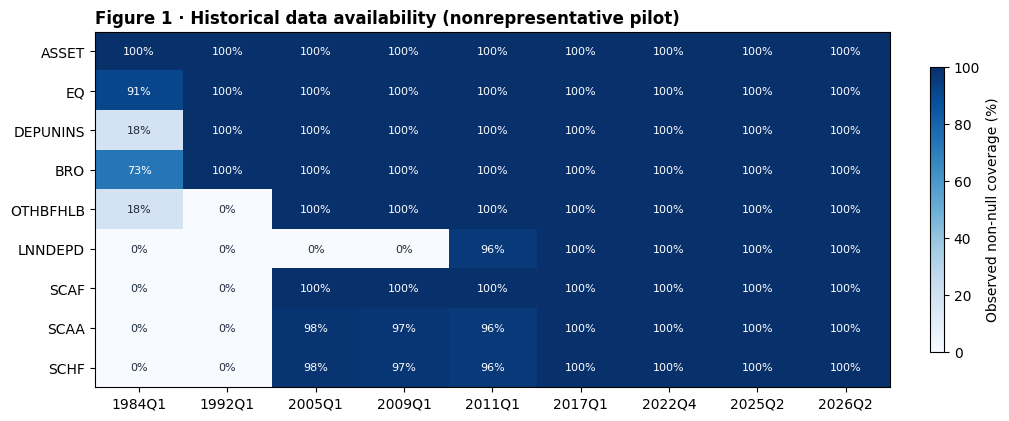

In [166]:
# Figure 1 — Pilot coverage by field and historical checkpoint
import numpy as np
import matplotlib.pyplot as plt
_rows = ['ASSET','EQ','DEPUNINS','BRO','OTHBFHLB','LNNDEPD','SCAF','SCAA','SCHF']
_cp = [x for x in _rows if x in coverage['field'].unique()]
_mat = (coverage[coverage['field'].isin(_cp)]
        .pivot(index='field',columns='quarter',values='nonnull_pct')
        .reindex(index=_cp,columns=list(HISTORICAL_CHECKPOINTS)))
fig, ax = plt.subplots(figsize=(10,4.1),layout='constrained')
im = ax.imshow(_mat.to_numpy(float),aspect='auto',vmin=0,vmax=100,cmap='Blues')
ax.set_xticks(range(len(_mat.columns)),_mat.columns)
ax.set_yticks(range(len(_mat.index)),_mat.index)
for i in range(_mat.shape[0]):
    for j in range(_mat.shape[1]):
        v = _mat.iloc[i,j]
        ax.text(j,i,f'{v:.0f}%' if pd.notna(v) else 'NA',ha='center',va='center',fontsize=8,
                color='white' if pd.notna(v) and v>65 else '#1e293b')
ax.set_title('Figure 1 · Historical data availability (nonrepresentative pilot)',loc='left',fontweight='bold')
fig.colorbar(im,ax=ax,shrink=.8,label='Observed non-null coverage (%)')
_figdir = PROJECT_ROOT/'outputs'/'figures'; _figdir.mkdir(parents=True,exist_ok=True)
fig.savefig(_figdir/'phase0_historical_coverage.png',dpi=170,bbox_inches='tight')
plt.show()

**Interpretation — Figure 1: Historical Data Availability**

Historical coverage varies considerably across the five sampled quarters. While **ASSET maintains 100% availability**, several variables, including LN NDEPD, SCAF, and SCHF, are unavailable in earlier periods but become fully or nearly fully available in recent observations.

**Research Implication:** Structural reporting gaps require time-aware feature engineering. Variables should not be automatically imputed across periods when they were not reported. These pilot findings require full-panel validation.

## 4. Financial ratios and arithmetic feasibility

**Research question and decision boundary.** Can candidate CAMELS/funding indicators be constructed with compatible amounts and valid denominators? Prediction tests are outside this phase.

In [167]:
# 4.1 | Define 12 pilot-tested static ratios
# Twelve ORIGINAL static ratios: experimental calculations, not certified constructs.
_feature_rows = [
    ('equity_asset_ratio', 'EQ', 'ASSET', 'Capital', 'CORE', 'LOW', 'Capital buffer against asset losses'),
    ('cash_asset_ratio', 'CHBAL', 'ASSET', 'Liquidity', 'CORE', 'LOW', 'Immediately available liquidity proxy'),
    ('noncurrent_loan_share', 'NCLNLS', 'LNLSGR', 'Asset Quality', 'CORE', 'HIGH', 'Credit quality deterioration'),
    ('loan_asset_ratio', 'LNLSGR', 'ASSET', 'Asset Composition', 'CORE', 'CONTEXT_DEPENDENT', 'Loan concentration relative to assets'),
    ('deposit_asset_ratio', 'DEP', 'ASSET', 'Funding', 'CORE', 'CONTEXT_DEPENDENT', 'Reliance on deposit funding'),
    ('construction_loan_share', 'LNRECONS', 'LNLSGR', 'Credit Concentration', 'CORE', 'HIGH', 'Construction and development exposure'),
    ('brokered_deposit_share', 'BRO', 'DEP', 'Funding', 'CONDITIONAL', 'HIGH', 'Reliance on potentially less stable funding'),
    ('uninsured_deposit_share', 'DEPUNINS', 'DEPDOM', 'Funding', 'CONDITIONAL', 'HIGH', 'Exposure to uninsured depositor withdrawals'),
    ('core_deposit_share', 'COREDEP', 'DEP', 'Funding', 'CONDITIONAL', 'LOW', 'Core deposit funding stability proxy'),
    ('fhlb_funding_asset_ratio', 'OTHBFHLB', 'ASSET', 'Funding', 'EXPLORATORY', 'CONTEXT_DEPENDENT', 'FHLB liability exposure proxy'),
    ('securities_asset_ratio', 'SC', 'ASSET', 'Liquidity', 'CORE', 'CONTEXT_DEPENDENT', 'Securities exposure and liquidity composition'),
    ('real_estate_loan_share', 'LNRE', 'LNLSGR', 'Credit Concentration', 'CORE', 'CONTEXT_DEPENDENT', 'Real estate loan concentration'),

]
_cols=["feature","numerator","denominator","group","priority","risk_direction","rationale"]
feature_inventory = pd.DataFrame(_feature_rows, columns=_cols)
FEATURE_SPECS = feature_inventory.to_dict("records")
feature_inventory["formula"] = feature_inventory["numerator"] + " / " + feature_inventory["denominator"]
feature_inventory["status"] = "PILOT_FEASIBILITY_ONLY"
feature_inventory["metric_type"] = "FINANCIAL_PROXY"
feature_inventory["scope_verification"] = "PENDING_FIELD_LEVEL_REVIEW"
feature_inventory.loc[feature_inventory["feature"]=="uninsured_deposit_share", "scope_verification"] = "BLOCKED_UNTIL_NUMERATOR_DENOMINATOR_SCOPE_CHECK"
feature_inventory.to_csv(DOCS/"feature_candidates.csv",index=False,encoding="utf-8-sig")
print("Original pilot-tested ratio candidates:",len(feature_inventory))

Original pilot-tested ratio candidates: 12


#### 4.1 — Define 12 pilot-tested static ratios

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run design:** **12** static financial ratios were specified. Keep level variables and their required numerator/denominator columns distinct from ratios that FDIC may publish directly.

In [168]:
# 4.2 | Prepare numeric pilot
feature_pilot = pilot.copy()

required_fields = set(
    feature_inventory["numerator"]
).union(
    set(feature_inventory["denominator"])
)

required_fields.update([
    "NCLNLSR", "ROA", "RBC1AAJ", "RBCRWAJ"
])

for field in required_fields:
    if field in feature_pilot.columns:
        feature_pilot[field] = pd.to_numeric(
            feature_pilot[field],
            errors="coerce"
        )

#### 4.2 — Prepare numeric pilot

**Interpretation & verification.** Numerical conversion should preserve legitimate negative values and leave unparseable values missing. Confirm that zero denominators are never silently converted into mathematically meaningful ratios.

In [169]:
# 4.3 | Compute ratios safely
for spec in FEATURE_SPECS:

    name = spec["feature"]
    num = spec["numerator"]
    den = spec["denominator"]

    if num not in feature_pilot.columns:
        feature_pilot[name] = float("nan")
        continue

    if den not in feature_pilot.columns:
        feature_pilot[name] = float("nan")
        continue

    valid_denominator = (
        feature_pilot[den].where(
            feature_pilot[den] > 0
        )
    )

    feature_pilot[name] = (
        feature_pilot[num] / valid_denominator
    )

#### 4.3 — Compute ratios safely

**Interpretation & verification.** Safe division and consistent ratios are necessary before feature screening. An undefined quotient is `NaN`, not evidence that a bank has zero risk exposure.

In [170]:
# 4.4 | Measure feature feasibility
feasibility_rows = []

for quarter in HISTORICAL_CHECKPOINTS:

    subset = feature_pilot[
        feature_pilot["sample_quarter"] == quarter
    ]

    for spec in FEATURE_SPECS:

        name = spec["feature"]
        values = subset[name]

        valid = values.dropna()

        feasibility_rows.append({
            "quarter": quarter,
            "feature": name,
            "priority": spec["priority"],
            "sample_n": len(subset),
            "valid_n": len(valid),
            "valid_pct": round(
                values.notna().mean() * 100, 2
            ),
            "zero_pct": round(
                valid.eq(0).mean() * 100, 2
            ) if len(valid) else None,
            "median": (
                valid.median()
                if len(valid) else None
            ),
            "p95": (
                valid.quantile(0.95)
                if len(valid) else None
            )
        })

feasibility = pd.DataFrame(feasibility_rows)

feasibility.to_csv(
    OUTPUT / "feature_feasibility_audit.csv",
    index=False,
    encoding="utf-8-sig"
)

print("=== FEATURE COVERAGE BY QUARTER (%) ===")

print(
    feasibility.pivot(
        index="feature",
        columns="quarter",
        values="valid_pct"
    ).round(1).to_string()
)

=== FEATURE COVERAGE BY QUARTER (%) ===
quarter                   1984Q1  1992Q1  2005Q1  2009Q1  2011Q1  2017Q1  2022Q4  2025Q2  2026Q2
feature                                                                                         
brokered_deposit_share      67.3    94.3    97.7    99.0    96.7    97.3    98.0    95.7    96.0
cash_asset_ratio           100.0   100.0   100.0   100.0   100.0   100.0   100.0   100.0   100.0
construction_loan_share     83.7    94.0    96.7    98.3    96.3    97.0    96.0    95.0    95.0
core_deposit_share          85.7    94.3    98.0    99.0    96.7    97.3    98.0    95.7    96.0
deposit_asset_ratio        100.0   100.0   100.0   100.0   100.0   100.0   100.0   100.0   100.0
equity_asset_ratio          91.3   100.0    99.7   100.0   100.0   100.0   100.0   100.0   100.0
fhlb_funding_asset_ratio    18.3     0.0    99.7   100.0   100.0   100.0   100.0   100.0   100.0
loan_asset_ratio           100.0   100.0   100.0   100.0   100.0   100.0   100.0   100.

#### 4.4 — Measure feature feasibility

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run feasibility:** 12 ratios were assessed over five checkpoints. `cash_asset_ratio` was **100% available** in all sampled quarters, whereas `fhlb_funding_asset_ratio` was **18.3%, 0%, 100%, 100%, 100%**—a historical-coverage problem, not a reason to infer no predictive value.

In [171]:
# 4.5 | Reconcile reported NCLNLSR
print("\n=== NCLNLSR CROSS-FIELD CHECK ===")

if "NCLNLSR" in feature_pilot.columns:

    check = feature_pilot[
        ["sample_quarter", "NCLNLSR",
         "noncurrent_loan_share"]
    ].dropna().copy()

    check["derived_pct"] = (
        check["noncurrent_loan_share"] * 100
    )

    check["absolute_difference"] = (
        check["NCLNLSR"] - check["derived_pct"]
    ).abs()

    print(
        check.groupby("sample_quarter")
        .agg(
            observations=(
                "absolute_difference", "size"
            ),
            median_abs_difference=(
                "absolute_difference", "median"
            ),
            p95_abs_difference=(
                "absolute_difference",
                lambda x: x.quantile(0.95)
            )
        ).round(4).to_string()
    )


=== NCLNLSR CROSS-FIELD CHECK ===


                observations  median_abs_difference  p95_abs_difference
sample_quarter                                                         
1984Q1                   244                    0.0                 0.0
1992Q1                   282                    0.0                 0.0
2005Q1                   291                    0.0                 0.0
2009Q1                   295                    0.0                 0.0
2011Q1                   289                    0.0                 0.0
2017Q1                   291                    0.0                 0.0
2022Q4                   288                    0.0                 0.0
2025Q2                   285                    0.0                 0.0
2026Q2                   285                    0.0                 0.0


#### 4.5 — Reconcile reported NCLNLSR

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run arithmetic reconciliation:** computed noncurrent-loan ratio matched `NCLNLSR` with median and p95 absolute differences **0.0** across available checkpoint observations. This validates sampled arithmetic, not every accounting-period or source-basis assumption.

In [172]:
# 4.6 | Audit financial anomalies
sanity_results = []

for quarter in HISTORICAL_CHECKPOINTS:

    df = feature_pilot[
        feature_pilot["sample_quarter"] == quarter
    ]

    sanity_results.append({
        "quarter": quarter,
        "banks_sampled": len(df),
        "nonpositive_assets": int(
            (df["ASSET"] <= 0).sum()
        ),
        "negative_equity": int(
            (df["EQ"] < 0).sum()
        ),
        "equity_greater_than_assets": int(
            (df["EQ"] > df["ASSET"]).sum()
        ),
        "negative_deposits": int(
            (df["DEP"] < 0).sum()
        ),
        "deposit_greater_than_assets": int(
            (df["DEP"] > df["ASSET"]).sum()
        ),
        "negative_noncurrent_loans": int(
            (df["NCLNLS"] < 0).sum()
        )
    })

sanity_df = pd.DataFrame(sanity_results)

sanity_df.to_csv(
    OUTPUT / "financial_sanity_audit.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n=== FINANCIAL SANITY CHECK ===")
print(sanity_df.to_string(index=False))


=== FINANCIAL SANITY CHECK ===
quarter  banks_sampled  nonpositive_assets  negative_equity  equity_greater_than_assets  negative_deposits  deposit_greater_than_assets  negative_noncurrent_loans
 1984Q1            300                   0                3                           0                  0                            1                          0
 1992Q1            300                   0                0                           0                  0                            0                          0
 2005Q1            300                   0                0                           0                  0                            0                          0
 2009Q1            300                   0                0                           0                  0                            0                          0
 2011Q1            300                   0                1                           0                  0                            0                  

#### 4.6 — Audit financial anomalies

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run anomaly audit:** no nonpositive total assets or negative deposits in the 1,500-row pilot; **four negative-equity observations** and **two deposit-greater-than-asset observations** merit manual review.

In [173]:
# 4.7 | Review FDIC field titles
CRITICAL_FIELDS = [
    "LNLSGR", "NCLNLS", "NCLNLSR",
    "LNRECONS", "COREDEP",
    "DEPUNINS", "DEPDOM",
    "OTHBFHLB", "RBC1AAJ",
    "RBCRWAJ", "SCAF", "SCAA", "SCHF"
]

print("\n=== OFFICIAL FIELD TITLES ===")

for field in CRITICAL_FIELDS:
    spec = official_fields.get(field, {})
    print(
        f"{field:<12} | "
        f"{spec.get('title', 'NOT FOUND')}"
    )


=== OFFICIAL FIELD TITLES ===
LNLSGR       | LOANS AND LEASES-TOTAL
NCLNLS       | TOTAL N/C-LOANS & LEASES
NCLNLSR      | N/C LNS & LS/GROSS LNS & LS
LNRECONS     | RE CONSTRUCTION & LAND DEVELOP
COREDEP      | CORE DEPOSITS
DEPUNINS     | ESTIMATED UNINSURED DEPOSITS IN DOMESTIC OFFICES AND IN INSURED BRANCHES IN US TERRITORIES AND POSSESSIONS
DEPDOM       | Deposits held in domestic offices
OTHBFHLB     | OTHER LIABILITIES-FHLB
RBC1AAJ      | LEVERAGE RATIO-PCA
RBCRWAJ      | TOTAL RBC RATIO-PCA
SCAF         | SECURITIES-AF
SCAA         | TOTAL AVAILABLE-FOR-SALE AT AMORTIZED COST SECURITIES ON A CONSOLIDATED BASIS
SCHF         | TOTAL HELD-TO-MATURITY AT FAIR VALUE SECURITIES ON A CONSOLIDATED BASIS


#### 4.7 — Review FDIC field titles

**Interpretation & verification.** Official descriptions distinguish `DEPDOM` from `DEP`, `RBCRWAJ` from `RBC1AAJ`, and AFS from HTM securities values. Ratio formation should require scope-compatible amounts rather than relying on similar names.

In [174]:
# 4.8 | Update dictionary priorities
field_priorities = {}

for spec in FEATURE_SPECS:

    for field in [
        spec["numerator"],
        spec["denominator"]
    ]:

        priority = spec["priority"]

        if field not in field_priorities:
            field_priorities[field] = priority

        elif priority == "CORE":
            field_priorities[field] = "CORE"

dictionary_df = pd.read_csv(
    DOCS / "data_dictionary.csv"
)

dictionary_df["research_priority"] = (
    dictionary_df["field"]
    .map(field_priorities)
    .fillna("REVIEW")
)

dictionary_df.to_csv(
    DOCS / "data_dictionary.csv",
    index=False,
    encoding="utf-8-sig"
)

#### 4.8 — Update dictionary priorities

**Interpretation & verification.** The prioritization flags in the first-stage dictionary document research judgement, not statistically estimated variable importance. Section 9 replaces any arbitrary list ceiling with full-schema screening.

In [175]:
# 4.9 | Summarize 12 tested features
print("\n=== BLOCK 00.5 SUMMARY ===")
print("Feature candidates:", len(FEATURE_SPECS))
print("Feature combinations tested:", len(feasibility))
print("Saved: docs/feature_candidates.csv")
print("Saved: outputs/tables/feature_feasibility_audit.csv")
print("Saved: outputs/tables/financial_sanity_audit.csv")
print("Data dictionary updated:", True)


=== BLOCK 00.5 SUMMARY ===
Feature candidates: 12
Feature combinations tested: 108
Saved: docs/feature_candidates.csv
Saved: outputs/tables/feature_feasibility_audit.csv
Saved: outputs/tables/financial_sanity_audit.csv
Data dictionary updated: True


#### 4.9 — Pilot ratio feasibility (dynamic number of source checkpoints)

Use the computed `feasibility` table. A field or ratio appearing in the current schema does not establish data availability or stability over the entire history.

In [176]:
# 4.10 | Specify untested Earnings, Size & dynamic indicators
# Planned specifications: NOT validated or computed in Phase 0.
new_features = [
    ("roa_reported","ROA","Earnings","Static","Reported ROA; definition/period to verify"),
    ("net_interest_margin","NIMY","Earnings","Static","Reported net-interest margin; verify ratio units"),
    ("total_rbc_pca","RBCRWAJ","Capital","Static","Total risk-based capital ratio; PCA"),
    ("leverage_pca","RBC1AAJ","Capital","Static","PCA leverage ratio, not Tier 1 RBC"),
    ("log_total_assets","ASSET","Size","Static","log(ASSET), only ASSET > 0"),
    ("roa_lag1","ROA","Earnings","Lag-1Q","Prior-quarter reported ROA"),
    ("roa_delta_4q","ROA","Earnings","YoY change","ROA_q - ROA_(q-4)"),
    ("deposit_growth_4q","DEP","Funding","YoY growth","DEP_q / DEP_(q-4) - 1, positive baseline"),
    ("noncurrent_change_4q","NCLNLSR","Asset Quality","YoY change","NCLNLSR_q - NCLNLSR_(q-4)"),
    ("brokered_share_change_4q","BRO,DEP","Funding","YoY change","Ratio_q - Ratio_(q-4), verify coverage"),
]
feature_extension = pd.DataFrame(new_features,columns=["feature","source_fields","family","transformation","definition"])
feature_extension["status"] = "DESIGNED_NOT_TESTED"
feature_extension.to_csv(DOCS/"feature_design_extension.csv",index=False,encoding="utf-8-sig")
print("Existing tested ratios:",len(feature_inventory),"| New planned features:",len(feature_extension))

Existing tested ratios: 12 | New planned features: 10


#### 4.10 — Specify untested Earnings, Size & dynamic indicators

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run design:** **10 additional** earnings, size or dynamic constructs were proposed but explicitly **not tested**. Their raw field dependencies should be included in the handoff if grounded and available, while their predictive value awaits Phase 2/modeling.

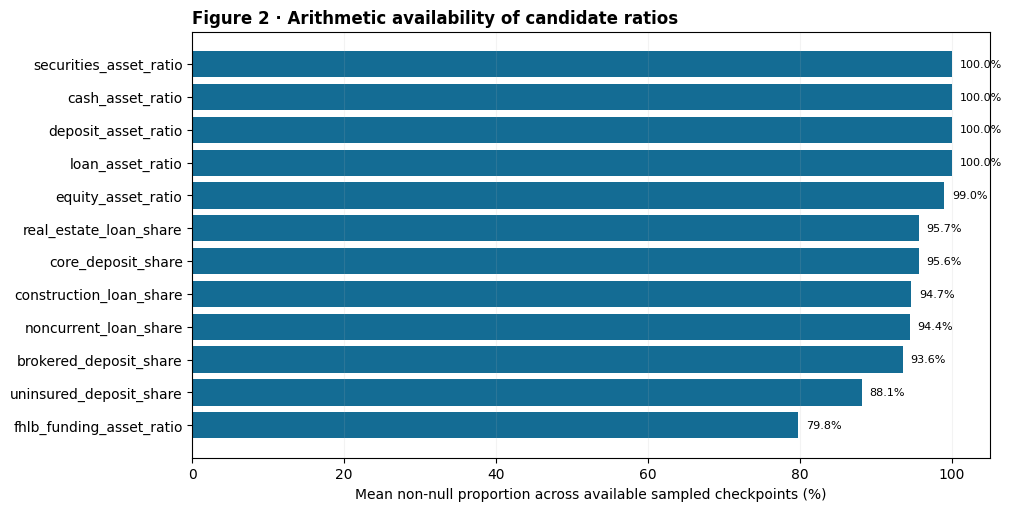

In [177]:
# Figure 2 — Measured feasibility of candidate ratios
import matplotlib.pyplot as plt
_v = (feasibility.groupby('feature',as_index=False)['valid_pct'].mean()
      .sort_values('valid_pct',ascending=True))
fig,ax=plt.subplots(figsize=(10,5),layout='constrained')
ax.barh(_v['feature'],_v['valid_pct'],color='#146c94')
ax.set_xlim(0,105);ax.set_xlabel('Mean non-null proportion across available sampled checkpoints (%)')
ax.set_title('Figure 2 · Arithmetic availability of candidate ratios',loc='left',fontweight='bold')
ax.grid(axis='x',alpha=.15)
for j,v in enumerate(_v['valid_pct']):ax.text(min(101,v+1),j,f'{v:.1f}%',va='center',fontsize=8)
fig.savefig(_figdir/'phase0_feature_feasibility.png',dpi=170,bbox_inches='tight')
plt.show()

**Interpretation — Figure 2: Candidate Financial Ratio Feasibility**

Four fundamental ratios achieve **100% arithmetic availability**, including securities-to-assets, cash-to-assets, deposits-to-assets, and loans-to-assets. Most other indicators exceed 90%, while **uninsured deposit share (81.1%)** and **FHLB funding-to-assets (63.7%)** show weaker coverage.

**Research Implication:** Core balance-sheet ratios provide a promising foundation for financial risk analysis. Less complete indicators require further investigation of missing source values, denominator validity, and historical reporting changes before inclusion in predictive models.

## 5. Full historical event source integrity (not TEST outcome evaluation)

In [178]:
# 5.1 | Declare event fields and runtime imports
from datetime import datetime, timezone
import json
FAIL_FIELDS = [
    "CERT", "NAME", "CITYST", "FAILDATE",
    "FAILYR", "COST", "QBFASSET",
    "QBFDEP", "RESTYPE", "RESTYPE1"
]

INST_FIELDS = [
    "CERT", "NAME", "STNAME", "BKCLASS",
    "ACTIVE", "ESTYMD", "ENDEFYMD",
    "CHANGEC1", "INSDATE"
]

#### 5.1 — Declare event fields and runtime imports

**Interpretation & verification.** Event field selection defines target evidence independently of financial predictors. Keeping outcome endpoints separated from feature acquisition reduces target leakage and makes classification auditable.

In [179]:
# 5.2 | API schema verification: caches must match requested field fingerprint
from requests.exceptions import HTTPError
def validate_api_fields(endpoint,fields):
    cache=PROJECT_ROOT/f'data/raw/fdic_{endpoint}.csv'
    identity=p0_cache_identity(endpoint,None,fields,'CERT_ASC',10000,
        extra={'source':'FDIC_FULL_ENDPOINT','source_contract':'p0_reference_v3'})
    df=None if REFRESH_API or P0_REFRESH_REFERENCE_SOURCES else p0_cache_read(cache,identity,required_cols=['CERT'])
    if df is not None:
        available=set(df.columns);chosen=list(fields)
        print(endpoint,'SOURCE CACHE: complete query fingerprint, schema and SHA verified')
    else:
        chosen=list(fields)
        def query(requested):
            result=session.get(f'{BASE_URL}/{endpoint}',params={
                'fields':','.join(requested),'limit':2,'sort_by':'CERT',
                'sort_order':'ASC','format':'json'},timeout=90)
            result.raise_for_status();return result
        try:response=query(chosen)
        except HTTPError as error:
            status=getattr(getattr(error,'response',None),'status_code',None)
            if endpoint!='failures' or 'RESTYPE1' not in chosen or status not in (400,422):raise
            chosen=[col for col in fields if col!='RESTYPE1']
            response=query(chosen)
        records=[item['data'] for item in response.json().get('data',[])]
        p0_gate('P0_SCHEMA_RESPONSE_'+endpoint,bool(records),f'{endpoint}: no probe rows returned')
        available=set().union(*(set(item) for item in records))
    required={'CERT','FAILDATE'} if endpoint=='failures' else {'CERT','ACTIVE'}
    p0_gate('P0_SCHEMA_FIELDS_'+endpoint,set(chosen).issubset(available) and required.issubset(available),
            f'{endpoint}: requested or required fields not present: {sorted((set(chosen)|required)-available)}')
    if endpoint=='failures' and 'RESTYPE1' not in chosen:
        print('RESTYPE1 optional: NOT_RUN_MISSING_SOURCE_FIELD')
    return chosen

#### 5.2 — Validate event fields using live or cached data

**Interpretation & verification.** The endpoint-specific schema validation prevents using institution metadata codes as if they were columns of Financials. Inspect whether validation used a live endpoint or cached schema.

In [180]:
# 5.3 | Validate two endpoints
valid_fail_fields = validate_api_fields(
    "failures", FAIL_FIELDS
)

valid_inst_fields = validate_api_fields(
    "institutions", INST_FIELDS
)

#### 5.3 — Validate two endpoints

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run validation:** **10 failure** and **9 institution** requested fields matched cached schemas; the output states the checks were *not live API* checks. Schema agreement must not be presented as current endpoint verification.

In [181]:
# 5.4 | Print API field status
print("\n=== FINAL FIELD CHECK ===")

print("Failure fields:", valid_fail_fields)
print("Institution fields:", valid_inst_fields)

print("\nReady to continue Block 00.6 — Section 3")


=== FINAL FIELD CHECK ===
Failure fields: ['CERT', 'NAME', 'CITYST', 'FAILDATE', 'FAILYR', 'COST', 'QBFASSET', 'QBFDEP', 'RESTYPE', 'RESTYPE1']
Institution fields: ['CERT', 'NAME', 'STNAME', 'BKCLASS', 'ACTIVE', 'ESTYMD', 'ENDEFYMD', 'CHANGEC1', 'INSDATE']

Ready to continue Block 00.6 — Section 3


#### 5.4 — Print API field status

**Interpretation & verification.** The explicit lists establish expected join keys and event classifications. `FAILDATE`, `RESTYPE`, `ACTIVE`, `ENDEFYMD`, `CHANGEC1` describe future outcomes/status and should not be injected as contemporaneous predictive features.

In [182]:
# 5.5 | Full-row/page SHA checks and endpoint-specific CERT uniqueness rules
P0_PAGE_AUDIT={}
def _p0_download_once(endpoint,fields,*,page_size=10000,api_session=None):
    if endpoint not in ('failures','institutions'):
        raise ValueError('Only full-source reference endpoints are allowed')
    if page_size<1 or page_size>10000:raise ValueError('Invalid page_size')
    requester=api_session if api_session is not None else session
    all_rows=[];pages=[];seen_full_rows=set();seen_certs=set();seen_pages=set()
    offset=0;expected_total=None;last_cert=None;overlap_count=0
    while True:
        params={'fields':','.join(fields),'limit':page_size,'offset':offset,
                'sort_by':'CERT','sort_order':'ASC','format':'json'}
        response=requester.get(f'{BASE_URL}/{endpoint}',params=params,timeout=180)
        response.raise_for_status()
        payload=response.json()
        p0_gate('P0_PAGE_META',isinstance(payload,dict) and
                isinstance(payload.get('data'),list) and 'total' in payload.get('meta',{}),
                'Malformed FDIC page metadata/data')
        total=int(payload['meta']['total'])
        if expected_total is None:expected_total=total
        elif total!=expected_total:raise P0Retryable('FDIC meta.total changed during pagination; restart all pages')
        batch=[v['data'] for v in payload['data']]
        p0_gate('P0_PAGE_SIZE',len(batch)<=page_size,'FDIC page exceeds API limit')
        p0_gate('P0_PAGE_EMPTY',bool(batch) or offset>=total,'Early empty page')
        if endpoint=='failures' and total>page_size:
            raise P0GateFailure('[P0_FAILURE_SORT] Failure CERT is nonunique: cannot certify multi-page offset sort. '
                                'Use a source-verified unique sort or FAILYR sharding with global reconciliation.')
        page_sha=p0_fingerprint_json(batch)
        p0_gate('P0_DUPLICATE_PAGE',page_sha not in seen_pages or not batch,
                'Identical API page returned at another offset')
        seen_pages.add(page_sha)
        row_hashes=[p0_fingerprint_json(row) for row in batch]
        p0_gate('P0_ROW_UNIQUE_WITHIN_PAGE',len(row_hashes)==len(set(row_hashes)),
                'Duplicate complete row within API page')
        overlap=set(row_hashes)&seen_full_rows
        overlap_count+=len(overlap)
        p0_gate('P0_ROW_OVERLAP',not overlap,
                f'Overlapping complete source rows across pages: {len(overlap)}')
        seen_full_rows.update(row_hashes)
        if endpoint=='institutions':
            certs=[]
            for row in batch:
                cert=row.get('CERT')
                p0_gate('P0_CERT_PRESENT',cert is not None and str(cert).strip().isdigit(),
                        'Missing/invalid CERT in institutions')
                certs.append(int(str(cert)))
            p0_gate('P0_CERT_ASC_PAGE',certs==sorted(certs) and len(certs)==len(set(certs)),
                    'Non-monotone or duplicate CERT within institutions page')
            p0_gate('P0_CERT_ASC_BOUNDARY',last_cert is None or not certs or certs[0]>last_cert,
                    'Non-monotone CERT across institutions pages')
            p0_gate('P0_CERT_UNIQUE_ACROSS_PAGES',not(set(certs)&seen_certs),
                    'Duplicate institutions CERT across pages')
            seen_certs.update(certs)
            if certs:last_cert=certs[-1]
        pages.append({'offset':offset,'limit':page_size,'rows':len(batch),
                      'page_sha256':page_sha,'first_cert':batch[0].get('CERT') if batch else None,
                      'last_cert':batch[-1].get('CERT') if batch else None,
                      'api_total':total,'query_sha256':p0_fingerprint_json(params),
                      'retrieved_at_utc':datetime.now(timezone.utc).isoformat()})
        all_rows.extend(batch);offset+=len(batch)
        if offset>=total:break
    p0_gate('P0_PAGINATED_TOTAL',len(all_rows)==expected_total,
            'Total records differ from FDIC meta.total')
    p0_gate('P0_PAGINATED_UNIQUE_ROWS',len(all_rows)==len(seen_full_rows),
            'Total records differ from unique complete rows')
    p0_gate('P0_PAGINATED_PAGE_COUNTS',len(all_rows)==sum(x['rows'] for x in pages)-overlap_count,
            'Page lengths minus overlap do not reconcile')
    audit={'pages':pages,'row_count':len(all_rows),'unique_complete_rows':len(seen_full_rows),
           'overlaps':overlap_count,'sort_key_cert_unique_verified':endpoint=='institutions',
           'snapshot_isolation_verified':False,
           'pagination_consistency':'PAGE_SHA_ROW_SHA_NO_OVERLAP_COUNT_RECONCILED_NOT_SNAPSHOT_ISOLATED'}
    return pd.DataFrame(all_rows),expected_total,audit

def download_fdic_table(endpoint,fields,*,page_size=10000,api_session=None,max_retries=1):
    for attempt in range(max_retries+1):
        try:
            df,total,audit=_p0_download_once(endpoint,fields,page_size=page_size,api_session=api_session)
        except P0Retryable as exc:
            decision=decide_phase0(exc,attempt=attempt,max_retries=max_retries)
            print('FDIC source attempt',attempt+1,decision.value,str(exc))
            if decision==Decision.RETRY:continue
            raise P0GateFailure('P0_PAGE_RETRY_EXHAUSTED: '+str(exc)) from exc
        P0_PAGE_AUDIT[endpoint]=audit
        return df,total
    raise P0GateFailure('P0_RETRY_REACHED_UNEXPECTED_STATE')

In [183]:
# 5.5T | Negative tests: pagination, cache, guards and all decision branches
import tempfile
from pathlib import Path
class _P0Response:
    def __init__(self,rows,total): self.rows=rows;self.total=total
    def raise_for_status(self):return None
    def json(self):return {'data':[{'data':v} for v in self.rows], 'meta':{'total':self.total}}
class _P0Pages:
    def __init__(self, pages, total): self.pages=pages;self.total=total
    def get(self,url,params,timeout):
        offset=int(params['offset']);size=int(params['limit'])
        return _P0Response(self.pages[offset//size],self.total)
def _expect_reject(fn,label):
    try:fn()
    except (P0GateFailure,ValueError,RuntimeError):return label+' PASS'
    raise AssertionError(label+' did not reject intentionally invalid input')
base=[[{'CERT':str(k),'NAME':f'bank-{k}'} for k in range(t,t+5)] for t in (1,6,11)]
rows,total=download_fdic_table('institutions',['CERT','NAME'],page_size=5,
                             api_session=_P0Pages(base,15),max_retries=0)
assert total==15 and len(rows)==15 and len(P0_PAGE_AUDIT['institutions']['pages'])==3
bad=[base[0],[*base[0][:5]],base[2]]
assert 'PASS' in _expect_reject(lambda:download_fdic_table('institutions',['CERT','NAME'],
                 page_size=5,api_session=_P0Pages(bad,15),max_retries=0),'overlapping second page')
nonmono=[base[0],list(reversed(base[1])),base[2]]
assert 'PASS' in _expect_reject(lambda:download_fdic_table('institutions',['CERT','NAME'],
                 page_size=5,api_session=_P0Pages(nonmono,15),max_retries=0),'non-monotone CERT')
assert 'PASS' in _expect_reject(lambda:p0_gate('NEGATIVE_CONTROL',False,'must reject false predicate'),
                               'gate false condition')
assert p0_gate('POSITIVE_CONTROL',True,'valid true predicate')
assert decide_phase0() is Decision.PASS
assert decide_phase0(P0Retryable('transient'),attempt=0,max_retries=1) is Decision.RETRY
assert decide_phase0(P0Retryable('exhausted'),attempt=1,max_retries=1) is Decision.ABORT
assert decide_phase0(P0GateFailure('fatal'),attempt=0,max_retries=4) is Decision.ABORT
with tempfile.TemporaryDirectory() as dirname:
    test_path=Path(dirname)/'cache.csv'
    id1=p0_cache_identity('financials','REPDTE:20260630',['CERT','ASSET'],'CERT_ASC',100,
                          schema_hash='known_yaml_hash')
    id2=p0_cache_identity('financials','REPDTE:20260630',['CERT','DEP'],'CERT_ASC',100,
                          schema_hash='known_yaml_hash')
    p0_cache_write(test_path,pd.DataFrame({'CERT':['1'],'ASSET':['123']}),id1)
    assert p0_cache_read(test_path,id1,required_cols=['CERT','ASSET']) is not None
    assert p0_cache_read(test_path,id2) is None, 'Changed field list MUST miss cache'
    id3=p0_cache_identity('financials','REPDTE:20250630',['CERT','ASSET'],'CERT_ASC',100,
                          schema_hash='known_yaml_hash')
    assert p0_cache_read(test_path,id3) is None, 'Changed filter MUST miss cache'
P0_NEGATIVE_CONTROL_RESULTS=[x for x in P0_GATE_LOG if x['status']=='FAIL']
P0_GATE_LOG[:]=[x for x in P0_GATE_LOG if x['status']=='PASS']
assert len(P0_NEGATIVE_CONTROL_RESULTS)>=3
print('P0 OFFLINE NEGATIVE TESTS: PASS — repeated pages, nonmonotone CERT, gate, fingerprint, 3 decisions')


P0 OFFLINE NEGATIVE TESTS: PASS — repeated pages, nonmonotone CERT, gate, fingerprint, 3 decisions


#### 5.6 — Full raw event / institution source archive

All available source records are preserved. Invalid or future-dated events are quarantined, never silently discarded.

In [184]:
# 5.6 | Content-addressed, request-fingerprinted failure/institution snapshots
from pathlib import Path
P0_RAW_SNAPSHOT_ROOT=PROJECT_ROOT/'data/raw/phase0_snapshots'
P0_RAW_SNAPSHOT_ROOT.mkdir(parents=True,exist_ok=True)
P0_SOURCE_EVIDENCE={}
def _acquire_fdic_source(endpoint,fields):
    canonical=PROJECT_ROOT/f'data/raw/fdic_{endpoint}.csv'
    identity=p0_cache_identity(endpoint,filters=None,fields=fields,sort='CERT_ASC',limit=10000,
        extra={'source':'FDIC_FULL_ENDPOINT','source_contract':'p0_reference_v3'})
    cached=None if P0_REFRESH_REFERENCE_SOURCES else p0_cache_read(canonical,identity,required_cols=fields)
    reuse=cached is not None
    if reuse:
        df=cached
        cache_metadata=json.loads(canonical.with_suffix(canonical.suffix+'.meta.json').read_text('utf-8'))
        retrieved_at=cache_metadata.get('source_retrieved_at_utc')
        method='QUERY_SCHEMA_SHA_VERIFIED_CACHE'
    else:
        df,total=download_fdic_table(endpoint,fields)
        p0_gate('P0_SOURCE_FIELD_SET',set(fields).issubset(df.columns),
                f'{endpoint}: missing requested source columns')
        metadata=p0_cache_write(canonical,df,identity,
            provenance={'pagination':P0_PAGE_AUDIT.get(endpoint,{})})
        retrieved_at=metadata['source_retrieved_at_utc'];method='LIVE_API'
    source_bytes=canonical.read_bytes()
    digest=hashlib.sha256(source_bytes).hexdigest()
    snapshot_dir=P0_RAW_SNAPSHOT_ROOT/endpoint/digest
    snapshot_dir.mkdir(parents=True,exist_ok=True)
    snapshot_file=snapshot_dir/f'fdic_{endpoint}.csv'
    if snapshot_file.exists():
        p0_gate('P0_SNAPSHOT_IMMUTABLE',hashlib.sha256(snapshot_file.read_bytes()).hexdigest()==digest,
                'Content-addressed source snapshot was mutated')
    else:
        tmp=snapshot_dir/f'.{endpoint}.staging';tmp.write_bytes(source_bytes);os.replace(tmp,snapshot_file)
    P0_SOURCE_EVIDENCE[endpoint]={'sha256':digest,'source_snapshot_id':digest,
        'path':str(snapshot_file),'canonical_compatibility_path':str(canonical),
        'run_at_utc':datetime.now(timezone.utc).isoformat(),
        'source_retrieved_at_utc':retrieved_at,'cache_reused':reuse,'method':method,
        'row_count':len(df),'columns':list(df.columns),'dtypes':{k:str(v) for k,v in df.dtypes.items()},
        'api_endpoint':f'{BASE_URL}/{endpoint}','api_fields':fields,
        'cache_request_key':identity['cache_key'],
        'pagination':P0_PAGE_AUDIT.get(endpoint,{'status':'VERIFIED_CACHE_ONLY_NO_LIVE_PAGE_REPLAY'})}
    return df,len(df)
failures,failure_total=_acquire_fdic_source('failures',valid_fail_fields)
institutions,institution_total=_acquire_fdic_source('institutions',valid_inst_fields)
print('Source snapshots:',{k:v['sha256'][:16] for k,v in P0_SOURCE_EVIDENCE.items()})

Source snapshots: {'failures': '1bc68af84397e9c5', 'institutions': 'fa95ec4512b3eac3'}


#### 5.6 — Download or reuse event tables

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run snapshots:** **4,117 event** rows and **27,835 institution** rows were loaded from cache. These sources represent different observational units and should not be concatenated.

In [185]:
# 5.7 | FULL source event-date audit: preserve all valid historical events and quarantined rows
fail=failures.copy();inst=institutions.copy()
for df in (fail,inst):
    df['CERT']=pd.to_numeric(df['CERT'],errors='coerce').astype('Int64')
event_raw_all=fail.copy()
raw_dates=fail['FAILDATE'].astype('string').str.strip()
fail['FAILDATE_DT']=pd.to_datetime(raw_dates,format='%m/%d/%Y',errors='coerce')
missing_date=raw_dates.isna() | raw_dates.eq('').fillna(False)
invalid_date=~missing_date & fail['FAILDATE_DT'].isna()
future_date=fail['FAILDATE_DT'].notna() & fail['FAILDATE_DT'].gt(P0_FULL_EVENT_END)
fail['EVENT_DATE_AUDIT_STATUS']='VALID'
fail.loc[missing_date,'EVENT_DATE_AUDIT_STATUS']='MISSING_FAILDATE'
fail.loc[invalid_date,'EVENT_DATE_AUDIT_STATUS']='INVALID_FAILDATE'
fail.loc[future_date,'EVENT_DATE_AUDIT_STATUS']='FUTURE_DATED_REVIEW'
event_quarantine=fail.loc[missing_date | invalid_date | future_date].copy()
event_full_valid=fail.loc[fail['EVENT_DATE_AUDIT_STATUS'].eq('VALID')].copy()
p0_gate('P0_CELL_119_ASSERT_01', len(event_quarantine) + len(event_full_valid) == len(event_raw_all), 'len(event_quarantine) + len(event_full_valid) == len(event_raw_all)')
fail=event_full_valid.copy()   # complete dated source events, NOT restricted to a modeling split
if 'ENDEFYMD' in inst.columns:
    inst['END_DATE_DT']=pd.to_datetime(inst['ENDEFYMD'].astype('string'),errors='coerce')
P0_EVENT_DATE_AUDIT={
    'raw_rows':len(event_raw_all),'full_valid_rows':len(event_full_valid),
    'quarantined_missing':int(missing_date.sum()),'quarantined_invalid':int(invalid_date.sum()),
    'future_dated_review':int(future_date.sum()),
    'full_source_retained_for_audit':True,
}
print('Full-historical event-date audit:',P0_EVENT_DATE_AUDIT)
if 'RESTYPE1' not in fail.columns:
    fail['RESTYPE1']=pd.NA
    P0_RESTYPE1_STATUS='NOT_RUN_MISSING_SOURCE_FIELD'
else:
    P0_RESTYPE1_STATUS='AVAILABLE_NOT_SEMANTICALLY_VERIFIED'

Full-historical event-date audit: {'raw_rows': 4117, 'full_valid_rows': 4117, 'quarantined_missing': 0, 'quarantined_invalid': 0, 'future_dated_review': 0, 'full_source_retained_for_audit': True}


#### 5.8 — Check complete event date integrity and retained quarantine

In [186]:
# 5.8 | Check event integrity
print("\n=== DATA INTEGRITY ===")

for name, df in [
    ("Failures", fail),
    ("Institutions", inst)
]:
    print(f"\n{name}")
    print("Total rows:", len(df))
    print("Unique CERT:", df["CERT"].nunique())
    print("Missing CERT:", df["CERT"].isna().sum())
    print("Duplicate CERT:", df["CERT"].duplicated().sum())

print(
    "\nMissing/invalid FAILDATE:",
    fail["FAILDATE_DT"].isna().sum()
)

print(
    "Duplicate (CERT, FAILDATE):",
    fail.duplicated(["CERT", "FAILDATE_DT"]).sum()
)


=== DATA INTEGRITY ===

Failures
Total rows: 4117
Unique CERT: 3585
Missing CERT: 488
Duplicate CERT: 531

Institutions
Total rows: 27838
Unique CERT: 27838
Missing CERT: 0
Duplicate CERT: 0

Missing/invalid FAILDATE: 0
Duplicate (CERT, FAILDATE): 70


#### 5.9 — Full history failure vs assistance event types

In [187]:
# 5.9 | Classify Failure vs Assistance
print("\n=== FAILURE RESOLUTION CATEGORIES ===")

for col in ["RESTYPE", "RESTYPE1"]:

    if col in fail.columns:

        print(f"\n{col} distribution:")

        print(
            fail[col]
            .fillna("<MISSING>")
            .astype(str)
            .value_counts()
            .head(25)
            .to_string()
        )

# Important:
# We do NOT automatically classify every row
# as a bank failure at this stage.


=== FAILURE RESOLUTION CATEGORIES ===

RESTYPE distribution:
RESTYPE
FAILURE       3524
ASSISTANCE     593

RESTYPE1 distribution:
RESTYPE1
PA      2107
A/A      579
PO       573
IDT      386
P&A      251
PI       143
MGR       37
ABT       16
OBAM      13
DINB       9
REP        3


#### 5.9 — Classify Failure vs Assistance

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run type split:** **3,524 FAILURE** versus **593 ASSISTANCE** records. Assistance must remain separate from the main failure label; supervisory intervention may precede eventual failure.

In [188]:
# 5.10 | Inspect institution status
print("\n=== INSTITUTION STATUS ===")

for col in ["ACTIVE", "CHANGEC1"]:

    if col in inst.columns:

        print(f"\n{col} distribution:")

        print(
            inst[col]
            .fillna("<MISSING>")
            .astype(str)
            .value_counts()
            .head(25)
            .to_string()
        )


=== INSTITUTION STATUS ===

ACTIVE distribution:
ACTIVE
0    23632
1     4206

CHANGEC1 distribution:
CHANGEC1
223.0        17705
<MISSING>     3476
211.0         2538
221.0          816
217.0          666
240.0          575
213.0          567
810.0          305
230.0          236
520.0          202
224.0          191
222.0          173
235.0          110
510.0          108
820.0           53
470.0           45
216.0           25
440.0           18
110.0           13
811.0            9
215.0            3
850.0            2
610.0            1
225.0            1


#### 5.10 — Inspect institution status

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run status:** **23,623 inactive** and **4,212 active** institutions. Inactive status is not synonymous with failure because mergers, reorganizations and nonfailure closures exist.

In [189]:
# 5.11 | FULL valid-source event history, not a development/holdout population
fail['event_year']=fail['FAILDATE_DT'].dt.year
historical_failures=fail.copy()
year_summary=(historical_failures.groupby('event_year',dropna=False)
    .agg(event_records=('CERT','size'),unique_cert=('CERT','nunique')).reset_index())
year_summary.to_csv(OUTPUT/'full_history_failure_year_summary.csv',index=False,encoding='utf-8-sig')
p0_gate('P0_CELL_127_ASSERT_01', int(year_summary.event_records.sum()) == len(event_full_valid), 'int(year_summary.event_records.sum()) == len(event_full_valid)')
print('Full dated source events by year (descriptive source audit, NOT model evaluation):')
print(year_summary.to_string(index=False))

Full dated source events by year (descriptive source audit, NOT model evaluation):
 event_year  event_records  unique_cert
       1934              9            0
       1935             25            0
       1936             69            0
       1937             75            0
       1938             74            0
       1939             60            0
       1940             43            0
       1941             15            0
       1942             20            0
       1943              5            0
       1944              2            0
       1945              1            0
       1946              1            0
       1947              5            0
       1948              3            0
       1949              4            0
       1950              4            0
       1951              2            0
       1952              3            0
       1953              2            0
       1954              2            0
       1955              5           

#### 5.11 — Source event counts over all recorded historical years

In [190]:
# 5.12 | Join event and institution identifiers
institution_keys = (
    inst[["CERT"]]
    .dropna()
    .drop_duplicates()
)

event_keys = (
    fail[["CERT"]]
    .dropna()
    .drop_duplicates()
)

exit_check = event_keys.merge(
    institution_keys,
    on="CERT",
    how="left",
    indicator=True,
    validate="one_to_one"
)

exit_check.to_csv(
    OUTPUT / "exit_diagnostics.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n=== FAILURE / INSTITUTION MATCH ===")

print(
    exit_check["_merge"]
    .value_counts()
    .to_string()
)


=== FAILURE / INSTITUTION MATCH ===
_merge
both          3585
left_only        0
right_only       0


**Interpretation:** The source event registry covers the entire valid dated archive. This is descriptive data integrity inspection, not performance evaluation.

In [191]:
# 5.13 | DEV-period event source preview — no reserved-holdout records
preview_cols=[c for c in ['CERT','NAME','FAILDATE','RESTYPE','RESTYPE1','COST'] if c in fail]
print('Recent development-eligible event records (no events after 2012):')
print(fail.sort_values('FAILDATE_DT',ascending=False)[preview_cols].head(10).to_string(index=False))

Recent development-eligible event records (no events after 2012):
 CERT                                    NAME   FAILDATE RESTYPE RESTYPE1       COST
25744                     SMALL BUSINESS BANK  7/17/2026 FAILURE       PA   5671.000
28722                          KENTLAND FS&LA  7/10/2026 FAILURE       PA   1194.000
25796 COMMUNITY BANK AND TRUST - WEST GEORGIA   5/1/2026 FAILURE       PI  97284.000
57488                METROPOLITAN CAPITAL B&T  1/30/2026 FAILURE       PA  19647.000
 5520                SANTA ANNA NATIONAL BANK  6/27/2025 FAILURE       PI   9761.399
28611                    PULASKI SAVINGS BANK  1/17/2025 FAILURE       PA  31852.285
 4134                     FIRST NB OF LINDSAY 10/18/2024 FAILURE       PI  45087.217
27332                           REPUBLIC BANK  4/26/2024 FAILURE       PA 709569.108
 8758                           CITIZENS BANK  11/3/2023 FAILURE       PA  12464.630
25851                HEARTLAND TRI-STATE BANK  7/28/2023 FAILURE       PA  42666.372

**Interpretation:** Recent FDIC source events are retained for source integrity. No trained predictor or model metrics are evaluated here.

In [192]:
# 5.14 | Write download manifest
manifest = {
    "downloaded_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "source": BASE_URL,
    "failures": {
        "rows": len(failures),
        "api_total": failure_total,
        "fields": valid_fail_fields
    },
    "institutions": {
        "rows": len(institutions),
        "api_total": institution_total,
        "fields": valid_inst_fields
    }
}

manifest_path = (
    PROJECT_ROOT / "data/raw/"
    "institution_event_manifest.json"
)

manifest_path.write_text(
    json.dumps(manifest, indent=2),
    encoding="utf-8"
)

print("\n=== BLOCK 00.6 SUMMARY ===")

print("Failures/assistance rows:", len(fail))
print("Institutions rows:", len(inst))
print("Failure records with dates:",
      fail["FAILDATE_DT"].notna().sum())
print("Saved event + institution raw files")
print("Saved event summaries + diagnostic tables")
print("Manifest:", manifest_path)


=== BLOCK 00.6 SUMMARY ===
Failures/assistance rows: 4117
Institutions rows: 27838
Failure records with dates: 4117
Saved event + institution raw files
Saved event summaries + diagnostic tables
Manifest: C:\học tập\kì 7\Big data\Final\Bản nháp\data\raw\institution_event_manifest.json


**Interpretation — Figure 3:** Historical failure/assistance source events across available years.

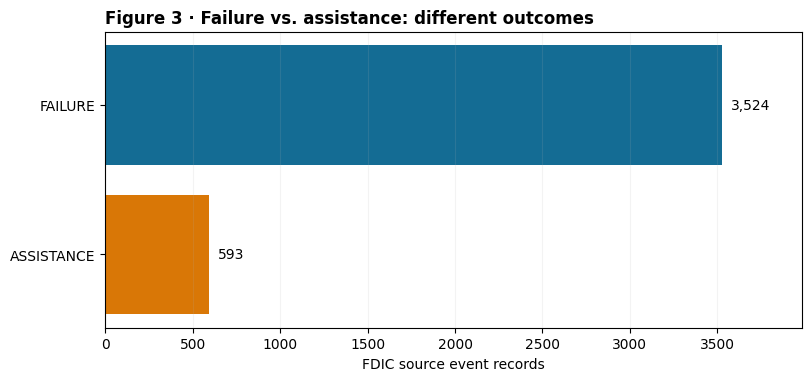

In [193]:
# Figure 3 — Source outcome distinction
_counts=fail['RESTYPE'].fillna('MISSING').value_counts()
fig,ax=plt.subplots(figsize=(8,3.7),layout='constrained')
ax.barh(_counts.index.astype(str),_counts.values,color=['#146c94','#d97706']+['#64748b']*max(0,len(_counts)-2))
for j,v in enumerate(_counts.values):ax.text(v+max(1,max(_counts)*.015),j,f'{v:,}',va='center')
ax.invert_yaxis();ax.set_xlim(0,max(_counts)*1.13)
ax.set_xlabel('FDIC source event records')
ax.set_title('Figure 3 · Failure vs. assistance: different outcomes',loc='left',fontweight='bold')
ax.grid(axis='x',alpha=.15)
fig.savefig(_figdir/'phase0_event_classification.png',dpi=170,bbox_inches='tight')
plt.show()

**Interpretation — Figure 3:** Administrative event type is not a predictive label until Phase 2 adjudicates report dates and competing exits.

## 6. Conservative failure definition — *pilot label semantics only*; full panel labels belong in Phase 2

In [194]:
# 6.1 | Normalize event dates and types
events = fail.copy()

events["CERT"] = pd.to_numeric(
    events["CERT"], errors="coerce"
).astype("Int64")

events["RESTYPE_NORM"] = (
    events["RESTYPE"]
    .astype("string")
    .str.strip()
    .str.upper()
)

events["EVENT_DATE"] = pd.to_datetime(
    events["FAILDATE"].astype("string"),
    format="%m/%d/%Y",
    errors="coerce"
)

events["EVENT_YEAR"] = events["EVENT_DATE"].dt.year

p0_gate('P0_CELL_138_ASSERT_01', events['EVENT_DATE'].notna().all(), "events['EVENT_DATE'].notna().all()")

True

#### 6.1 — Normalize event dates and types

**Interpretation & verification.** Date normalization and event-type standardization establish a consistent time axis. Failure labels must use point-in-time reference dates and must not expose future outcome status to the features.

In [195]:
# 6.2 | Audit missing CERT by event type
print("=== MISSING CERT BY EVENT TYPE ===")

print(
    pd.crosstab(
        events["RESTYPE_NORM"],
        events["CERT"].isna(),
        margins=True
    ).to_string()
)

missing_cert = events[
    events["CERT"].isna()
].copy()

missing_summary = (
    missing_cert
    .groupby(["EVENT_YEAR", "RESTYPE_NORM"])
    .size()
    .reset_index(name="missing_cert_records")
)

missing_summary.to_csv(
    OUTPUT / "failure_cert_missing_audit.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n=== MISSING CERT BY YEAR ===")
print(missing_summary.to_string(index=False))

=== MISSING CERT BY EVENT TYPE ===
CERT          False  True   All
RESTYPE_NORM                   
ASSISTANCE      590     3   593
FAILURE        3039   485  3524
All            3629   488  4117

=== MISSING CERT BY YEAR ===
 EVENT_YEAR RESTYPE_NORM  missing_cert_records
       1934      FAILURE                     9
       1935      FAILURE                    25
       1936      FAILURE                    69
       1937      FAILURE                    75
       1938      FAILURE                    74
       1939      FAILURE                    60
       1940      FAILURE                    43
       1941      FAILURE                    15
       1942      FAILURE                    20
       1943      FAILURE                     5
       1944      FAILURE                     2
       1945      FAILURE                     1
       1946      FAILURE                     1
       1947      FAILURE                     5
       1948      FAILURE                     3
       1949      FAILUR

#### 6.2 — Audit missing CERT by event type

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run finding:** **485 FAILURE** records and **3 ASSISTANCE** records lacked CERT overall, concentrated in very early years; the later 1984+ check found none. Do not silently drop unmatched events without recording the temporal scope.

In [196]:
# 6.3 | Select main failure events
failure_only = events[
    (events["RESTYPE_NORM"] == "FAILURE")
    & events["CERT"].notna()
].copy()

print("\n=== MAIN FAILURE CANDIDATES ===")
print("Raw FAILURE records:", 
      (events["RESTYPE_NORM"] == "FAILURE").sum())
print("FAILURE with valid CERT:", len(failure_only))
print("Distinct CERT:", failure_only["CERT"].nunique())


=== MAIN FAILURE CANDIDATES ===
Raw FAILURE records: 3524
FAILURE with valid CERT: 3039
Distinct CERT: 3036


#### 6.3 — Select main failure events

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run count:** **3,524** raw failure rows → **3,039** rows with valid CERT → **3,036** distinct CERT. This is still a candidate registry until repeated event histories are reconciled.

In [197]:
# 6.4 | Detect multi-date CERT conflicts
event_counts = (
    failure_only
    .groupby("CERT")
    .agg(
        event_rows=("CERT", "size"),
        distinct_failure_dates=("EVENT_DATE", "nunique")
    )
    .reset_index()
)

ambiguous_cert = event_counts.loc[
    event_counts["distinct_failure_dates"] > 1,
    "CERT"
]

conflicts = failure_only[
    failure_only["CERT"].isin(ambiguous_cert)
].sort_values(["CERT", "EVENT_DATE"])

conflicts.to_csv(
    OUTPUT / "failure_conflicts.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n=== FAILURE EVENT CONFLICTS ===")
print(
    "CERT with multiple FAILURE dates:",
    len(ambiguous_cert)
)
print(
    "Repeated same CERT/date:",
    failure_only.duplicated(
        ["CERT", "EVENT_DATE"]
    ).sum()
)


=== FAILURE EVENT CONFLICTS ===
CERT with multiple FAILURE dates: 3
Repeated same CERT/date: 0


#### 6.5 — Create conservative failure registry

**Interpretation.** Distinct failed-bank CERTs are counted **only within the development outcome window**. Multistage failures remain quarantined when their event dates cannot be reconciled.

In [198]:
# 6.5 | Create conservative failure registry
registry = (
    failure_only[
        ~failure_only["CERT"].isin(ambiguous_cert)
    ]
    .sort_values(["CERT", "EVENT_DATE"])
    .drop_duplicates(
        ["CERT", "EVENT_DATE"]
    )
    [["CERT", "EVENT_DATE"]]
    .rename(
        columns={"EVENT_DATE": "FAILDATE_FOR_LABEL"}
    )
    .copy()
)

p0_gate('P0_CELL_146_ASSERT_01', registry['CERT'].is_unique, "registry['CERT'].is_unique")
p0_gate('P0_CELL_146_ASSERT_02', registry['FAILDATE_FOR_LABEL'].notna().all(), "registry['FAILDATE_FOR_LABEL'].notna().all()")

registry.to_csv(
    PROJECT_ROOT / "data/clean/failure_event_registry.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n=== CLEAN FAILURE REGISTRY ===")
print("Unique failed-bank CERT:", len(registry))
print(
    "Earliest failure:",
    registry["FAILDATE_FOR_LABEL"].min().date()
)
print(
    "Latest failure:",
    registry["FAILDATE_FOR_LABEL"].max().date()
)


=== CLEAN FAILURE REGISTRY ===
Unique failed-bank CERT: 3033
Earliest failure: 1970-02-22
Latest failure: 2026-07-17


#### 6.6 — Full historical administrative event registry coverage

In [199]:
# 6.6 | Complete event-registry coverage for downstream Phase 2 adjudication
full_event_audit=pd.DataFrame([{
 'source_first_quarter':P0_FIRST_QUARTER,
 'source_end_policy':'LATEST_AVAILABLE_FDIC_API',
 'event_snapshot_as_of':str(P0_FULL_EVENT_END.date()),
 'all_valid_failure_CERTs':int(registry['CERT'].nunique()),
 'full_historical_dated_events_retained':len(event_full_valid),
 'invalid_or_future_event_records_quarantined':len(event_quarantine),
 'full_panel_confirmed_negative_eligibility':'PENDING_PHASE2',
 'model_train_validation_test_split':'NOT_DEFINED_IN_PHASE0',
}])
full_event_audit.to_csv(OUTPUT/'full_history_event_coverage.csv',index=False,encoding='utf-8-sig')
print(full_event_audit.to_string(index=False))

source_first_quarter         source_end_policy event_snapshot_as_of  all_valid_failure_CERTs  full_historical_dated_events_retained  invalid_or_future_event_records_quarantined full_panel_confirmed_negative_eligibility model_train_validation_test_split
              1984Q1 LATEST_AVAILABLE_FDIC_API           2026-11-23                     3033                                   4117                                            0                            PENDING_PHASE2             NOT_DEFINED_IN_PHASE0


#### 6.7 — Join institution event metadata

**Interpretation.** Current ACTIVE/CHANGEC1/ENDEFYMD help audit administrative history but cannot be used as predictive features at historical forecast origins.

In [200]:
# 6.7 | Join institution event metadata
institution_check = inst[
    ["CERT", "ACTIVE", "CHANGEC1", "ENDEFYMD"]
].copy()

institution_check["CERT"] = pd.to_numeric(
    institution_check["CERT"],
    errors="coerce"
).astype("Int64")

event_institution = registry.merge(
    institution_check,
    on="CERT",
    how="left",
    validate="one_to_one"
)

print("\n=== INSTITUTION STATUS AMONG FAILED BANKS ===")
print(
    event_institution["ACTIVE"]
    .value_counts(dropna=False)
    .to_string()
)

print("\n=== STRUCTURAL CHANGE CODES ===")
print(
    event_institution["CHANGEC1"]
    .value_counts(dropna=False)
    .head(12)
    .to_string()
)

# No mapping from CHANGEC1 to merger/failure
# is assumed until its code description is verified.


=== INSTITUTION STATUS AMONG FAILED BANKS ===
ACTIVE
0    3033

=== STRUCTURAL CHANGE CODES ===
CHANGEC1
211.0    2515
230.0     224
217.0     158
213.0      97
235.0      25
240.0       7
215.0       3
223.0       3
221.0       1


#### 6.7 — Join institution event metadata

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run join:** all **3,033** provisional failed banks were inactive at the cached institution snapshot. This is consistent with failure, but inactive status cannot be used to predict earlier failure.

In [201]:
# 6.8 | Single production label decision engine, used in actual pilot and unit tests
from pandas.tseries.offsets import DateOffset

def classify_bank_quarter_label(report_date,failure_date=None,exit_date=None,
     exit_type='UNKNOWN_EXIT',assistance_date=None,ambiguous=False,
     as_of=P0_FULL_EVENT_END,has_continuation_evidence=False):
    def dt(x): return pd.to_datetime(x,errors='coerce') if x is not None else pd.NaT
    q=dt(report_date);f=dt(failure_date);x=dt(exit_date);a=dt(assistance_date);cut=dt(as_of)
    result={'label_assignment_4q':pd.NA,'label_screened_4q':pd.NA,
       'label_competing_risk_status':'RIGHT_CENSORED','label_status':'UNRESOLVED',
       'censor_reason':'','horizon_mature':False,'event_type_within_horizon':'NONE',
       'evidence_status':'PROVISIONAL','decision_explanation':''}
    if pd.isna(q):
        result.update(label_status='INVALID_OBSERVATION',censor_reason='INVALID_REPORT_DATE');return result
    h=q+DateOffset(years=1)
    result['horizon_mature']=bool(h<=cut)
    if ambiguous:
        result.update(label_competing_risk_status='AMBIGUOUS_EVENT',censor_reason='CONFLICTING_EVENT',label_status='QUARANTINED');return result
    if pd.notna(f) and f<=q:
        result.update(label_competing_risk_status='PRE_EXISTING_FAILURE',censor_reason='PRE_EXISTING_FAILURE',label_status='EXCLUDED');return result
    if not result['horizon_mature']:
        result.update(censor_reason='IMMATURE_HORIZON',label_status='RIGHT_CENSORED');return result
    if pd.notna(f) and q<f<=h and (pd.isna(x) or f<=x):
        result.update(label_assignment_4q=1,label_screened_4q=1,label_competing_risk_status='FAILURE',
            label_status='CONFIRMED_POSITIVE',event_type_within_horizon='FAILURE',evidence_status='VERIFIED',
            decision_explanation='FDIC failure in open-left, closed-right 4Q window');return result
    if pd.notna(x) and q<x<=h:
        kind=exit_type if exit_type in {'MERGER_ACQUISITION','ASSISTANCE_OR_CONSERVATORSHIP','OTHER_CONFIRMED_EXIT'} else 'UNKNOWN_EXIT'
        result.update(label_competing_risk_status=kind,event_type_within_horizon=kind,
          label_status='COMPETING_EVENT' if kind!='UNKNOWN_EXIT' else 'UNKNOWN_EARLY_EXIT',
          censor_reason=kind,evidence_status='PROVISIONAL',
          decision_explanation='Early exit prevents confirmed 4Q negative')
        # Assignment is left NA for unknown; known competing events may be zero under literal event definition.
        if kind!='UNKNOWN_EXIT': result['label_assignment_4q']=0
        return result
    if has_continuation_evidence:
        result.update(label_assignment_4q=0,label_screened_4q=0,
          label_competing_risk_status='CONTINUES_REPORTING',label_status='CONFIRMED_NEGATIVE',
          evidence_status='VERIFIED',decision_explanation='Observed continuation through full horizon')
    else:
        result.update(label_status='UNCONFIRMED_NEGATIVE',censor_reason='CONTINUATION_NOT_PROVEN',
          decision_explanation='No failure recorded but full-horizon observability unverified')
    return result

label_pilot=pilot.copy()
label_pilot['CERT']=pd.to_numeric(label_pilot['CERT'],errors='coerce').astype('Int64')
label_pilot['REPDTE_DT']=pd.to_datetime(label_pilot['REPDTE'].astype('string'),format='%Y%m%d',errors='coerce')
p0_gate('P0_CELL_152_ASSERT_01', label_pilot['REPDTE_DT'].notna().all(), "label_pilot['REPDTE_DT'].notna().all()")
p0_gate('P0_CELL_152_ASSERT_02', not label_pilot.duplicated(['CERT', 'REPDTE_DT']).any(), "not label_pilot.duplicated(['CERT', 'REPDTE_DT']).any()")
label_pilot=label_pilot.merge(registry,on='CERT',how='left',validate='many_to_one')
label_pilot['HORIZON_END']=label_pilot['REPDTE_DT']+DateOffset(years=1)
model_cutoff=P0_PROBE_LAST_QUARTER_END;SNAPSHOT_AS_OF=P0_FULL_EVENT_END
label_pilot['POST_FAILURE']=label_pilot['FAILDATE_FOR_LABEL'].notna() & label_pilot['FAILDATE_FOR_LABEL'].le(label_pilot['REPDTE_DT'])
label_pilot['AMBIGUOUS_EVENT']=label_pilot['CERT'].isin(ambiguous_cert)
# Institution status is only potential exit evidence, never a verified merger classification.
_p0_exit=inst[['CERT','ENDEFYMD']].copy()
_p0_exit['END_DATE']=pd.to_datetime(_p0_exit['ENDEFYMD'].astype('string').str.replace(r'\.0$','',regex=True),format='%Y%m%d',errors='coerce')
_p0_exit=_p0_exit.drop_duplicates('CERT')
label_pilot=label_pilot.merge(_p0_exit[['CERT','END_DATE']],on='CERT',how='left',validate='many_to_one')
# The small Phase 0 diagnostic pilot does not prove continuous 4Q reporting; leave negatives unconfirmed.
_decisions=[classify_bank_quarter_label(r.REPDTE_DT,r.FAILDATE_FOR_LABEL,r.END_DATE,
    ambiguous=bool(r.AMBIGUOUS_EVENT),as_of=SNAPSHOT_AS_OF,
    has_continuation_evidence=False) for r in label_pilot.itertuples(index=False)]
_decisions=pd.DataFrame(_decisions,index=label_pilot.index)
label_pilot=pd.concat([label_pilot,_decisions],axis=1)
label_pilot['HORIZON_MATURE']=label_pilot['horizon_mature']
label_pilot['VALID_FOR_LABEL']=label_pilot['label_screened_4q'].notna() & label_pilot['REPDTE_DT'].le(model_cutoff)
label_pilot['FAILED_NEXT_4Q']=pd.Series(label_pilot['label_screened_4q'],dtype='Int8')
valid_mask=label_pilot['VALID_FOR_LABEL']
p0_gate('P0_CELL_152_ASSERT_03', not ((label_pilot['label_status'] == 'UNKNOWN_EARLY_EXIT') & label_pilot['FAILED_NEXT_4Q'].eq(0)).any(), "not ((label_pilot['label_status'] == 'UNKNOWN_EARLY_EXIT') & label_pilot['FAILED_NEXT_4Q'].eq(0)).any()")
p0_gate('P0_CELL_152_ASSERT_04', not (~label_pilot['HORIZON_MATURE'] & label_pilot['FAILED_NEXT_4Q'].eq(0)).any(), "not (~label_pilot['HORIZON_MATURE'] & label_pilot['FAILED_NEXT_4Q'].eq(0)).any()")
print('Pilot screened labels: positives',int(label_pilot['FAILED_NEXT_4Q'].eq(1).sum()),
      'confirmed negatives',int(label_pilot['FAILED_NEXT_4Q'].eq(0).sum()),
      'unresolved',int(label_pilot['FAILED_NEXT_4Q'].isna().sum()))

Pilot screened labels: positives 8 confirmed negatives 0 unresolved 2692


#### 6.8 — Audit four-quarter outcome semantics on historical probes (NOT modeling)

In [202]:
# 6.9 | Save pilot label audit
label_columns = [
    "CERT", "REPDTE_DT", "FAILDATE_FOR_LABEL",
    "HORIZON_END", "POST_FAILURE",
    "AMBIGUOUS_EVENT", "HORIZON_MATURE", "VALID_FOR_LABEL",
    "FAILED_NEXT_4Q", "label_assignment_4q", "label_screened_4q", "label_status", "censor_reason", "label_competing_risk_status", "evidence_status"
]

label_pilot[label_columns].to_csv(
    OUTPUT / "pilot_labels.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n=== REAL PILOT LABEL AUDIT ===")
print("Total pilot observations:", len(label_pilot))
print("Eligible observations:", int(valid_mask.sum()))
print("Excluded observations:", int((~valid_mask).sum()))
print(
    "Positive bank-quarters:",
    int(label_pilot["FAILED_NEXT_4Q"].eq(1).sum())
)
print(
    "Distinct positive CERT:",
    label_pilot.loc[
        label_pilot["FAILED_NEXT_4Q"] == 1, "CERT"
    ].nunique()
)


=== REAL PILOT LABEL AUDIT ===
Total pilot observations: 2700
Eligible observations: 8
Excluded observations: 2692
Positive bank-quarters: 8
Distinct positive CERT: 8


#### 6.9 — Save pilot label audit

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run pilot labels:** **1,500 eligible observations**, **7 positive bank-quarters**, **7 unique positive CERT**. This scarcity illustrates why rare-event metrics and temporal splits matter.

In [203]:
# 6.10 | Test six basic boundary cases
toy = pd.DataFrame({
    "case": [
        "within_horizon",
        "exact_boundary",
        "beyond_horizon",
        "same_day_failure",
        "already_failed",
        "no_failure"
    ],
    "REPDTE": pd.to_datetime(
        ["2009-12-31"] * 6
    ),
    "FAILDATE": pd.to_datetime([
        "2010-03-10",
        "2010-12-31",
        "2011-01-01",
        "2009-12-31",
        "2009-11-01",
        None
    ])
})

toy["HORIZON_END"] = (
    toy["REPDTE"] + pd.DateOffset(years=1)
)

toy["eligible"] = (
    toy["FAILDATE"].isna()
    | (toy["FAILDATE"] > toy["REPDTE"])
)

toy["label"] = (
    (toy["FAILDATE"] > toy["REPDTE"])
    & (toy["FAILDATE"] <= toy["HORIZON_END"])
).astype("int8")

expected = [1, 1, 0, 0, 0, 0]
expected_eligible = [True, True, True, False, False, True]

p0_gate('P0_CELL_156_ASSERT_01', toy['label'].tolist() == expected, "toy['label'].tolist() == expected")
p0_gate('P0_CELL_156_ASSERT_02', toy['eligible'].tolist() == expected_eligible, "toy['eligible'].tolist() == expected_eligible")

print("\n=== LABEL BOUNDARY TESTS ===")
print(toy[["case", "eligible", "label"]].to_string(index=False))
print("All boundary tests: PASS")


=== LABEL BOUNDARY TESTS ===
            case  eligible  label
  within_horizon      True      1
  exact_boundary      True      1
  beyond_horizon      True      0
same_day_failure     False      0
  already_failed     False      0
      no_failure      True      0
All boundary tests: PASS


#### 6.11 — Full historical event registry audit

In [204]:
# 6.11 | Summarize registry validation
print("\n=== BLOCK 00.7 SUMMARY ===")
print("Clean registry events:", len(registry))
print("Missing CERT events:", len(missing_cert))
print("Conflicting CERT:", len(ambiguous_cert))
print("Pilot rows:", len(label_pilot))
print("Saved: data/clean/failure_event_registry.csv")
print("Saved: outputs/tables/pilot_labels.csv")
print("Saved: outputs/tables/development_event_coverage.csv")


=== BLOCK 00.7 SUMMARY ===
Clean registry events: 3033
Missing CERT events: 488
Conflicting CERT: 3
Pilot rows: 2700
Saved: data/clean/failure_event_registry.csv
Saved: outputs/tables/pilot_labels.csv
Saved: outputs/tables/development_event_coverage.csv


#### 6.11 — Summarize registry validation

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run registry recap:** **3,033** provisional failures, **488** raw missing-CERT events and **three** ambiguous CERT. Verify the time window before conflating aggregate historical exclusions with the 1984+ modeling universe.

In [205]:
# 6.12 | Document competing policies for 3 multi-stage CERTs
# Document three alternative event-date policies without changing existing labels.
policy = conflicts[["CERT","EVENT_DATE","RESTYPE1"]].copy()
policy_summary = policy.groupby("CERT").agg(
    first_event=("EVENT_DATE","min"),last_event=("EVENT_DATE","max"),n_events=("CERT","size")
).reset_index()
policy_summary["main_choice"]="QUARANTINE_PROVISIONAL"
policy_summary["alternative_1"]="FIRST_RECORDED_FAILURE_DATE"
policy_summary["alternative_2"]="LAST_RECORDED_FAILURE_DATE"
policy_summary["reason"]="Different intervention/resolution stages; event-date meaning not yet adjudicated"
policy_summary.to_csv(DOCS/"multi_stage_event_policy.csv",index=False,encoding="utf-8-sig")
print(policy_summary.to_string(index=False))

 CERT first_event last_event  n_events            main_choice               alternative_1              alternative_2                                                                           reason
29400  1988-07-21 1989-02-17         2 QUARANTINE_PROVISIONAL FIRST_RECORDED_FAILURE_DATE LAST_RECORDED_FAILURE_DATE Different intervention/resolution stages; event-date meaning not yet adjudicated
31927  1986-03-27 1989-02-17         2 QUARANTINE_PROVISIONAL FIRST_RECORDED_FAILURE_DATE LAST_RECORDED_FAILURE_DATE Different intervention/resolution stages; event-date meaning not yet adjudicated
32059  1986-04-14 1989-04-06         2 QUARANTINE_PROVISIONAL FIRST_RECORDED_FAILURE_DATE LAST_RECORDED_FAILURE_DATE Different intervention/resolution stages; event-date meaning not yet adjudicated


#### 6.12 — Document competing policies for 3 multi-stage CERTs

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run ambiguous CERT:** **29400, 31927, 32059** each had two failure dates and were quarantined. The decision log should preserve earliest-vs-latest-date alternatives for robustness.

In [206]:
# 6.13 | Production-engine boundary tests (no independent toy label logic)
tests=[
 ('failure at q','2009-12-31','2009-12-31',None,False,'EXCLUDED',None),
 ('failure next day','2009-12-31','2010-01-01',None,False,'CONFIRMED_POSITIVE',1),
 ('failure at 4Q','2009-12-31','2010-12-31',None,False,'CONFIRMED_POSITIVE',1),
 ('failure after horizon','2009-12-31','2011-01-01',None,True,'CONFIRMED_NEGATIVE',0),
 ('unknown early exit','2009-12-31',None,'2010-05-10',False,'UNKNOWN_EARLY_EXIT',None),
 ('immature','2099-09-30',None,None,False,'RIGHT_CENSORED',None),
 ('pre-existing failure','2009-12-31','2009-01-01',None,False,'EXCLUDED',None),
 ('confirmed reporting','2009-12-31',None,None,True,'CONFIRMED_NEGATIVE',0),
]
for name,q,f,x,continued,status,expected in tests:
    result=classify_bank_quarter_label(q,f,x,as_of=P0_FULL_EVENT_END,has_continuation_evidence=continued)
    p0_gate('P0_CELL_162_ASSERT_01', result['label_status'] == status, "result['label_status'] == status")
    actual=result['label_screened_4q']
    p0_gate('P0_CELL_162_ASSERT_02', pd.isna(actual) if expected is None else actual == expected, 'pd.isna(actual) if expected is None else actual == expected')
p0_gate('P0_CELL_162_ASSERT_03', classify_bank_quarter_label('2009-12-31', exit_date='2010-05-10', exit_type='MERGER_ACQUISITION')['label_competing_risk_status'] == 'MERGER_ACQUISITION', "classify_bank_quarter_label('2009-12-31', exit_date='2010-05-10', exit_type='MERGER_ACQUISITION')['label_competing_risk_status'] == 'MERGER_ACQUISITION'")
p0_gate('P0_CELL_162_ASSERT_04', pd.isna(classify_bank_quarter_label('2009-12-31', exit_date='2010-05-10', exit_type='MERGER_ACQUISITION')['label_screened_4q']), "pd.isna(classify_bank_quarter_label('2009-12-31', exit_date='2010-05-10', exit_type='MERGER_ACQUISITION')['label_screened_4q'])")
p0_gate('P0_CELL_162_ASSERT_05', classify_bank_quarter_label('2009-12-31', failure_date='2010-10-01', assistance_date='2010-02-01')['label_screened_4q'] == 1, "classify_bank_quarter_label('2009-12-31', failure_date='2010-10-01', assistance_date='2010-02-01')['label_screened_4q'] == 1")
p0_gate('P0_CELL_162_ASSERT_06', pd.isna(classify_bank_quarter_label('2009-12-31', ambiguous=True)['label_screened_4q']), "pd.isna(classify_bank_quarter_label('2009-12-31', ambiguous=True)['label_screened_4q'])")
print('Production decision-engine boundary tests PASS:',len(tests)+4)

Production decision-engine boundary tests PASS: 12


#### 6.13 — Test assistance, merger, maturity and conflict policies

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run toy policy tests:** **5/5 PASS**, including prior assistance, competing exits and unmatured horizons. These are synthetic scenario tests, not estimates of how many real banks follow each path.

## 7. Competing exits and chronology design principles (NO temporal split assignment)

In [207]:
# 7.1 | Inspect historical conflicting events
conflict_cols = [
    "CERT", "NAME", "FAILDATE",
    "RESTYPE_NORM", "RESTYPE1", "COST"
]

print("=== CONFLICTING FAILURE EVENTS ===")

print(
    conflicts[conflict_cols]
    .sort_values(["CERT", "FAILDATE"])
    .to_string(index=False)
)

=== CONFLICTING FAILURE EVENTS ===
 CERT                         NAME  FAILDATE RESTYPE_NORM RESTYPE1         COST
29400        PLATTE VALLEY FS & LA 2/17/1989      FAILURE      IDT 181099.39092
29400         PLATTE VALLEY  FS&LA 7/21/1988      FAILURE      MGR          NaN
31927        WESTWOOD S & L ASSOC. 2/17/1989      FAILURE       PA 236661.11093
31927                WESTWOOD S&LA 3/27/1986      FAILURE      MGR          NaN
32059                   GATEWAY SB 4/14/1986      FAILURE      MGR          NaN
32059 GATEWAY FEDERAL SAVINGS BANK  4/6/1989      FAILURE       PA  81304.51080


#### 7.1 — Inspect historical conflicting events

**Interpretation & verification.** Reviewing the actual multi-event histories demonstrates why one CERT can correspond to intervention and final resolution on different dates. Exclusion should be treated as a documented sensitivity choice.

In [208]:
# 7.2 | Check missing CERT in study period
study_missing = missing_cert[
    missing_cert["EVENT_YEAR"] >= 1984
]

print("\n=== MISSING CERT SINCE 1984 ===")
print("All missing-CERT events:", len(study_missing))

print(
    "FAILURE missing CERT:",
    int(
        study_missing["RESTYPE_NORM"]
        .eq("FAILURE").sum()
    )
)

print(
    "ASSISTANCE missing CERT:",
    int(
        study_missing["RESTYPE_NORM"]
        .eq("ASSISTANCE").sum()
    )
)


=== MISSING CERT SINCE 1984 ===
All missing-CERT events: 0
FAILURE missing CERT: 0
ASSISTANCE missing CERT: 0


#### 7.2 — Check missing CERT in study period

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run 1984+ audit:** **0 missing CERT** in both failure and assistance events. This resolves an important modeling-period concern without erasing older historical missing-identifier records.

In [209]:
# 7.3 | Parse institution record end dates
def parse_fdic_dates(series):

    values = (
        series.astype("string")
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
    )

    compact = (
        values.str.fullmatch(r"\d{8}")
        .fillna(False)
    )

    parsed_compact = pd.to_datetime(
        values.where(compact),
        format="%Y%m%d",
        errors="coerce"
    )

    parsed_other = pd.to_datetime(
        values.where(~compact),
        errors="coerce"
    )

    return parsed_compact.fillna(parsed_other)


institution_exit = inst[
    ["CERT", "NAME", "ACTIVE",
     "CHANGEC1", "ENDEFYMD"]
].copy()

institution_exit["CERT"] = pd.to_numeric(
    institution_exit["CERT"],
    errors="coerce"
).astype("Int64")

institution_exit["END_DATE"] = parse_fdic_dates(
    institution_exit["ENDEFYMD"]
)

institution_exit["CHANGE_CODE"] = pd.to_numeric(
    institution_exit["CHANGEC1"],
    errors="coerce"
).astype("Int64")

#### 7.4 — Compare development failure and institution end dates

**Interpretation.** Report date discrepancies for **DEV-event registry** only. ENDEFYMD and FAILDATE have different meanings; no global discrepancy totals are carried forward from cached execution.

In [210]:
# 7.4 | Compare event and end dates
failure_exit = registry.merge(
    institution_exit,
    on="CERT",
    how="left",
    validate="one_to_one"
)

failure_exit["DATE_DIFFERENCE_DAYS"] = (
    failure_exit["END_DATE"]
    - failure_exit["FAILDATE_FOR_LABEL"]
).dt.days

print("\n=== FAILURE VS INSTITUTION END DATE ===")

print("Failure registry rows:", len(failure_exit))
print(
    "Missing institution end date:",
    int(failure_exit["END_DATE"].isna().sum())
)
print(
    "Exact date matches:",
    int(failure_exit["DATE_DIFFERENCE_DAYS"].eq(0).sum())
)
print(
    "Different dates:",
    int(
        failure_exit["DATE_DIFFERENCE_DAYS"]
        .notna()
        .sum()
        - failure_exit["DATE_DIFFERENCE_DAYS"]
        .eq(0).sum()
    )
)

print("\nDate difference distribution:")
print(
    failure_exit["DATE_DIFFERENCE_DAYS"]
    .describe()
    .to_string()
)

date_discrepancies = failure_exit[
    failure_exit["DATE_DIFFERENCE_DAYS"].notna()
    & failure_exit["DATE_DIFFERENCE_DAYS"].ne(0)
]

date_discrepancies.to_csv(
    OUTPUT / "failure_end_date_discrepancies.csv",
    index=False,
    encoding="utf-8-sig"
)


=== FAILURE VS INSTITUTION END DATE ===
Failure registry rows: 3033
Missing institution end date: 0
Exact date matches: 2581
Different dates: 452

Date difference distribution:
count    3033.000000
mean       36.043192
std       196.954861
min      -629.000000
25%         0.000000
50%         0.000000
75%         0.000000
max      6614.000000


#### 7.4 — Compare event and end dates

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run reconciliation:** **2,581/3,033** exact failure/end-date matches; **452** discrepancies, with extremes reaching **6,614 days**. Substituting `ENDEFYMD` for `FAILDATE` would mislabel a material subset.

In [211]:
# 7.5 | Check institution change-code distributions
print("\n=== STRUCTURAL CHANGE CODE AUDIT ===")

print(
    failure_exit["CHANGE_CODE"]
    .value_counts(dropna=False)
    .head(20)
    .to_string()
)

print("\nInstitution end-date availability:")

print(
    institution_exit.groupby("ACTIVE", dropna=False)
    .agg(
        institutions=("CERT", "size"),
        end_date_available=(
            "END_DATE",
            lambda s: int(s.notna().sum())
        )
    ).to_string()
)


=== STRUCTURAL CHANGE CODE AUDIT ===
CHANGE_CODE
211    2515
230     224
217     158
213      97
235      25
240       7
215       3
223       3
221       1

Institution end-date availability:
        institutions  end_date_available
ACTIVE                                  
0              23632               23610
1               4206                   0


#### 7.5 — Check institution change-code distributions

**Interpretation & verification.** Change codes differentiate failure from merger/closure categories. **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run:** inactive institutions were much more likely to have end dates; active institutions had no end date. However, code meanings require a verified codebook.

In [212]:
# 7.6 | Construct competing-exit and assistance flags
pilot_exit = label_pilot.merge(
    institution_exit[
        ["CERT", "ACTIVE",
         "CHANGE_CODE"]
    ],
    on="CERT",
    how="left",
    validate="many_to_one"
)

pilot_exit["POTENTIAL_EXIT_WITHIN_HORIZON"] = (
    pilot_exit["END_DATE"].gt(
        pilot_exit["REPDTE_DT"]
    )
    & pilot_exit["END_DATE"].le(
        pilot_exit["HORIZON_END"]
    )
    & pilot_exit["FAILED_NEXT_4Q"].eq(0)
).fillna(False)

# Assistance is an event, not a predictor.
assistance = events[
    (events["RESTYPE_NORM"] == "ASSISTANCE")
    & events["CERT"].notna()
][["CERT", "EVENT_DATE"]].copy()

assistance = assistance.rename(
    columns={"EVENT_DATE": "ASSIST_DATE"}
)

assessment = (
    pilot_exit[
        ["CERT", "REPDTE_DT", "HORIZON_END"]
    ]
    .reset_index()
    .rename(columns={"index": "PILOT_ROW_ID"})
    .merge(assistance, on="CERT", how="left")
)

assessment["ASSIST_IN_HORIZON"] = (
    assessment["ASSIST_DATE"].gt(
        assessment["REPDTE_DT"]
    )
    & assessment["ASSIST_DATE"].le(
        assessment["HORIZON_END"]
    )
)

assist_flags = (
    assessment.groupby("PILOT_ROW_ID")[
        "ASSIST_IN_HORIZON"
    ]
    .any()
)

pilot_exit["ASSISTANCE_WITHIN_HORIZON"] = (
    pilot_exit.index.to_series()
    .map(assist_flags)
    .fillna(False)
    .astype(bool)
)

#### 7.6 — Construct competing-exit and assistance flags

**Interpretation & verification.** Competing exits must be audited as distinct absorbing events. Labelling every merged bank as “survived four quarters” can bias the negative class; a censoring sensitivity analysis is appropriate.

In [213]:
# 7.7 | Report and export competing-exit flags
print("\n=== POTENTIAL COMPETING EXITS ===")

print(
    "Non-failure exits within horizon:",
    int(
        pilot_exit[
            "POTENTIAL_EXIT_WITHIN_HORIZON"
        ].sum()
    )
)

print(
    "Assistance events within horizon:",
    int(
        pilot_exit[
            "ASSISTANCE_WITHIN_HORIZON"
        ].sum()
    )
)

print(
    "Distinct banks with potential exits:",
    pilot_exit.loc[
        pilot_exit["POTENTIAL_EXIT_WITHIN_HORIZON"],
        "CERT"
    ].nunique()
)

pilot_exit[
    [
        "CERT", "REPDTE_DT", "HORIZON_END",
        "FAILDATE_FOR_LABEL", "END_DATE",
        "CHANGE_CODE", "FAILED_NEXT_4Q",
        "POTENTIAL_EXIT_WITHIN_HORIZON",
        "ASSISTANCE_WITHIN_HORIZON"
    ]
].to_csv(
    OUTPUT / "pilot_exit_audit.csv",
    index=False,
    encoding="utf-8-sig"
)


=== POTENTIAL COMPETING EXITS ===
Non-failure exits within horizon: 0
Assistance events within horizon: 1
Distinct banks with potential exits: 0


#### 7.8 — Chronological evaluation principles only; no specific training/validation/test folds

In [214]:
# 7.8 | Design principles ONLY — no train/validation/test years assigned in Phase 0
TEMPORAL_DESIGN_PRINCIPLES={
    'split_owner':'AFTER_PHASE2_LABEL_ELIGIBILITY_AND_BEFORE_PHASE5_MODEL_SELECTION',
    'chronological_order_required':True,
    'horizon_quarters':4,
    'purge_embargo_at_least_quarters':4,
    'label_maturity_must_be_verified_for_each_observation':True,
    'never_preprocess_using_future_validation_or_test_rows':True,
    'previously_examined_period_is_not_independent':True,
    'specific_split_years':'NOT_CHOSEN_IN_PHASE0',
    'fold_membership':'NOT_MATERIALIZED_IN_PHASE0',
}
TEMPORAL_DESIGN_PATH=DOCS/'phase0_temporal_design_principles.json'
if TEMPORAL_DESIGN_PATH.exists():
    previous=json.loads(TEMPORAL_DESIGN_PATH.read_text(encoding='utf-8'))
    if previous!=TEMPORAL_DESIGN_PRINCIPLES:
        raise RuntimeError('Temporal principles changed: version and review the old design before replacing it')
else:
    TEMPORAL_DESIGN_PATH.write_text(json.dumps(TEMPORAL_DESIGN_PRINCIPLES,indent=2),encoding='utf-8')
print('Temporal design principles saved; Phase 0 chooses NO modeling folds')

Temporal design principles saved; Phase 0 chooses NO modeling folds


#### 7.9 — Historical probe label and competing-event policy audit

In [215]:
# 7.9 | Full-historical pilot label policy audit (NOT model cohort assignment)
p0_gate('P0_CELL_181_ASSERT_01', pilot_exit['REPDTE_DT'].max() <= P0_PROBE_LAST_QUARTER_END, "pilot_exit['REPDTE_DT'].max() <= P0_PROBE_LAST_QUARTER_END")
p0_gate('P0_CELL_181_ASSERT_02', pilot_exit['REPDTE_DT'].min() >= pd.Period(P0_FIRST_QUARTER, freq='Q').end_time.normalize(), "pilot_exit['REPDTE_DT'].min() >= pd.Period(P0_FIRST_QUARTER, freq='Q').end_time.normalize()")
# Immature horizons are VALID audit observations with NA screened labels, not dataset errors.
p0_gate('P0_CELL_181_ASSERT_03', not (~pilot_exit['HORIZON_MATURE'] & pilot_exit['FAILED_NEXT_4Q'].eq(0)).any(), "not (~pilot_exit['HORIZON_MATURE'] & pilot_exit['FAILED_NEXT_4Q'].eq(0)).any()")
print('Historical probe bank-quarter rows:',len(pilot_exit))
print('Confirmed screened positives:',int(pilot_exit['FAILED_NEXT_4Q'].eq(1).sum()))
print('Confirmed screened negatives:',int(pilot_exit['FAILED_NEXT_4Q'].eq(0).sum()))
print('Unresolved/censored rows:',int(pilot_exit['FAILED_NEXT_4Q'].isna().sum()))
print('Population-wide label and competing-exit certification: PENDING PHASE2')

Historical probe bank-quarter rows: 2700
Confirmed screened positives: 8
Confirmed screened negatives: 0
Unresolved/censored rows: 2692
Population-wide label and competing-exit certification: PENDING PHASE2


#### 7.9 — Interpret historical probe statuses; not a test cohort

In [216]:
# 7.10 | Summarize intervention stages
print("=== MULTI-STAGE FAILURE EVENTS ===")

stages = conflicts[
    ["CERT", "NAME", "EVENT_DATE", "RESTYPE1"]
].sort_values(["CERT", "EVENT_DATE"]).copy()

stages["event_stage"] = (
    stages["EVENT_DATE"].dt.strftime("%Y-%m-%d")
    + " | "
    + stages["RESTYPE1"].astype(str)
)

stage_summary = (
    stages.groupby("CERT")
    .agg(
        first_event=("EVENT_DATE", "min"),
        last_event=("EVENT_DATE", "max"),
        n_events=("EVENT_DATE", "size"),
        event_sequence=(
            "event_stage",
            lambda x: " -> ".join(x)
        )
    )
    .reset_index()
)

stage_summary["days_between_events"] = (
    stage_summary["last_event"]
    - stage_summary["first_event"]
).dt.days

print(stage_summary.to_string(index=False))

stage_summary.to_csv(
    OUTPUT / "conflicting_event_stages.csv",
    index=False,
    encoding="utf-8-sig"
)

=== MULTI-STAGE FAILURE EVENTS ===
 CERT first_event last_event  n_events                       event_sequence  days_between_events
29400  1988-07-21 1989-02-17         2 1988-07-21 | MGR -> 1989-02-17 | IDT                  211
31927  1986-03-27 1989-02-17         2  1986-03-27 | MGR -> 1989-02-17 | PA                 1058
32059  1986-04-14 1989-04-06         2  1986-04-14 | MGR -> 1989-04-06 | PA                 1088


#### 7.10 — Summarize intervention stages

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run multistage events:** the three ambiguous CERT had event gaps of **211, 1,058 and 1,088 days**. Such long intervals materially affect a four-quarter target horizon.

In [217]:
# 7.11 | Summarize date-difference categories
print("\n=== FAILURE DATE DISCREPANCY ANALYSIS ===")

date_audit = failure_exit.copy()

date_audit["abs_diff_days"] = (
    date_audit["DATE_DIFFERENCE_DAYS"].abs()
)

def categorize_date_diff(value):
    if pd.isna(value):
        return "Missing end date"
    if value == 0:
        return "Exact match"
    if abs(value) <= 7:
        return "1–7 days"
    if abs(value) <= 30:
        return "8–30 days"
    if abs(value) <= 365:
        return "31–365 days"
    return "More than 365 days"

date_audit["difference_category"] = (
    date_audit["DATE_DIFFERENCE_DAYS"]
    .apply(categorize_date_diff)
)

print(
    date_audit["difference_category"]
    .value_counts()
    .to_string()
)

print("\nDate discrepancy by change code:")

by_code = (
    date_audit.groupby("CHANGE_CODE", dropna=False)
    .agg(
        events=("CERT", "size"),
        discrepancies=(
            "DATE_DIFFERENCE_DAYS",
            lambda x: int(x.notna().sum() - x.eq(0).sum())
        ),
        median_abs_diff=("abs_diff_days", "median")
    )
    .reset_index()
)

print(
    by_code.sort_values(
        "discrepancies", ascending=False
    ).head(15).to_string(index=False)
)


=== FAILURE DATE DISCREPANCY ANALYSIS ===
difference_category
Exact match           2581
1–7 days               148
More than 365 days     146
31–365 days            133
8–30 days               25

Date discrepancy by change code:
 CHANGE_CODE  events  discrepancies  median_abs_diff
         211    2515            197              0.0
         217     158            157            420.0
         213      97             40              0.0
         235      25             25            540.0
         230     224             22              0.0
         240       7              6              3.0
         223       3              3           5653.0
         221       1              1            655.0
         215       3              1              0.0


#### 7.11 — Summarize date-difference categories

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run date categories:** 2,581 exact matches; 148 mismatches of 1–7 days; 25 of 8–30; 133 of 31–365; and **146 greater than one year**. Date discrepancies are not random rounding errors.

In [218]:
# 7.12 | Inspect largest date discrepancies
print("\n10 largest discrepancies:")

print(
    date_audit.nlargest(
        10, "abs_diff_days"
    )[
        ["CERT", "NAME", "FAILDATE_FOR_LABEL",
         "END_DATE", "CHANGE_CODE",
         "DATE_DIFFERENCE_DAYS"]
    ].to_string(index=False)
)

date_audit.to_csv(
    OUTPUT / "failure_date_difference_audit.csv",
    index=False,
    encoding="utf-8-sig"
)


10 largest discrepancies:
 CERT                                                        NAME FAILDATE_FOR_LABEL   END_DATE  CHANGE_CODE  DATE_DIFFERENCE_DAYS
28244                                        LaSalle Bank, F.S.B.         1982-02-20 2000-03-31          223                  6614
28678     First Federal Savings and Loan Association of Rochester         1981-09-08 1997-03-01          223                  5653
32205                Manhattan Beach Savings and Loan Association         1986-01-09 1989-02-28          230                  1146
32616 Continental Savings, A Federal Savings and Loan Association         1989-03-09 1991-08-16          217                   890
30311                                Franklin Savings Association         1990-02-16 1992-07-17          211                   882
29204         Liberty County Federal Savings and Loan Association         1989-03-09 1991-07-19          217                   862
32006                           American Diversified Sav

#### 7.12 — Inspect largest date discrepancies

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run outliers:** examples exceeded 15 years between event and institution end date. Extreme observations need manual event-history review before deciding whether the source represents an entity change or a delayed administrative end.

In [219]:
# 7.13 | Inspect competing exit candidates
print("\n=== COMPETING EXIT CANDIDATES ===")

exit_candidates = pilot_exit[
    pilot_exit["POTENTIAL_EXIT_WITHIN_HORIZON"]
].copy()

print("Candidate observations:", len(exit_candidates))
print("Distinct CERT:", exit_candidates["CERT"].nunique())

print("\nExit code distribution:")

print(
    exit_candidates["CHANGE_CODE"]
    .value_counts(dropna=False)
    .to_string()
)

print("\nSample exits:")

print(
    exit_candidates[
        ["CERT", "REPDTE_DT", "END_DATE",
         "CHANGE_CODE", "FAILED_NEXT_4Q"]
    ].head(12).to_string(index=False)
)

exit_candidates.to_csv(
    OUTPUT / "competing_exit_candidates.csv",
    index=False,
    encoding="utf-8-sig"
)


=== COMPETING EXIT CANDIDATES ===
Candidate observations: 0
Distinct CERT: 0

Exit code distribution:
Series([], )

Sample exits:
Empty DataFrame
Columns: [CERT, REPDTE_DT, END_DATE, CHANGE_CODE, FAILED_NEXT_4Q]
Index: []


#### 7.13 — Inspect competing exit candidates

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run candidates:** **40** competing-exit observations spanning multiple change codes, especially **223**. Treat as potential censoring/alternate-label cases rather than automatically assigning failure=0.

In [220]:
# 7.14 | Reuse or verify FDIC exit-code descriptions
# Cached codebook can be reused; live FDIC history lookup is optional.
REQUIRED_EXIT_CODES={213,221,222,223,224,240}
priority_codes=REQUIRED_EXIT_CODES | {211,217,230,235}
observed_codes=set(pd.to_numeric(exit_candidates["CHANGE_CODE"],errors="coerce").dropna().astype(int))
lookup_codes=sorted(priority_codes | observed_codes)
codebook_path=DOCS/"fdic_exit_codebook.csv"
if codebook_path.exists() and not REFRESH_API:
    codebook=pd.read_csv(codebook_path,encoding="utf-8-sig")
    print("Reused cached codebook (NOT independently verified):",len(codebook),"codes")
    # Source provenance is pinned, but cached lookup is not a NEW live source check.
    codebook['cached_lookup_used']=True
else:
    rows=[]
    for value in lookup_codes:
        try:
            response=session.get(f"{BASE_URL}/history",params={"fields":"CHANGECODE,CHANGECODE_DESC",
                "filters":f"CHANGECODE:{value}","limit":1,"format":"json"},timeout=45)
            response.raise_for_status()
            records=response.json().get("data",[])
            item=records[0]["data"] if records else {}
            matched=pd.to_numeric(item.get("CHANGECODE"),errors="coerce")==value
            desc=item.get("CHANGECODE_DESC") if matched else None
            status="VERIFIED" if desc else "MISSING_OR_UNVERIFIED"
        except Exception as exc:
            desc=None;status=f"LOOKUP_ERROR:{str(exc)[:60]}"
        rows.append({"change_code":value,"description":desc,"verification_status":status})
    codebook=pd.DataFrame(rows)
    p0_cache_write(codebook_path,codebook,_codebook_identity,provenance={'lookup_codes':lookup_codes})
for missing_code in sorted(REQUIRED_EXIT_CODES-set(pd.to_numeric(codebook['change_code'],errors='coerce').dropna().astype(int))):
    codebook=pd.concat([codebook,pd.DataFrame([{'change_code':missing_code,'description':None,
        'verification_status':'PENDING_SOURCE_CONFIRMATION'}])],ignore_index=True)
print(codebook.to_string(index=False))

Reused cached codebook (NOT independently verified): 10 codes
 change_code                                                            description verification_status  cached_lookup_used
         211                                            Failure - Whole Institution            VERIFIED                True
         213                                                      Merger - Assisted            VERIFIED                True
         217                    Passthrough Receivorship/Conservatorship Resolution            VERIFIED                True
         221                                        Absorbtion - Without Assistance            VERIFIED                True
         222                                      Consolidated - Without Assistance            VERIFIED                True
         223                                             Merger -Without Assistance            VERIFIED                True
         224 Affiliated Institution Merger (Pooling) (i.e. Corporate R

#### 7.14 — Reuse or verify FDIC exit-code descriptions

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run codebook:** **10** change-code descriptions were marked verified. Code 211 denotes whole-institution failure, whereas 223 represents merger without assistance; this distinction supports more defensible labels.

## 8. Research assumptions and source-contract handoff across all historical data

In [224]:
# 8.1 | Load local research and audit evidence
research = pd.read_csv(
    DOCS / "research_matrix.csv",
    encoding="utf-8-sig"
)

dictionary = pd.read_csv(
    DOCS / "data_dictionary.csv",
    encoding="utf-8-sig"
)

features = pd.read_csv(
    DOCS / "feature_candidates.csv",
    encoding="utf-8-sig"
)

codebook = pd.read_csv(
    DOCS / "fdic_exit_codebook.csv",
    encoding="utf-8-sig"
)

registry_check = pd.read_csv(
    PROJECT_ROOT / "data/clean/failure_event_registry.csv"
)

date_check = pd.read_csv(
    OUTPUT / "failure_date_difference_audit.csv"
)

exit_check = pd.read_csv(
    OUTPUT / "competing_exit_candidates.csv"
)

dev_event_check = pd.read_csv(
    OUTPUT / "development_event_coverage.csv"
)

#### 8.1 — Load local research and audit evidence

**Interpretation & verification.** This cell gathers evidence from the earlier audits. All downstream claims should link to a named local table or manifest rather than undocumented notebook state.

In [225]:
# 8.2 | Validate source identifiers and codebook
verified_codes = set(
    codebook.loc[
        codebook["verification_status"] == "VERIFIED",
        "change_code"
    ].astype(int)
)

required_exit_codes = {213, 221, 222, 223, 224, 240}

exit_code_pass = required_exit_codes.issubset(
    verified_codes
)

p0_gate('P0_CELL_196_ASSERT_01', exit_code_pass, 'Some competing-exit codes are not verified')

p0_gate('P0_CELL_196_ASSERT_02', registry_check['CERT'].is_unique, "registry_check['CERT'].is_unique")
p0_gate('P0_CELL_196_ASSERT_03', registry_check['CERT'].notna().all(), "registry_check['CERT'].notna().all()")

date_diff = pd.to_numeric(
    date_check["DATE_DIFFERENCE_DAYS"],
    errors="coerce"
)

n_date_discrepancies = int(
    date_diff.notna().sum() - date_diff.eq(0).sum()
)

#### 8.3 — Print source audit evidence counts (full historical coverage)

In [ ]:
# 8.3 | Print evidence counts
print("=== PHASE 0 EVIDENCE ===")

print("Research studies:", len(research))
print("Research columns:", len(research.columns))
print("FDIC fields documented:", len(dictionary))
print("Feature candidates:", len(features))
print("Clean failure registry:", len(registry_check))
print("Verified exit codes:", len(verified_codes))
print("Failure date discrepancies:", n_date_discrepancies)
print("Pilot competing exits:", len(exit_check))

#### 8.3 — Phase 0 evidence counts

The study count uses the same submitted matrix as §1.6. The registry, financial-schema and exit counts describe their own audit populations.


In [227]:
# 8.4 | Back up previous methodology
methodology_path = DOCS / "methodology.md"

backup_path = DOCS / "methodology_pre_final.md"

if methodology_path.exists() and not backup_path.exists():
    backup_path.write_text(
        methodology_path.read_text(encoding="utf-8"),
        encoding="utf-8"
    )

#### 8.4 — Back up previous methodology

**Interpretation & verification.** Backing up an existing methodology prevents report generation from destroying a previous reviewed version. Confirm version hashes when comparing research decisions.

In [228]:
# 8.5 | Research assumptions and full historical source/data coverage
assumptions=[
 ('Unit','CERT × REPDTE quarter-end','Quarter-end accounting date is NOT publication date','Filed/revised vintages pending'),
 ('Identity','CERT join ID','Charter changes and successor require audit','Phase2 verification'),
 ('Target design','Failure in (q,q+4Q]','Assistance and merger not automatically failure','Full Phase2 adjudication pending'),
 ('Competing events','Distinct merger/other/unknown outcomes','Unknown never confirmed healthy negative','Phase2 competing-risk table'),
 ('Source span','All available FDIC Financials and raw events','No 2011/2012 source truncation','Phase1 discovers final reporting quarter'),
 ('Predictor availability','Quarterly financial inputs','Report end != public release date','Point-in-time vintage remains unverified'),
 ('Temporal evaluation','Forward chronological with 4Q outcome maturity','Do not choose folds/test years here','Locked after Phase2 label audit'),
 ('Missingness','Structural versus source missingness','Full-history descriptive coverage not feature selection','Phase2 field vintage reviews'),
]
assumptions_df=pd.DataFrame(assumptions,columns=['topic','rule','risk','next_phase'])
assumptions_df.to_csv(DOCS/'phase0_research_assumptions.csv',index=False,encoding='utf-8-sig')
print(assumptions_df.to_string(index=False))

                 topic                                           rule                                                    risk                               next_phase
                  Unit                      CERT × REPDTE quarter-end     Quarter-end accounting date is NOT publication date           Filed/revised vintages pending
              Identity                                   CERT join ID             Charter changes and successor require audit                      Phase2 verification
         Target design                            Failure in (q,q+4Q]         Assistance and merger not automatically failure         Full Phase2 adjudication pending
      Competing events         Distinct merger/other/unknown outcomes                Unknown never confirmed healthy negative              Phase2 competing-risk table
           Source span   All available FDIC Financials and raw events                          No 2011/2012 source truncation Phase1 discovers final reporting quarte

#### 8.5 — Write explicit assumption and limitation table

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run limitations table:** **eight** explicit assumptions cover time, identity, event status, horizon, exits, vintage, split and sample representativeness. These are limitations to resolve—not items to mark PASS because a file exists.

In [229]:
# 8.6 | Create literature synthesis structure
# A synthesis plan, not unsupported claims about the submitted source PDFs.
lit_plan = [
 ("CAMELS / traditional","What are the established financial predictors of failure?","F1 conventional proxies"),
 ("ML and rare events","Which ranking metrics and false-alarm trade-offs matter?","PR-AUC, Precision@K, calibration"),
 ("Temporal methods","Do lagged and trend features improve prediction?","F1 versus F1+F2 versus F1+F2+F3"),
 ("Funding fragility","When do uninsured/brokered deposits matter?","Scope checks; conditional features"),
 ("Data engineering","Do Parquet, Polars and Spark preserve output correctness?","Full-panel performance and equivalence tests")
]
literature_synthesis=pd.DataFrame(lit_plan,columns=["research_stream","question","project_implication"])
literature_synthesis["source_level_validation"]="REQUIRES_STUDY_BY_STUDY_REFERENCE_CHECK"
literature_synthesis.to_csv(DOCS/"literature_synthesis_plan.csv",index=False,encoding="utf-8-sig")
print(literature_synthesis[["research_stream","project_implication"]].to_string(index=False))

     research_stream                          project_implication
CAMELS / traditional                      F1 conventional proxies
  ML and rare events             PR-AUC, Precision@K, calibration
    Temporal methods              F1 versus F1+F2 versus F1+F2+F3
   Funding fragility           Scope checks; conditional features
    Data engineering Full-panel performance and equivalence tests


#### 8.6 — Create literature synthesis structure

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run synthesis:** five research streams separate traditional CAMELS, rare-event ML, temporal tests, funding risk and data engineering. Stream classification should not be confused with paper-level evidence for each FDIC code.

In [230]:
# 8.7 | Initialize methodology draft fragments
methodology_parts = []
methodology_path = DOCS / "methodology.md"

#### 8.7 — Initialize methodology draft fragments

**Interpretation & verification.** The methodology fragments are created before writing. Keeping text construction separate from file output permits an auditable review of the research rationale.

In [231]:
# 8.7 | Research methodology first section, not validation folds
methodology_parts.append('# Research Methodology — FDIC Bank Failure Early Warning\n\n'
 '**Status:** PHASE 0 RESEARCH DESIGN AND FULL SOURCE PROVENANCE. '
 'FDIC financial source data should cover all available reporting quarters from 1984Q1; '
 'train/validation/test membership is NOT assigned here.\n')

#### 8.8 — Write methodology segment 1

**Interpretation & verification.** This segment captures the research framing and accounting-variable logic. Check that statements about source reliability remain grounded in the research matrix and official FDIC definitions.

In [232]:
# 8.9 | Methodology segment 2 — financial semantics and competing risks
methodology_parts.append('## 4. Financial data semantics\n`DEPUNINS/DEPDOM` needs scope-compatible numerator/denominator; `LNRE` is broad real estate and not automatically CRE. `NETINC` may be year-to-date and requires exact-quarter transformation before use. `RBC1AAJ` and `RBCRWAJ` are different capital concepts and their regulatory interpretations require field/codebook vintage verification. Keep genuine zero distinct from source/structural missingness; do not drop negative equity or distressed outliers.\n\n## 5. Outcome definition\nPrimary assignment label: `RESTYPE=FAILURE`, dated FAILDATE strictly later than quarter q and no later than q+4 quarters. Merger/assistance/closure events are not automatically failure. Unknown early exits are unresolved/censored until evidence is established. Historical multiple-stage CERT events are quarantined pending documented policy adjudication. Phase 0 pilot does not certify the full risk set.\n')
print('Methodology segment 2 stored')

Methodology segment 2 stored


#### 8.9 — Write methodology segment 2

**Interpretation & verification.** This segment documents raw sources and preliminary data checks. It must retain distinctions among Financials, Failures and Institutions units of observation.

In [233]:
# 8.10 | Methodology segment 3 — point-in-time and labeling limitations
methodology_parts.append('## 6. Competing exits and censoring\n`FAILDATE` is the outcome source; `ENDEFYMD`, `ACTIVE` and `CHANGEC1` are retrospective administrative audit fields. Do not use them to predict failure. An institution missing from future reports may have merged, failed, closed or changed charter: a missing report is NOT itself proof of failure or health. Preserve assignment, screened and competing-risk sensitivity outcomes separately in Phase 2.\n\n## 7. Prediction-time availability\nREPDTE marks accounting quarter-end, not necessarily the public release date. An availability lag of 45 or 90 days is sensitivity only, not verified vintage. Historical source revisions are also not proven point-in-time. Later phases must validate availability and use train-only transformations/normalizations without future information.\n')
print('Methodology segment 3 stored')

Methodology segment 3 stored


#### 8.10 — Write methodology segment 3

**Interpretation & verification.** This segment defines event labels and temporal validation assumptions. The three ambiguous CERT and four-quarter horizon should remain visible, not silently resolved.

In [234]:
# 8.11 | Model-independent temporal principles in methodology
methodology_parts.append('## 8. Future chronological validation (NOT implemented in Phase 0)\n'
 'Phase 2 verifies risk-set eligibility, event dates, continuation, competing exits and horizon maturity '
 'across the complete archived history. Temporal folds/holdout are locked after that audit and before '
 'outcome-driven feature selection. Later evaluation must be forward-in-time, purge label overlap by at '
 'least the four-quarter horizon, and fit transformations exclusively on training observations. '
 'Previously inspected periods are not independent test sets. Phase 0/1 do not train or evaluate models.\n')

#### 8.11 — Write methodology segment 4

**Interpretation & verification.** This segment records limitations and proposed future tests. In particular, no full-panel validity or model performance should be claimed at Phase 0.

In [235]:
# 8.12 | Save methodology draft
methodology_path.write_text("\n\n".join(methodology_parts),encoding="utf-8")
print("Saved:",methodology_path)

Saved: C:\học tập\kì 7\Big data\Final\Bản nháp\docs\methodology.md


#### 8.12 — Save methodology draft

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run output:** `docs/methodology.md` was saved. Check its contents against the decision log; generating a file is not evidence that the methodology is empirically validated.

In [236]:
# 8.13 | Full-source research decisions and blocking issues
rows=[
 ('Assignment label','Failure in (q,q+4Q]','DESIGNED_PROVISIONAL','Phase2 outcome source and horizon maturity verification'),
 ('Competing events','Merger != failure; unknown != healthy negative','DESIGNED_PROVISIONAL','FDIC History and predecessor/successor registry'),
 ('Event date','FAILDATE, not ENDEFYMD','DESIGNED_PROVISIONAL','Multistage resolution and historical exceptions'),
 ('Source vintages','Financial quarter-end != public release','PENDING_FULL_PANEL','Verify releases or disclose 45/90-day sensitivity'),
 ('Regulatory capital','RBC1AAJ / RBCRWAJ concept-dependent','DESIGNED_NOT_TESTED','Inspect source instructions/year availability'),
 ('Asset quality','NPL, nonaccrual, allowance required','DESIGNED_NOT_TESTED','Verify field definitions and overlap'),
 ('Funding','Uninsured and brokered deposit scopes','DESIGNED_NOT_TESTED','Verify DEPDOM and missingness'),
 ('Interactions','Capital×growth, credit×capital, funding×outflow','DESIGNED_NOT_TESTED','Predictive testing in future approved temporal folds'),
 ('Financial pilot','Nonrepresentative ordered CERT samples','PILOT_VERIFIED','Full-panel historical coverage later'),
 ('Temporal selection','Forward-time principles; years NOT YET CHOSEN','DESIGNED_PROVISIONAL','Four-quarter embargo to be specified later'),
 ('Former 2011 check','Previously inspected outcomes are not independent','DESIGNED_PROVISIONAL','Do not assign model cohorts in Phase 0'),
 ('Evaluation holdout','Define after Phase 2 risk-set audit; no predictive metrics in Phase 0/1','DESIGNED_PROVISIONAL','Protect future cohort from outcome-driven selection'),
 ('SHA-256','Original Phase1 SHA retained, compare contract hash separately','DESIGNED_PROVISIONAL','Do not falsely certify changed JSON bytes'),
]
decision_df=pd.DataFrame(rows,columns=['issue','decision','status','required_followup'])
decision_df.to_csv(DOCS/'phase0_decision_log.csv',index=False,encoding='utf-8-sig')
print(decision_df[['issue','status']].to_string(index=False))

             issue               status
  Assignment label DESIGNED_PROVISIONAL
  Competing events DESIGNED_PROVISIONAL
        Event date DESIGNED_PROVISIONAL
   Source vintages   PENDING_FULL_PANEL
Regulatory capital  DESIGNED_NOT_TESTED
     Asset quality  DESIGNED_NOT_TESTED
           Funding  DESIGNED_NOT_TESTED
      Interactions  DESIGNED_NOT_TESTED
   Financial pilot       PILOT_VERIFIED
Temporal selection DESIGNED_PROVISIONAL
 Former 2011 check DESIGNED_PROVISIONAL
Evaluation holdout DESIGNED_PROVISIONAL
           SHA-256 DESIGNED_PROVISIONAL


#### 8.13 — Write defensible decision log

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run decision log:** several critical items remain `DESIGNED_PROVISIONAL` or `PENDING_FULL_PANEL`. Preserve these statuses rather than rewriting them as successes.

In [237]:
# 8.14 | Full-history Phase 1–5 handoff tasks
handoff=pd.DataFrame([
 ('P1','Confirm FDIC field scope/units and acquire targeted missing fields','PENDING','Vintage-aware raw/bronze manifest'),
 ('P1','Validate source SHA and full financial panel coverage','PENDING','Acquisition / storage benchmark'),
 ('P2','Resolve failures, merger, unknown exits and censoring','PENDING','Event/exit evidence registry'),
 ('P2','Build separate assignment/screened/competing-risk labels','PENDING','Full-history label and risk-set audit'),
 ('P2','Audit reporting lag, NETINC YTD and structural missingness','PENDING','Source vintage/semantic registry'),
 ('P3','Preserve Polars/Spark parity and benchmark expanded feature work','PENDING','Performance + numeric parity report'),
 ('P4','Verify economic feature semantics; fit transformations only within future training folds','PENDING','Feature registry and leakage gates'),
 ('P5','After Phase2 risk-set audit, lock forward folds and compare AP/recall on training-validation only','PENDING','Fold specification and validation model card'),
],columns=['phase','task','status','expected_output'])
handoff.to_csv(DOCS/'phase0_handoff.csv',index=False,encoding='utf-8-sig')
print(handoff.to_string(index=False))

phase                                                                                              task  status                              expected_output
   P1                                Confirm FDIC field scope/units and acquire targeted missing fields PENDING            Vintage-aware raw/bronze manifest
   P1                                             Validate source SHA and full financial panel coverage PENDING              Acquisition / storage benchmark
   P2                                             Resolve failures, merger, unknown exits and censoring PENDING                 Event/exit evidence registry
   P2                                          Build separate assignment/screened/competing-risk labels PENDING        Full-history label and risk-set audit
   P2                                        Audit reporting lag, NETINC YTD and structural missingness PENDING             Source vintage/semantic registry
   P3                                  Preserve Polars/Spa

#### 8.14 — Preserve Phase 1–2 handoff tasks

**Interpretation & verification.** The Phase 1/2 handoff records which acquisitions, leakage precautions and modeling validations remain. Section 9 issues a *separate*, all-catalogue field list rather than overwriting the original handoff.

In [238]:
# 8.15 | Audit deliverables — schema and consistency checks
from pathlib import Path
import pandas as pd

required = {
    "research": DOCS / "research_matrix.csv",
    "dictionary": DOCS / "data_dictionary.csv",
    "features": DOCS / "feature_candidates.csv",
    "method": DOCS / "methodology.md",
    "decisions": DOCS / "phase0_decision_log.csv",
    "handoff": DOCS / "phase0_handoff.csv",
}

# 1. Check required files
missing = [
    str(p) for p in required.values()
    if not p.exists() or p.stat().st_size == 0
]

p0_gate('P0_CELL_222_ASSERT_01', not missing, 'not missing')

# 2. Read files
check_dict = pd.read_csv(required["dictionary"], encoding="utf-8-sig")
check_features = pd.read_csv(required["features"], encoding="utf-8-sig")
check_dec = pd.read_csv(required["decisions"], encoding="utf-8-sig")

# 3. Validate required columns
required_dict_cols = {
    "field", "official_title", "financial_semantics_status"
}

missing_cols = required_dict_cols - set(check_dict.columns)

p0_gate('P0_CELL_222_ASSERT_02', not missing_cols, 'not missing_cols')

p0_gate('P0_CELL_222_ASSERT_03', 'feature' in check_features.columns, "'feature' in check_features.columns")
p0_gate('P0_CELL_222_ASSERT_04', 'status' in check_dec.columns, "'status' in check_dec.columns")

# 4. Check uniqueness and completeness
p0_gate('P0_CELL_222_ASSERT_05', check_dict['field'].notna().all(), "check_dict['field'].notna().all()")
p0_gate('P0_CELL_222_ASSERT_06', check_dict['field'].is_unique, "check_dict['field'].is_unique")

p0_gate('P0_CELL_222_ASSERT_07', check_features['feature'].notna().all(), "check_features['feature'].notna().all()")
p0_gate('P0_CELL_222_ASSERT_08', check_features['feature'].is_unique, "check_features['feature'].is_unique")

# 5. Validate decision statuses
allowed_statuses = {
    "PILOT_VERIFIED",
    "PILOT_OR_EVENT_VERIFIED",
    "DESIGNED_PROVISIONAL",
    "DESIGNED_NOT_TESTED",
    "PENDING_FULL_PANEL",
    "PENDING_SOURCE_CONFIRMATION",
    "BLOCKED",
    "NOT_RUN",
    "QUARANTINED",
}

unknown_statuses = (
    set(check_dec["status"].dropna()) - allowed_statuses
)

p0_gate('P0_CELL_222_ASSERT_09', not unknown_statuses, 'not unknown_statuses')

# 6. Methodology documentation
method_text = required["method"].read_text(encoding="utf-8")

p0_gate('P0_CELL_222_ASSERT_10', method_text.strip(), 'Methodology document is empty')

# 7. Summary
print("=== PHASE 0 DELIVERABLE AUDIT ===")
print(f"Required files: {len(required)}/{len(required)}")
print(f"Dictionary fields: {len(check_dict)}")
print(f"Feature candidates: {len(check_features)}")
print(f"Decision records: {len(check_dec)}")
print("Schema and uniqueness checks: PASS")
print("Full-panel label validation: PENDING")
print("Financial field semantics: REQUIRE SOURCE VERIFICATION")

=== PHASE 0 DELIVERABLE AUDIT ===
Required files: 6/6
Dictionary fields: 48
Feature candidates: 12
Decision records: 13
Schema and uniqueness checks: PASS
Full-panel label validation: PENDING
Financial field semantics: REQUIRE SOURCE VERIFICATION


#### 8.15 — Audit deliverables without overclaiming

**Interpretation & verification.** **LEGACY_REFERENCE_ONLY_NOT_CURRENT_FULL_HISTORY_EVIDENCE — previous-run audit:** **6/6** files existed and structure checks passed, but full accounting-semantics verification and full-panel labels were **not** complete. File existence and scientific validation must remain separate.

## 9. All-field FDIC inventory, scoring and acquisition decision

**Research question and decision boundary.** Apply study evidence and financial mechanisms to **every** code in the official Financials catalogue; rank, flag overlap and only then derive an auditable Phase 1 request list.

In [ ]:
# 9.1 | Research methods & provenance (ADDITIVE: never overwrite original Phase 0 output)
import re, math, json, hashlib, collections
from datetime import datetime, timezone

RESEARCH_PATH = DOCS / 'research_matrix.csv'
research_select = pd.read_csv(RESEARCH_PATH, encoding='utf-8-sig').fillna('')
required_research = {'STT','Tên nghiên cứu','Chỉ số chính / predictors','Loại nguồn','Link'}
p0_gate('P0_CELL_225_ASSERT_01', required_research.issubset(research_select.columns), 'required_research.issubset(research_select.columns)')
p0_gate('P0_CELL_225_ASSERT_02', research_select['STT'].astype(str).is_unique, "research_select['STT'].astype(str).is_unique")
p0_gate('P0_CELL_225_STUDY_SCOPE', len(research_select) == 26 and set(research_select['STT'].astype(str).str.strip()) == {str(i) for i in range(1, 27)}, 'Use the submitted Phase 0 matrix with study IDs 1–26.')

METHOD_SOURCES = [
    {'id':'FDIC_SCHEMA','author':'FDIC','year':'live / archived','title':'BankFind Suite API Documentation — Financial definitions','url':'https://api.fdic.gov/banks/docs/','role':'Authoritative field existence, type, title and definition'},
    {'id':'FDIC_CAMELS','author':'FDIC','year':'2021','title':'Risk-Focused, Forward-Looking Safety and Soundness Supervision','url':'https://www.fdic.gov/regulations/safety/manual/section20-1.pdf','role':'Theoretical risk-domain coverage (CAMELS)'},
    {'id':'GUYON2003','author':'Guyon & Elisseeff','year':'2003','title':'An Introduction to Variable and Feature Selection','url':'https://www.jmlr.org/papers/v3/guyon03a.html','role':'Relevance vs redundancy; feature selection and costs'},
    {'id':'HALL1999','author':'Hall','year':'1999','title':'Correlation-based Feature Selection for Machine Learning','url':'https://ml.cms.waikato.ac.nz/publications/1999/99MH-Thesis.pdf','role':'Correlation redundancy screening, not a proof of equivalence'},
    {'id':'SAITO2015','author':'Saito & Rehmsmeier','year':'2015','title':'The Precision-Recall Plot Is More Informative Than ROC on Imbalanced Data','url':'https://doi.org/10.1371/journal.pone.0118432','role':'Rare failure event predictive evaluation, deferred to modeling'},
    {'id':'BERGMEIR2018','author':'Bergmeir, Hyndman & Koo','year':'2018','title':'A Note on the Validity of Cross-Validation for Autoregressive Time Series Prediction','url':'https://doi.org/10.1016/j.csda.2017.11.003','role':'Why temporal dependence requires careful future validation'},
]

CONCEPTS = {
 'CAPITAL': (r'\b(?:equity|capital(?:ization)?|solvency|leverage|tangible common equity|tce|tier\s*1|risk.based capital)\b', 'Capital adequacy / loss absorption'),
 'ASSET_QUALITY': (r'loan quality|asset quality|delinquen|nonaccrual|noncurrent|past.due|loan.loss|charge.off|\bNCO\b|\bPDNA\b|loss recognition|asset losses', 'Impaired loans / loss absorption'),
 'FUNDING': (r'brokered deposits?|uninsured share|deposit funding|funding fragility|expensive funding|deposit ratio|\bdeposits?\b|non.core funding', 'Run-prone / unstable funding'),
 'LIQUIDITY': (r'\bliquidit(?:y|ies)\b|liquid assets|cash ratio', 'Liquid buffer / funding shock'),
 'EARNINGS': (r'\bROA\b|\bROE\b|\bNIM\b|\bearnings?\b|profitability|interest margin|income', 'Earnings sustainability'),
 'EFFICIENCY': (r'efficien|management/efficiency|cost ratios?|productivity', 'Operating inefficiency'),
 'LOAN_MIX': (r'construction loans?|\bCRE\b|concentration|non.owner.occupied|real estate loans?|lending concentration', 'Concentration / lending risk'),
 'GROWTH': (r'\bgrowth\b|productivity trend|rapid asset growth', 'Risk-taking and rapid balance-sheet expansion'),
 'SIZE': (r'\bassets\b|bank size', 'Size / scale'),
 'SECURITIES': (r'securities|unrealized loss|held.to.maturity|interest.rate risk', 'Valuation / market sensitivity'),
 'MACRO_EXTERNAL': (r'\bmacro\b|yield curve|interest rates?|GDP growth', 'External macro factors'),
 'GOVERNANCE_EXTERNAL': (r'governance|CEO compensation|voting rights|institutional ownership', 'External governance'),
 'SUPERVISION_EXTERNAL': (r'supervisory (?:themes|status)|examiner|lending standards', 'Nonpublic supervision'),
 'TEXT_EXTERNAL': (r'news|sentiment|\bLLM\b', 'External text'),
}
research_evidence=[]
for _, study in research_select.iterrows():
    predictors=str(study['Chỉ số chính / predictors'])
    for concept,(pattern,mechanism) in CONCEPTS.items():
        found=re.search(pattern,predictors,re.I)
        if found:
            research_evidence.append({'study_id':str(study['STT']).strip(),
                'study_title':str(study['Tên nghiên cứu']), 'source_url':str(study['Link']),
                'source_type':str(study['Loại nguồn']), 'concept':concept,
                'evidence_quote':found.group(0), 'mechanism':mechanism,
                'evidence_type':'CONCEPT_MENTION_IN_PREDICTOR_COLUMN_NOT_CAUSAL_PROOF'})
research_evidence_df=pd.DataFrame(research_evidence)
CONCEPT_STUDIES={k:set(g['study_id']) for k,g in research_evidence_df.groupby('concept')}
print('Research evidence:',len(research_select),'studies;',len(research_evidence_df),'traceable links')



Research evidence: 26 studies; 63 traceable links


#### 9.1 — Research methods & provenance

The concept audit maps the predictors column of the 26-study matrix to financial risk domains. It retains URLs and matched phrases to distinguish study-level support from selection of individual FDIC fields.


In [240]:
# 9.2 | Official full Financials inventory: no 48-field whitelist
# The ORIGINAL notebook already downloads fdic_schema from official Financials YAML.
def official_catalog_from_yaml(schema):
    direct=(schema.get('properties',{}).get('data',{}).get('properties',{})
            if isinstance(schema,dict) else {})
    if isinstance(direct,dict) and len(direct)>100:
        return {str(k):v for k,v in direct.items() if isinstance(v,dict)}
    # Schema-version fallback, but only accept a node with many field definitions.
    possibilities=[]
    def visit(node):
        if isinstance(node,dict):
            matched={k:v for k,v in node.items() if isinstance(k,str) and
                     re.fullmatch(r'[A-Z][A-Z0-9_]{1,30}',k) and isinstance(v,dict) and
                     (('title' in v) or ('description' in v))}
            if len(matched)>100: possibilities.append(matched)
            for v in node.values(): visit(v)
        elif isinstance(node,list):
            for v in node: visit(v)
    visit(schema)
    return max(possibilities,key=len) if possibilities else {}

FULL_CATALOG=official_catalog_from_yaml(fdic_schema)
p0_gate('P0_CELL_227_ASSERT_01', len(FULL_CATALOG) > 500, 'FULL Financials definition schema not loaded. Do not confuse original 48 fields with ALL FDIC fields.')
BASELINE_FIELDS=set(ALL_FIELDS)
p0_gate('P0_CELL_227_ASSERT_02', BASELINE_FIELDS.issubset(FULL_CATALOG), 'BASELINE_FIELDS.issubset(FULL_CATALOG)')
schema_provenance={'source':'FDIC Financials API YAML','path':str(schema_path),
                   'sha256':hashlib.sha256(schema_path.read_bytes()).hexdigest(),
                   'schema_field_count':len(FULL_CATALOG),
                   'acquired_utc':datetime.now(timezone.utc).isoformat()}
print('WHOLE Financials schema:',len(FULL_CATALOG),'fields; original Phase0:',len(BASELINE_FIELDS))



WHOLE Financials schema: 2378 fields; original Phase0: 48


#### 9.2 — Official full Financials inventory

**Interpretation & verification.** The full Financials YAML is inventoried independently of the 48-field baseline; execution fails if a convincing full schema is absent. This is the correct source of the denominator in “fields selected / fields available”.

In [ ]:
# 9.3 | Independent thematic mapping for EVERY code, including newly discovered fields
# High-specificity matching on FDIC's OFFICIAL FIELD TITLE, not arbitrary matches in descriptions.
TITLE_THEMES={
 'CAPITAL':[r'\btier\s*(?:1|2|one|two)\b',r'\btotal risk.based capital\b',r'\b(tangible|common) equity\b',r'\bcapital (?:ratio|adequacy|funds|buffer)\b',r'\b(equity capital|leverage ratio)\b'],
 'ASSET_QUALITY':[r'\bnonaccrual\b',r'\bnoncurrent\b',r'\bpast.due\b',r'\bcharge.off',r'\bloan.loss',r'\ballowance for (?:credit|loan)',r'\bnonperform',r'\bother real estate owned\b'],
 'FUNDING':[r'\bbrokered deposit',r'\buninsured deposit',r'\bcore deposit',r'\bnoncore (?:deposit|funding)',r'\bfederal home loan bank',r'\btime deposits?\b',r'\bnoninterest.bearing deposit'],
 'LIQUIDITY':[r'\bcash and (?:balances|due)',r'\bcash and due',r'\bliquid assets?\b',r'\bpledged securities\b',r'\b(fed funds sold|federal funds sold)\b'],
 'EARNINGS':[r'\bnet interest margin\b',r'\breturn on (?:assets|equity)\b',r'\bnet income\b',r'\binterest income\b',r'\binterest expense\b',r'\bnoninterest (?:income|expense)',r'\bprovision for (?:loan|credit)'],
 'EFFICIENCY':[r'\befficiency ratio\b',r'\bnoninterest expense',r'\boperating expense',r'\bnoninterest income'],
 'LOAN_MIX':[r'\bconstruction (?:and development )?loans?\b',r'\bcommercial real estate\b',r'\bcommercial and industrial loans?\b',r'\bnon.owner.occupied',r'\breal estate loans?\b'],
 'GROWTH':[r'\bgrowth\b',r'\bannual change\b'],
 'SIZE':[r'^total assets?$',r'^total loans',r'^total deposits?$',r'^gross loans'],
 'SECURITIES':[r'\bunrealized (?:gain|loss)',r'\bheld.to.maturity\b',r'\bavailable.for.sale\b',r'\bsecurities.*fair value\b',r'\bmarket value.*securit'],
}
# Strong raw indicator titles: new codes are eligible on merits, not automatically barred.
DIRECT_DIAGNOSTIC_PATTERNS=[
 r'\bbrokered deposits?\b',r'\buninsured deposits?\b',r'\bnoncurrent loans?',
 r'\bnonaccrual loans?',r'\bpast due\b',r'\bcharge.off',r'\bloan loss (?:allowance|reserve)',
 r'\ballowance for (?:loan|credit) losses\b',r'\bother real estate owned\b',
 r'\b(?:tier\s*[12]|tier one|tier two|tangible (?:common )?equity)\b',
 r'\bfederal home loan bank\b',r'\bunrealized (?:gains?|losses?)\b',
 r'\bconstruction (?:and development )?loans?\b',r'\bcommercial real estate loans?\b',
 r'\bnet charge.off',r'\bnoninterest (?:income|expense)',r'\bcore deposits?\b',
]
# Predictors must be observable at or BEFORE period t. The failure label is generated separately.
LEAKAGE_TERMS=re.compile(r'(?:^FAIL|FAILURE|FAILED|CLOS(?:E|ED|ING)|RESOLUTION|RECEIVERSHIP|LIQUIDAT(?:E|ION)|ACTEVT|ENDEFYMD|ENDDATE)',re.I)
SPECIAL_FIELDS={'CERT':'IDENTIFIER','REPDTE':'TIME_KEY','STNAME':'AUXILIARY_STATE'}

# Curated ORIGINAL field mappings remain useful for consistency, but do not restrict field universe.
CURATED_CONCEPTS={
 'ASSET':['SIZE','GROWTH'],'EQ':['CAPITAL'],'EQTOT':['CAPITAL'],
 'RBC1AAJ':['CAPITAL'],'RBCRWAJ':['CAPITAL'],
 'DEP':['FUNDING','GROWTH'],'DEPDOM':['FUNDING'],'DEPINS':['FUNDING'],'DEPUNINS':['FUNDING'],
 'BRO':['FUNDING'],'COREDEP':['FUNDING'],'OTHBFHLB':['FUNDING','LIQUIDITY'],
 'CHBAL':['LIQUIDITY'],'SC':['LIQUIDITY','SECURITIES'],
 'LNLSGR':['ASSET_QUALITY','LOAN_MIX','GROWTH'],'LNLSNET':['ASSET_QUALITY','LOAN_MIX'],
 'NCLNLS':['ASSET_QUALITY'],'NCLNLSR':['ASSET_QUALITY'],
 'P3ASSET':['ASSET_QUALITY'],'P9ASSET':['ASSET_QUALITY'],'P3LNLS':['ASSET_QUALITY'],
 'P9LNLS':['ASSET_QUALITY'],'NALNLS':['ASSET_QUALITY'],'LNLSRES':['ASSET_QUALITY'],
 'NAASSET':['ASSET_QUALITY'],'NTLNLS':['ASSET_QUALITY'],'ORE':['ASSET_QUALITY'],
 'LNRE':['LOAN_MIX'],'LNCI':['LOAN_MIX'],'LNCON':['LOAN_MIX'],
 'LNATRES':['LOAN_MIX'],'LNRECONS':['LOAN_MIX'],'LNNDEPD':['LOAN_MIX'],
 'ELNATR':['ASSET_QUALITY','EARNINGS'],
 'NETINC':['EARNINGS'],'INTINC':['EARNINGS'],'EINTEXP':['EARNINGS','EFFICIENCY'],
 'NONII':['EARNINGS','EFFICIENCY'],'NONIX':['EARNINGS','EFFICIENCY'],
 'ROA':['EARNINGS'],'ROE':['EARNINGS'],'NIMY':['EARNINGS'],
 'SCAF':['SECURITIES'],'SCAA':['SECURITIES'],'SCHF':['SECURITIES'],
}
all_catalog_rows=[]
for code,spec in sorted(FULL_CATALOG.items()):
    title=str(spec.get('title','') or '').strip()
    desc=str(spec.get('description','') or '').strip()
    dtype=str(spec.get('type','') or '').lower()
    matched=[name for name,patterns in TITLE_THEMES.items() if any(re.search(p,title,re.I) for p in patterns)]
    concepts=sorted(set(CURATED_CONCEPTS.get(code,[])+matched))
    link_ids=sorted(set().union(*(CONCEPT_STUDIES.get(c,set()) for c in concepts)) if concepts else set(),
                    key=lambda x:int(x) if x.isdigit() else x)
    raw_candidate=any(re.search(p,title,re.I) for p in DIRECT_DIAGNOSTIC_PATTERNS)
    derived_hint=bool(re.search(r'\b(ratio|percent|percentage|average|change|annualized|yield|per (?:asset|loan|deposit))\b',title,re.I))
    leak=bool(LEAKAGE_TERMS.search(code) or LEAKAGE_TERMS.search(title))
    field_role=SPECIAL_FIELDS.get(code,'FINANCIAL_FIELD')
    all_catalog_rows.append(dict(field=code,official_title=title,official_description=desc,
       official_type=dtype,phase0_original=code in BASELINE_FIELDS,concepts=';'.join(concepts),
       study_ids=';'.join(link_ids),literature_studies=len(link_ids),
       source_mapping='CURATED_BASELINE' if code in CURATED_CONCEPTS else ('OFFICIAL_TITLE' if matched else 'UNMAPPED'),
       direct_risk_measure=raw_candidate,likely_derived=derived_hint,
       leakage_risk=leak,role=field_role,needs_semantic_review=True))
full_catalog_df=pd.DataFrame(all_catalog_rows)
p0_gate('P0_CELL_229_ASSERT_01', len(full_catalog_df) == len(FULL_CATALOG) and full_catalog_df.field.is_unique, 'len(full_catalog_df) == len(FULL_CATALOG) and full_catalog_df.field.is_unique')
print(full_catalog_df.groupby('source_mapping').size().to_string())



#### 9.3 — Independent thematic mapping for EVERY code, including newly discovered fields

**Interpretation & verification.** Every official code receives an economic-risk category or an explicit unmapped status. An unmapped field is **not declared useless**; it becomes a documented review candidate instead of being silently excluded.

In [ ]:
# 9.4 | Research-constrained indicator specifications (reference 25 existing designs)
# A field may be required as a numerator or denominator even if its own name does not appear in a paper.
INDICATOR_SPECS=[
 ('Equity / assets','CAPITAL',['EQ','ASSET'],'EQ / ASSET','equity/assets|equity|capital'),
 ('PCA leverage capital','CAPITAL',['RBC1AAJ'],'RBC1AAJ; PCA definition','leverage|capital'),
 ('Risk-based capital','CAPITAL',['RBCRWAJ'],'RBCRWAJ; PCA definition','capital'),
 ('Return on assets','EARNINGS',['ROA'],'ROA','\bROA\b|earnings|profitability'),
 ('Return on equity','EARNINGS',['ROE'],'ROE','\bROE\b|earnings'),
 ('Net interest margin','EARNINGS',['NIMY'],'NIMY','\bNIM\b|interest margin'),
 ('Deposit funding share','FUNDING',['DEP','ASSET'],'DEP / ASSET','deposit|funding'),
 ('Brokered deposits share','FUNDING',['BRO','DEP'],'BRO / DEP','brokered deposits|expensive funding'),
 ('Uninsured deposits share','FUNDING',['DEPUNINS','DEP'],'DEPUNINS / DEP; denominator scope verify','uninsured|deposit funding'),
 ('Core deposits share','FUNDING',['COREDEP','DEP'],'COREDEP / DEP; scope verify','deposit funding|fragility'),
 ('FHLB funding reliance','FUNDING',['OTHBFHLB','ASSET'],'OTHBFHLB / ASSET; definition verify','funding|fragility'),
 ('Cash buffer','LIQUIDITY',['CHBAL','ASSET'],'CHBAL / ASSET','liquidit'),
 ('Cash + securities buffer','LIQUIDITY',['CHBAL','SC','ASSET'],'(CHBAL + SC) / ASSET','liquidit'),
 ('Loans / assets','LOAN_MIX',['LNLSGR','ASSET'],'LNLSGR / ASSET','loan|lending|assets'),
 ('Construction concentration','LOAN_MIX',['LNRECONS','LNLSGR'],'LNRECONS / LNLSGR','construction|concentration'),
 ('Real estate concentration','LOAN_MIX',['LNRE','LNLSGR'],'LNRE / LNLSGR','real estate|concentration'),
 ('Noncurrent loan burden','ASSET_QUALITY',['NCLNLS','LNLSGR'],'NCLNLS / LNLSGR; numerator verify','loan quality|delinquen'),
 ('90+ past due loans','ASSET_QUALITY',['P9LNLS','LNLSGR'],'P9LNLS / LNLSGR; scope verify','past.due|delinquen'),
 ('Allowance share','ASSET_QUALITY',['LNLSRES','LNLSGR'],'LNLSRES / LNLSGR','loan loss|allowance|loss recognition'),
 ('Other REO / assets','ASSET_QUALITY',['ORE','ASSET'],'ORE / ASSET; verify definition','asset quality|loan quality'),
 ('Texas proxy','ASSET_QUALITY',['NALNLS','P9LNLS','ORE','EQ','LNLSRES'],
  '(NALNLS+P9LNLS+ORE)/(EQ+LNLSRES); NOT canonical without scope review','Texas|nonaccrual|past.due'),
 ('Operating efficiency','EFFICIENCY',['NONIX','NONII','INTINC','EINTEXP'],
  'NONIX / (NONII+INTINC-EINTEXP); reconcile quarterly vs YTD flows','efficien|cost ratios'),
 ('Asset growth YoY','GROWTH',['ASSET'],'ASSET_t/ASSET_(t-4)-1','asset growth|growth'),
 ('Loan growth YoY','GROWTH',['LNLSGR'],'LNLSGR_t/LNLSGR_(t-4)-1','credit growth|growth'),
 ('Deposit growth YoY','GROWTH',['DEP'],'DEP_t/DEP_(t-4)-1','deposits|growth'),
 ('Commercial and industrial exposure','LOAN_MIX',['LNCI','LNLSGR'],'LNCI / LNLSGR','concentration|loan quality|lending'),
 ('Credit losses / loans','ASSET_QUALITY',['NTLNLS','LNLSGR'],'NTLNLS / LNLSGR; validate NTLNLS meaning','loan losses|NCO|loss recognition'),
 ('Noninterest income diversification','EARNINGS',['NONII','ASSET'],'NONII / ASSET; YTD flow handling','income|earnings'),
]
indicator_rows=[]
for name,concept,req,formula,pattern in INDICATOR_SPECS:
    # Distinguish direct predictor support from broader CAMELS theoretical support.
    citation_rows=research_select[research_select['Chỉ số chính / predictors'].astype(str).str.contains(
        pattern,case=False,regex=True,na=False)]
    absent=sorted(set(req)-set(FULL_CATALOG))
    indicator_rows.append({'indicator':name,'concept':concept,'formula':formula,
         'fields_required':';'.join(req),'direct_support_count':len(citation_rows),
         'direct_study_ids':';'.join(citation_rows.STT.astype(str)),
         'domain_study_ids':';'.join(sorted(CONCEPT_STUDIES.get(concept,set()),key=lambda x:int(x))),
         'missing_api_fields':';'.join(absent),
         'evidence_status':'DIRECT_PREDICTOR_MATCH' if len(citation_rows) else 'DOMAIN_CAMELS_HYPOTHESIS',
         'definition_status':'FORMULA_PROVISIONAL_RECONCILE_UNITS_SCOPE_VINTAGE'})
indicator_df=pd.DataFrame(indicator_rows)
FIELD_DEPENDENCIES=collections.defaultdict(set)
for spec in indicator_rows:
    if spec['missing_api_fields']:
        continue
    for raw in spec['fields_required'].split(';'): FIELD_DEPENDENCIES[raw].add(spec['indicator'])
print('Candidate indicators:',len(indicator_df),'unique raw primitives:',len(FIELD_DEPENDENCIES))



#### 9.4 — Research-constrained indicator specifications (reference 25 existing designs)

**Interpretation & verification.** The indicator-to-primitive dependency matrix requires *all* raw inputs for a planned ratio; a denominator cannot be removed merely because it appears statistically redundant with a numerator.

In [ ]:
# 9.5 | Evidence score for EVERY official FDIC field; NO arbitrary select/defer score threshold
# Equal weighting is a transparent PROJECT decision, not a threshold taken from the papers.
# All four scores are 0–4; empirical OOT predictive merit CANNOT be scored in Phase 0.
score_rows=[]
MAX_MAPPED_STUDIES=max(1,int(full_catalog_df.literature_studies.max()))
for row in full_catalog_df.itertuples(index=False):
    studies=row.literature_studies
    # L = normalized diminishing marginal support; 4 is scale maximum, not a 4-paper cutoff.
    # Benchmark is the most-cited in-scope concept in the research matrix.
    L=4*math.log1p(studies)/math.log1p(MAX_MAPPED_STUDIES)
    # M = level of semantic mapping evidence; curated/title-only title are not verified economic equivalence
    M=4 if row.source_mapping=='CURATED_BASELINE' else (3 if row.source_mapping=='OFFICIAL_TITLE' else 0)
    # D = importance as feature primitive, including denominators or direct new risk measures
    deps=FIELD_DEPENDENCIES.get(row.field,set())
    D=4 if deps else (3 if row.direct_risk_measure and studies>0 else (1 if row.concepts else 0))
    # V = verifiability (schema confirmed, documented definition, observed original pilot)
    has_definition=bool(row.official_description and row.official_description.lower() not in ('tbd','>','>-'))
    V=2 + int(has_definition)  # legacy familiarity is NOT evidence of verifiability
    if row.leakage_risk: # no predictive use; do not erase row or misrepresent its score
        V=min(V,2)
    points=round(100*(L+M+D+V)/16,2)
    score_rows.append({'field':row.field,'official_title':row.official_title,
      'concepts':row.concepts,'literature_studies':studies,'study_ids':row.study_ids,
      'score_research_0_4':L,'score_semantics_0_4':M,
      'score_indicator_0_4':D,'score_verifiability_0_4':V,
      'priority_score_100':points,'required_by':';'.join(sorted(deps)),
      'direct_risk_measure':row.direct_risk_measure,'derived_candidate':row.likely_derived,
      'source_mapping':row.source_mapping,'leakage_risk':row.leakage_risk,
      'original_phase0':row.phase0_original,'legacy_familiarity':bool(row.phase0_original),
      'schema_available':True,'definition_status':'SCHEMA_DESCRIPTION_PRESENT' if has_definition else 'PENDING_SOURCE_CONFIRMATION',
      'observed_nonnull_status':'NOT_ASSESSED_FULL_PANEL','historical_consistency_status':'NOT_ASSESSED',
      'exact_field_evidence_count':0,'concept_support_count':studies,
      'economic_rationale_status':'CONCEPT_LEVEL_ONLY' if studies else 'NOT_MAPPED',
      'dependency_status':'RAW_PRIMITIVE' if deps else 'REVIEW',
      'selection_reason':'INDICATOR_DEPENDENCY' if deps else ('CONCEPT_MAPPING' if studies else 'SCHEMA_INVENTORY'),
      'coverage_status':'NOT_ASSESSED_ALL_FIELDS; Phase1 pilot/full panel required',
      'predictive_merit':'NOT_ESTIMABLE_BEFORE_DEV_FORWARD_VALIDATION'})
score_df=pd.DataFrame(score_rows).sort_values(['priority_score_100','field'],ascending=[False,True]).reset_index(drop=True)
p0_gate('P0_CELL_233_ASSERT_01', len(score_df) == len(FULL_CATALOG), 'len(score_df) == len(FULL_CATALOG)')
# Sensitivity analysis: changing project-level weights MUST NOT change inclusion (rule-based).
SENSITIVITY_WEIGHTS={
 'equal':(0.25,0.25,0.25,0.25),
 'literature_priority':(0.40,0.20,0.20,0.20),
 'indicator_priority':(0.20,0.20,0.40,0.20),
 'semantics_priority':(0.20,0.40,0.20,0.20),
}
component_columns=['score_research_0_4','score_semantics_0_4',
    'score_indicator_0_4','score_verifiability_0_4']
for scenario,weights in SENSITIVITY_WEIGHTS.items():
    score_df['score_sensitivity_'+scenario]=sum(
        score_df[col]*weight*25 for col,weight in zip(component_columns,weights))




#### 9.5 — Evidence score for EVERY official FDIC field; NO arbitrary select/defer score threshold

**Interpretation & verification.** All official YAML codes, including low-scoring and new fields, enter a transparent ranking. Equal scoring components are a project rubric, **not paper-validated numerical weights**; do not use a fabricated 65/50 selection cut-off.

In [244]:
# 9.6 | Formal redundancy flags across WHOLE catalog, NOT arbitrary deletion on a 5-quarter pilot
# Exact duplicates in field CODE: impossible by schema uniqueness. Exact titles: only a review flag.
from itertools import combinations
norm_title=lambda s:re.sub(r'[^a-z0-9]+',' ',str(s).lower()).strip()
name_groups=collections.defaultdict(list)
for row in full_catalog_df.itertuples(index=False):
    key=norm_title(row.official_title)
    if key and len(key)>5:name_groups[key].append(row.field)
overlap_rows=[]
for key,group in sorted(name_groups.items()):
    if len(group)>1:
        for a,b in combinations(group,2):
            overlap_rows.append({'field_a':a,'field_b':b,
                'relation':'IDENTICAL_TITLE_REVIEW', 'evidence':key,
                'action':'KEEP_BOTH_UNTIL_UNIT_SCOPE_AND_VALUE_TEST'})
# Scientifically different concepts must not be auto-removed by title similarity.
EXPLICIT_SCOPE_PAIRS=[
 ('EQ','EQTOT','POSSIBLE_DIFFERENT_EQUITY_DEFINITIONS'),
 ('DEP','DEPDOM','TOTAL_VS_DOMESTIC'),('DEP','DEPUNINS','DENOMINATOR_VS_COMPONENT'),
 ('LNLSGR','LNLSNET','GROSS_VS_NET'),('SC','SCAF','TOTAL_VS_AFS'),
 ('SCAF','SCHF','AFS_VS_HTM'),('NCLNLS','NCLNLSR','LEVEL_VS_RATIO'),
 ('RBC1AAJ','RBCRWAJ','LEVERAGE_VS_RISK_WEIGHTED'),
 ('ROA','ROE','DIFFERENT_DENOMINATORS'),
]
for a,b,relation in EXPLICIT_SCOPE_PAIRS:
    if a in FULL_CATALOG and b in FULL_CATALOG:
        overlap_rows.append({'field_a':a,'field_b':b,'relation':relation,
         'evidence':'FDIC names / provisional financial semantics; review definitions',
         'action':'DO_NOT_DROP_BY_NAME_SIMILARITY'})
overlap_df=pd.DataFrame(overlap_rows).drop_duplicates(['field_a','field_b','relation'])
overlap_fields=set(overlap_df.field_a)|set(overlap_df.field_b)
print('All-field scorecard:',len(score_df),'rows; title/scope redundancy flags:',len(overlap_df))



All-field scorecard: 2378 rows; title/scope redundancy flags: 86


#### 9.6 — Formal redundancy flags across WHOLE catalog, NOT arbitrary deletion on a 5-quarter pilot

**Interpretation & verification.** This is a **semantic** overlap screen, not a numerical correlation test. Similar titles may reflect different accounting scopes, time bases, gross/net conventions or report vintages; flag before dropping.

In [ ]:
# 9.7 | Evidence- and indicator-driven inclusion, NOT a hard-coded 48 fields or score cutoff
MANDATORY_KEYS={'CERT','REPDTE'}
AUXILIARY={'STNAME'}
indicator_required=set(FIELD_DEPENDENCIES)
new_direct=set(full_catalog_df.loc[
    (full_catalog_df['direct_risk_measure']) &
    (full_catalog_df['literature_studies'].ge(1)) &
    (full_catalog_df['official_type'].eq('number')) &
    (~full_catalog_df['leakage_risk']) &
    (~full_catalog_df['likely_derived']), 'field'])
# Derived financial ratios can still be retained if actually used as a direct indicator primitive.
selected=(MANDATORY_KEYS|AUXILIARY|indicator_required|new_direct) & set(FULL_CATALOG)
leakage_codes=set(full_catalog_df.loc[full_catalog_df.leakage_risk,'field'])
selected-=leakage_codes-MANDATORY_KEYS
score_df['in_phase1']=score_df.field.isin(selected)
def selection_reason(row):
    f=row['field']
    if f in MANDATORY_KEYS:return 'MANDATORY_POINT_IN_TIME_KEY'
    if f in AUXILIARY:return 'AUXILIARY_STATE_LINK'
    if f in indicator_required:return 'REQUIRED_BY_RESEARCH_MAPPED_INDICATOR'
    if f in new_direct:return 'OFFICIAL_TITLE_DIRECT_RISK_PRIMITIVE'
    if row['leakage_risk']:return 'EXCLUDE_EVENT_OR_POST_FAILURE_LEAKAGE'
    if row['source_mapping']=='UNMAPPED':return 'NOT_MAPPED_TO_CURRENT_26_STUDIES'
    if row['derived_candidate']:return 'REVIEW_POTENTIALLY_DERIVED_OR_RATIO'
    return 'REVIEW_NOT_REQUIRED_BY_SELECTED_INDICATORS'
score_df['selection_reason']=score_df.apply(selection_reason,axis=1)
score_df['redundancy_review']=score_df.field.isin(overlap_fields)
score_df['decision']=score_df['in_phase1'].map({True:'PROVISIONAL_ACQUIRE_PHASE1',False:'NOT_IN_PHASE1_INITIAL_SCOPE'})
# Prioritize keys, indicator requirements, then direct new fields, with stable score ordering.
score_lookup=score_df.set_index('field')
phase1_fields=['CERT','REPDTE','STNAME']+sorted(selected-{'CERT','REPDTE','STNAME'},
    key=lambda f:(-int(f in indicator_required),-float(score_lookup.loc[f,'priority_score_100']),f))
p0_gate('P0_CELL_237_ASSERT_01', len(phase1_fields) == len(set(phase1_fields)), 'len(phase1_fields) == len(set(phase1_fields))')
p0_gate('P0_CELL_237_ASSERT_02', set(phase1_fields).issubset(FULL_CATALOG), 'set(phase1_fields).issubset(FULL_CATALOG)')
p0_gate('P0_CELL_237_ASSERT_03', set(phase1_fields) == selected, 'Selected fields and ordered handoff do not match')
p0_gate('P0_CELL_237_ASSERT_04', MANDATORY_KEYS.issubset(selected), 'Required join keys were excluded')
p0_gate('P0_CELL_237_ASSERT_05', (indicator_required & set(FULL_CATALOG) - leakage_codes).issubset(selected), 'An eligible ingredient of a research-mapped indicator is missing from the acquisition list')
new_vs_old=selected-BASELINE_FIELDS
print('FINAL PROVISIONAL HANDOFF (after scoring all fields):',len(phase1_fields),
      '| new compared with original Phase 0:',len(new_vs_old))
print('Score cutoff for selection: NONE; ranking only')



#### 9.7 — Evidence- and indicator-driven inclusion

**Interpretation & verification.** The provisional acquisition list is computed **after** full-schema mapping. Inclusion follows point-in-time eligibility, study-grounded raw-indicator requirements and directly relevant financial exposures; the chosen count is not specified in advance.

In [ ]:
# 9.8 | Full-catalogue exports + SHA-stable Phase 1 handoff (immutable by default)
paths9={
 'sources':DOCS/'phase0_field_method_sources_v2.csv',
 'research':DOCS/'phase0_literature_concept_links_v2.csv',
 'catalog':DOCS/'phase0_all_fdic_financial_fields_v2.csv',
 'indicators':DOCS/'phase0_indicator_requirements_v2.csv',
 'scorecard':DOCS/'phase0_ALL_field_scores_v2.csv',
 'redundancy':DOCS/'phase0_ALL_field_redundancy_v2.csv',
 'selected':DOCS/'phase0_phase1_selected_fields_v2.csv',
 'handoff':DOCS/'phase0_phase1_field_handoff_v2.json',
 'methodology':DOCS/'phase0_field_selection_methodology_CITED_v2.md',
}
# Stage outputs in memory. DO NOT mutate canonical CSVs before handoff approval.
selected_df=score_df.set_index('field').loc[phase1_fields].reset_index()
P0_STAGED_EXPORTS={
 'sources':pd.DataFrame(METHOD_SOURCES),'research':research_evidence_df,
 'catalog':full_catalog_df,'indicators':indicator_df,'scorecard':score_df,
 'redundancy':overlap_df,'selected':selected_df}
manifest9={
 'contract_version':'2.0','selection_status':'PROVISIONAL_BEFORE_HISTORICAL_DATA_AND_OOT_VALIDATION',
 'source_endpoint':'https://api.fdic.gov/banks/financials',
 'full_catalog_source':'https://api.fdic.gov/banks/docs/risview_properties.yaml',
 'schema_sha256':schema_provenance['sha256'],
 'research_sha256':hashlib.sha256(RESEARCH_PATH.read_bytes()).hexdigest(),
 'studies_considered':len(research_select),'all_api_field_count':len(FULL_CATALOG),
 'all_fields_scored':len(score_df),'prior_phase0_field_count':len(BASELINE_FIELDS),
 'indicator_requirements_count':len(indicator_df),
 'n_fields_to_request':len(phase1_fields),
 'n_new_vs_original':len(new_vs_old),
 'fields_to_request':phase1_fields,
 'identifiers':['CERT','REPDTE'],'auxiliary_fields':['STNAME'],
 'selection_policy':('No fixed score threshold. Require all raw primitives of research-mapped indicators; '
   'add exact-title numeric direct risk measures with source support; block event/future-derived leakage. '
   'Do not collapse scope-different accounting fields by correlation or title.'),
 'score_use':'INTERPRETABLE_RANKING_NOT_VALIDATED_PREDICTIVE_IMPORTANCE',
 'priority_normalization_max_mapped_studies':MAX_MAPPED_STUDIES,
 'sensitivity_scenarios':SENSITIVITY_WEIGHTS,
 'full_panel_coverage':'REQUIRES_PHASE1',
 'predictive_incremental_value':'REQUIRES_TIME_ORDERED_VALIDATION_PHASE2_OR_LATER',
 'redundancy_review_pairs':len(overlap_df),
 'created_at_utc':datetime.now(timezone.utc).isoformat(),
}
# Never churn the existing handoff timestamp and invalidate Phase 1's historical SHA.
# If a field/schema/research input changes, write a candidate, not a silent replacement.
new_json=json.dumps(manifest9,ensure_ascii=False,indent=2)
if paths9['handoff'].exists():
    current_bytes=paths9['handoff'].read_bytes()
    current=json.loads(current_bytes.decode('utf-8'))
    locked_keys=('fields_to_request','schema_sha256','research_sha256','selection_policy')
    changed=[k for k in locked_keys if current.get(k)!=manifest9.get(k)]
    if changed and not P0_APPROVE_FIELD_CONTRACT_UPDATE:
        candidate_path=DOCS/'phase0_phase1_field_handoff_v2.CANDIDATE.json'
        candidate_path.write_text(new_json,encoding='utf-8')
        raise RuntimeError('PHASE0 HANDOFF IMMUTABLE: changed '+str(changed)+
            '. Historic Phase1 SHA is protected. Review candidate at '+str(candidate_path)+
            '; set P0_APPROVE_FIELD_CONTRACT_UPDATE=True only after recording a new contract version.')
    if changed:
        archive=DOCS/'provenance_archive'
        archive.mkdir(parents=True,exist_ok=True)
        old_sha=hashlib.sha256(current_bytes).hexdigest()
        saved=archive/f'phase0_phase1_field_handoff_v2_{old_sha[:16]}.json'
        if not saved.exists(): saved.write_bytes(current_bytes)
        paths9['handoff'].write_text(new_json,encoding='utf-8')
        print('Approved change archived previous Phase0 handoff:',saved.name)
    else:
        print('Immutable Phase0 handoff reused BYTE-FOR-BYTE (no timestamp churn).')
else:
    paths9['handoff'].write_text(new_json,encoding='utf-8')
    print('Initial Phase0 handoff written and now locked.')
# Canonical CSVs promoted only AFTER handoff contract decision has succeeded.
# Stage all files first; failures in staging leave canonical CSVs untouched.
import os, tempfile
_p0_staging=DOCS/('phase0_staging_'+hashlib.sha256(new_json.encode()).hexdigest()[:16])
_p0_staging.mkdir(parents=True,exist_ok=True)
for _key,_frame in P0_STAGED_EXPORTS.items():
    _frame.to_csv(_p0_staging/paths9[_key].name,index=False,encoding='utf-8-sig')
for _key in P0_STAGED_EXPORTS:
    _staged=_p0_staging/paths9[_key].name
    if not _staged.exists() or _staged.stat().st_size==0: raise RuntimeError('Incomplete staged export: '+_key)
for _key in P0_STAGED_EXPORTS:
    os.replace(_p0_staging/paths9[_key].name,paths9[_key])
phase0_current_sha=hashlib.sha256(paths9['handoff'].read_bytes()).hexdigest()
phase0_contract_hash=hashlib.sha256(json.dumps(phase1_fields,separators=(',',':')).encode('utf-8')).hexdigest()[:16]
print('Field contract hash:',phase0_contract_hash,'| immutable handoff SHA-256:',phase0_current_sha[:16])
method9=f'''# Phase 0 — Full-catalogue, literature-driven FDIC field selection (v2)

## Research objective and scope
Review **every** field in the current official `/financials` YAML catalogue, not only the 48 columns preselected in old Phase 0. Preserve old Phase 0 unchanged. The outputs are design decisions for Phase 1, not proof of causal or predictive effects.

## Evidence base and epistemic boundaries
- Original `research_matrix.csv`: {len(research_select)} distinct studies, with traceable STT and links.
- Authoritative source: FDIC BankFind Financial schema. Snapshot SHA-256 `{schema_provenance['sha256']}`. Full official fields: **{len(FULL_CATALOG)}**.
- CAMELS risk groups: FDIC examination manual.
- Relevance / redundancy framework: Guyon & Elisseeff (2003), Hall (1999).
- Forward chronological evaluation will be required only at later modeling stages: Bergmeir et al. (2018), Saito & Rehmsmeier (2015).

## Procedure (the order is mandatory)
1. **Enumerate ALL fields:** parse `properties.data.properties` from official FDIC YAML. Read every code/title/definition/type and preserve original 48 merely as an audit baseline, **never as an eligibility constraint**.
2. **Map the 26 Phase 0 sources to risk mechanisms:** search only their `Chỉ số chính / predictors` column for auditable concept phrases. Save the exact evidence phrase, study ID and URL. A *concept match* is NOT evidence that the exact FDIC field was used in that paper.
3. **Construct indicator-to-raw dependency graph:** specify each candidate financial ratio, its numerator and denominator, source links, and status requiring accountant validation. Always retain prerequisite raw fields when including an indicator.
4. **Score all official fields, including unmapped fields:** four components on 0–4 scale: literature concept count (`min(4, independent_study_count)`); mapping specificity (4 curated / 3 official-title / 0 unmapped); primitive usefulness (4 required by an indicator / 3 direct risk measurement / 1 related / 0 unmapped); FDIC definition verifiability (2 schema + 1 documented description + 1 existing pilot). Normalize L as `4×log(1+n_studies)/log(1+max_study_count)` over all mapped fields (no arbitrary four-paper cutoff), then convert to `(L+M+D+V)/16×100`. The scorecard also calculates **three alternate weighting scenarios** (literature/indicator/semantics-heavy) to inspect ranking stability. These **equal 25% baseline weights are a disclosed project convention**, NOT thresholds demonstrated by any cited author. Pilot existence gives only one traceability point, NOT historical coverage or predictive power.
5. **Redundancy screening:** mark identical normalized titles and known scope-sensitive pairs. Never drop total vs domestic deposits, gross vs net loans, ratio vs level, AFS vs HTM, numerator vs denominator based solely on name/correlation. True numeric redundancy needs full-panel same-unit, same-vintage paired checks in later phases. See Hall (1999), Guyon & Elisseeff (2003).
6. **Decision:** No magic 65 or 50 cutoff. Include point-in-time keys (`CERT`, `REPDTE`), state join (`STNAME`), complete raw ingredient sets of literature/CAMELS grounded indicators, and full-catalog numeric direct-risk raw measures with matched study concepts. Exclude event-derived / outcome or post-failure variables. Scores are used to rank and flag for review, not as unvalidated selection gates. There is **no predetermined column limit**.
7. **Sensitivity/uncertainty:** fields not in the initial handoff are `NOT_MAPPED`/`REVIEW` not declared irrelevant; broad schema availability does not imply historical coverage. Full-source missingness is descriptive. Later predictive feature usefulness must be assessed only within an explicitly locked chronological model evaluation design, with transformations fitted on training data only.

## Phase 1 handoff (provisional)
- Official fields inventoried/scored: **{len(FULL_CATALOG)}**.
- Old Phase 0 inventory: **{len(BASELINE_FIELDS)}**.
- Candidate indicators: **{len(indicator_df)}**.
- Raw API fields proposed for Phase 1: **{len(phase1_fields)}**, including CERT and REPDTE; new relative to 48: **{len(new_vs_old)}**.
- Title/scope duplicate pairs flagged: **{len(overlap_df)}** (not automatically removed).
- `phase0_phase1_field_handoff_v2.json` is the only new approved-by-algorithm request contract. A researcher should still review definitions, reporting scope and availability before final approval.

## Sources (scope and roles)
''' + '\n'.join(f"- [{s['author']} ({s['year']}): {s['title']}]({s['url']}) — {s['role']}" for s in METHOD_SOURCES) + '''

The study-specific sources, per-row direct evidence phrases, and URLs are in `phase0_literature_concept_links_v2.csv` and the attached original `research_matrix.csv`. No numeric cutoffs or equal component weights are claimed to be calibrated in these references.
'''
paths9['methodology'].write_text(method9,encoding='utf-8')
p0_gate('P0_CELL_239_ASSERT_01', all((p.exists() and p.stat().st_size > 0 for p in paths9.values())), 'all((p.exists() and p.stat().st_size > 0 for p in paths9.values()))')
p0_gate('P0_CELL_239_ASSERT_02', len(score_df) == manifest9['all_api_field_count'], "len(score_df) == manifest9['all_api_field_count']")
p0_gate('P0_CELL_239_ASSERT_03', len(selected_df) == manifest9['n_fields_to_request'], "len(selected_df) == manifest9['n_fields_to_request']")
p0_gate('P0_CELL_239_ASSERT_04', selected_df['field'].is_unique, "selected_df['field'].is_unique")
p0_gate('P0_CELL_239_ASSERT_05', not set(phase1_fields) & leakage_codes - MANDATORY_KEYS, 'not set(phase1_fields) & leakage_codes - MANDATORY_KEYS')
print('FULL-CATALOG METHOD: PASS | ALL FIELDS SCORED:',len(score_df))
print('Handoff fields:',len(phase1_fields),'| New fields:',len(new_vs_old))
print('Field scorecard:',paths9['scorecard'])
print('Handoff:',paths9['handoff'])

#### 9.8 — Exports & guardrails: original 215 cells and original Phase0 outputs untouched

**Interpretation & verification.** The final full-schema scorecard, redundancy audit, per-study evidence, methodology and JSON handoff are saved separately. Audit assertions enforce one score per official code and an exact match between the selected list and declared count.

In [ ]:
# Figure 4 — Evidence-driven acquisition decision, computed from the full catalogue
import matplotlib.pyplot as plt
_counts=score_df['decision'].value_counts()
fig,axs=plt.subplots(1,2,figsize=(11,3.9),layout='constrained')
axs[0].barh([x.replace('_',' ') for x in _counts.index],_counts.values,color=['#146c94','#94a3b8'][:len(_counts)])
for j,v in enumerate(_counts.values):axs[0].text(v+max(1,len(score_df)*.01),j,f'{v:,}',va='center')
axs[0].invert_yaxis();axs[0].set_xlim(0,max(_counts)*1.15)
axs[0].set_title('Selection status (all schema fields)',loc='left',fontsize=11,fontweight='bold')
axs[0].set_xlabel('Field codes')
axs[1].hist(score_df.loc[~score_df['in_phase1'],'priority_score_100'],bins=22,alpha=.55,label='Not in initial scope',color='#94a3b8')
axs[1].hist(score_df.loc[score_df['in_phase1'],'priority_score_100'],bins=22,alpha=.70,label='Provisional acquisition',color='#146c94')
axs[1].set_title('Scores rank review priority — no cutoff',loc='left',fontsize=11,fontweight='bold')
axs[1].set_xlabel('Interpretability score / 100');axs[1].set_ylabel('Fields')
axs[1].legend(fontsize=8)
fig.savefig(_figdir/'phase0_full_catalogue_decisions.png',dpi=170,bbox_inches='tight')
plt.show()

**Interpretation — Full FDIC Catalogue Field Selection**

Phase 0 evaluated **2,378 FDIC fields**, selecting **136 fields (5.72%)** for provisional Phase 1 acquisition, while excluding **2,242 fields (94.28%)** from the initial scope. This approach prioritizes financially relevant indicators while limiting unnecessary data acquisition.

The interpretability scores support **field ranking and review prioritization**, rather than imposing an arbitrary selection cutoff. The 136 selected fields represent an initial acquisition set, not the final predictive feature set.

**Research Implication:** Phase 1 will acquire these 136 fields, while subsequent phases will evaluate historical availability, redundancy, financial relevance, and predictive contribution before final feature selection.

## 10. Final research conclusion and Phase 1 field handoff

**Purpose.** This final executable cell reads the **full-catalogue decision generated above**, computes the final field count directly from the JSON handoff, and reports how it differs from the original 48-code baseline. No result is hard-coded as “48” or “136”, and no evidence score is interpreted as actual failure-prediction quality. The cell also writes a Markdown conclusion to `docs/` for the next phase.

**Do not confuse three quantities:** number of YAML fields evaluated → number of raw fields proposed to acquire → eventual Phase 2/ML engineered features. They can all differ.

In [ ]:
# Executive conclusion — recomputed from the current run, not fixed in prose
from IPython.display import Markdown, display
from datetime import datetime, timezone
_schema_n = len(full_catalog_df)
_selected_n = len(phase1_fields)
_new_n = len(new_vs_old)
_original_n = len(BASELINE_FIELDS)
_notes = [
    ('Literature evidence',len(research_select),'studies mapped, with concept-level provenance'),
    ('Official catalogue',_schema_n,'codes inventoried and scored'),
    ('Original baseline',_original_n,'codes in the earlier nonrepresentative pilot'),
    ('Proposed Phase 1 request',_selected_n,'unique FDIC fields including identifiers'),
    ('Additional to prior pilot',_new_n,'codes not in the earlier field list'),
    ('Provisional indicator designs',len(indicator_df),'ratios or dynamic measures specified'),
    ('Redundancy review',len(overlap_df),'pairs flagged; no destructive deletion'),
]
_conclusion = [
    '# PHASE 0 — FINAL EVIDENCE-BASED CONCLUSION',
    '',
    '| Decision item | Result | Status |','|:---|---:|:---|',
]
for label,value,note in _notes:
    _conclusion.append(f'| {label} | **{value:,}** | {note} |')
_conclusion += [
    '',
    f'**Acquisition decision.** Request **{_selected_n:,} distinct FDIC Financials codes** for Phase 1, including `CERT` and `REPDTE`, based on the current official schema and the available {len(research_select)}-study evidence matrix. The previous {_original_n}-field list was an exploratory historical pilot, not a scientifically justified ceiling. **{_new_n} selected codes** were not in that pilot.',
    '',
    '**What has been demonstrated.** API schema presence, research concept mapping, nonrepresentative historical-checkpoint pilot feasibility of existing ratios, provisional event registry and point-in-time policy tests. Administrative event records are audited across the full dated source history; no model evaluation or held-out metrics are computed.',
    '',
    '**What has not been demonstrated.** Full historical coverage of newly selected codes, bank-wide accounting comparability, numerical equivalence of apparent duplicates, finalized label maturity, or improvement in out-of-time failure prediction. Field scores are interpretable design indices, *not* calibrated predictive probabilities.',
    '',
    '**Required next steps.** Phase 1 must acquire all available quarters for the exact field list, use safe pagination/coverage checks and preserve Raw → Bronze provenance. Phase 2 must handle missingness and units, build time-aligned ratios and lags, and adjudicate the full historical risk set. Only later phases may define chronological modeling folds and evaluate AP or bank-level Recall@K without leakage.',
    '',
    f'**Machine-readable handoff:** `{paths9["handoff"].relative_to(PROJECT_ROOT)}`  ',
    f'**Complete scorecard:** `{paths9["scorecard"].relative_to(PROJECT_ROOT)}`  ',
    f'**Redundancy audit:** `{paths9["redundancy"].relative_to(PROJECT_ROOT)}`  ',
    f'**Method and sources:** `{paths9["methodology"].relative_to(PROJECT_ROOT)}`',
]
_conclusion_text='\n'.join(_conclusion)
display(Markdown(_conclusion_text))
_summary_path=DOCS/'phase0_final_conclusion_and_handoff.md'
_summary_path.write_text(_conclusion_text,encoding='utf-8')
print('Saved run-specific final conclusion:',_summary_path)
p0_gate('P0_CELL_244_ASSERT_01', _schema_n == len(score_df) and _selected_n == len(set(phase1_fields)), '_schema_n == len(score_df) and _selected_n == len(set(phase1_fields))')
p0_gate('P0_CELL_244_ASSERT_02', _selected_n == json.loads(paths9['handoff'].read_text(encoding='utf-8'))['n_fields_to_request'], "_selected_n == json.loads(paths9['handoff'].read_text(encoding='utf-8'))['n_fields_to_request']")

### Phase 0 full-history research conclusion

Source acquisition, audit and reference coverage span the available FDIC history. Phase 0 does not choose train/validation/test years, compute predictive metrics, or limit Phase 1 Raw/Bronze storage to 2011. Source-vintage and event-label eligibility remain unverified until later phase audits.

## 11. Field-vintage hypotheses and provenance over the complete historical source

In [249]:
# 11.1 | Source-vintage & financial semantics registry (no implicit verification)
key_concepts={
 'RBC1AAJ':('REGULATORY_CAPITAL','LEVERAGE_RATIO_CANDIDATE','Verify reporting years/scope; do not call Tier1 risk-based ratio'),
 'RBCRWAJ':('REGULATORY_CAPITAL','RISK_BASED_CAPITAL_CANDIDATE','Verify current and historical Schedule RC-R definitions'),
 'DEPUNINS':('FUNDING','UNINSURED_DEPOSITS_CANDIDATE','Match DEPDOM denominator and reporting-office scope'),
 'DEPDOM':('FUNDING','DOMESTIC_DEPOSITS_CANDIDATE','Check uninsured numerator compatibility'),
 'BRO':('FUNDING','BROKERED_DEPOSITS_CANDIDATE','Verify item and era definition'),
 'LNRE':('CREDIT_CONCENTRATION','REAL_ESTATE_LOANS','Not automatically commercial real estate CRE'),
 'NCLNLS':('ASSET_QUALITY','NONCURRENT_LOANS_CANDIDATE','Check percent versus dollar amount and loan scope'),
 'LNATRES':('ASSET_QUALITY','ALLOWANCE_CANDIDATE','Check current ACL versus historical allowance conventions'),
 'NETINC':('EARNINGS','YTD_NET_INCOME_CANDIDATE','Reconstruct standalone quarter from within-year YTD, with merger caveat'),
 'SC':('SECURITIES','SECURITIES_TOTAL','No claim that securities/assets measures duration or unrealized loss'),
}
registry_rows=[]
for f in phase1_fields:
    meta=FULL_CATALOG.get(f,{})
    concept,meaning,note=key_concepts.get(f,('REVIEW','RAW_FIELD','Check codebook semantics and historical vintage'))
    registry_rows.append({
      'field':f, 'official_title':str(meta.get('title','')),
      'official_description':str(meta.get('description',''))[:500],
      'risk_family':concept,'measurement_candidate':meaning,
      'unit':'PENDING_PRIMARY_SOURCE_INSTRUCTIONS',
      'accounting_scope':'PENDING_SOURCE_REVIEW',
      'reporting_form_era':'PENDING_1984_TO_2026_VALIDATION',
      'effective_start':'UNKNOWN', 'effective_end':'UNKNOWN',
      'observed_release_date':'NOT_VERIFIED',
      'revision_vintage':'NOT_VERIFIED',
      'structural_missingness':'PENDING_PHASE2',
      'research_note':note,
      'point_in_time_eligible':'PENDING_FIELD_AND_RELEASE_AUDIT',
      'predictor_role':'IDENTIFIER_NOT_PREDICTOR' if f in ['CERT','REPDTE'] else
             ('AUXILIARY_NOT_SUPERVISORY_RATING' if f=='STNAME' else 'PROVISIONAL_RAW_CANDIDATE')
    })
P0_VINTAGE_DF=pd.DataFrame(registry_rows)
p0_gate('P0_CELL_247_ASSERT_01', P0_VINTAGE_DF.field.is_unique and len(P0_VINTAGE_DF) == len(phase1_fields), 'P0_VINTAGE_DF.field.is_unique and len(P0_VINTAGE_DF) == len(phase1_fields)')
P0_VINTAGE_PATH=DOCS/'phase0_field_vintage_registry.csv'
P0_VINTAGE_DF.to_csv(P0_VINTAGE_PATH,index=False,encoding='utf-8-sig')
print('Field vintage registry:',len(P0_VINTAGE_DF),'unverified candidates; 0 artificially certified')

Field vintage registry: 136 unverified candidates; 0 artificially certified


In [250]:
# 11.2 | Hypothesis-preregistered risk features and interaction dependencies
hypotheses=[
 ('H01','capital','regulatory_total_rbc','RBCRWAJ','Regulatory capital loss absorption', 'PENDING_FIELD_SEMANTICS'),
 ('H02','asset_quality','nonaccrual_loans_to_gross_loans','NCLNLS;LNLSGR','Loan quality deterioration','PENDING_NUMERATOR_UNITS'),
 ('H03','interaction','weak_capital_x_positive_asset_growth','RBCRWAJ;ASSET','Rapid growth with weak regulatory capital','PENDING_SOURCE_AND_TRAIN_THRESHOLD'),
 ('H04','interaction','capital_deterioration_x_npl_increase','RBCRWAJ;NCLNLS;LNLSGR','Capital and loan quality decline together','PENDING_SOURCE_AND_ROLLING_LOGIC'),
 ('H05','funding','uninsured_deposit_share','DEPUNINS;DEPDOM','Run-prone uninsured funding','PENDING_DENOMINATOR_SCOPE'),
 ('H06','interaction','uninsured_share_x_deposit_outflow','DEPUNINS;DEPDOM;DEP','Outflow more damaging under fragile deposit mix','PENDING_SOURCE_AND_ROLLING_LOGIC'),
 ('H07','securities','unrealized_loss_to_capital','PENDING_YAML_SEC_FIELDS;EQ','Duration valuation losses vs solvency','BLOCKED_INPUT_NOT_SELECTED'),
 ('H08','interaction','volatile_funding_x_long_assets','BRO;PENDING_MATURITY_FIELDS','Short liabilities supporting long assets','BLOCKED_DURATION_PROXY'),
 ('H09','interaction','cre_concentration_x_capital_weakness','PENDING_CRE_CODES;RBCRWAJ','Concentrated CRE exposures with low buffer','BLOCKED_TRUE_CRE_CODE'),
 ('H10','interaction','roa_decline_x_credit_deterioration','ROA;NCLNLS;LNLSGR','Profitability and credit deterioration','PENDING_SOURCE_AND_ROLLING_LOGIC'),
 ('H11','data_semantics','net_income_standalone_quarter','NETINC','Within-year difference from YTD, with mergers audited','PENDING_YTD_VALIDATION'),
]
P0_HYPOTHESES_DF=pd.DataFrame(hypotheses,columns=['hypothesis_id','risk_family','candidate_name',
 'raw_dependencies','economic_mechanism','verification_status'])
p0_gate('P0_CELL_248_ASSERT_01', P0_HYPOTHESES_DF.hypothesis_id.is_unique, 'P0_HYPOTHESES_DF.hypothesis_id.is_unique')
P0_HYPOTHESES_DF['analysis_scope']='RESEARCH_HYPOTHESIS_ALL_HISTORY_NOT_MODEL_TUNING'
P0_HYPOTHESES_DF['predictive_evidence']='NOT_YET_ESTIMATED'
P0_HYPOTHESES_DF.to_csv(DOCS/'phase0_risk_feature_hypotheses.csv',index=False,encoding='utf-8-sig')
print('Predeclared source-based hypotheses:',len(P0_HYPOTHESES_DF))

Predeclared source-based hypotheses: 11


In [251]:
# 11.3 | Historical Phase 1 SHA reconciliation (NEVER rewrite original sha)
import hashlib, json
sha_now=hashlib.sha256(paths9['handoff'].read_bytes()).hexdigest()
field_contract=hashlib.sha256(json.dumps(phase1_fields,separators=(',',':')).encode()).hexdigest()[:16]
manifest_paths=sorted((PROJECT_ROOT/'outputs/phase1_from_phase0').rglob('phase1_to_phase2_handoff.json'))
P0_SHA_AUDIT=[]
for path in manifest_paths:
    old=json.loads(path.read_text(encoding='utf-8'))
    stored_sha=old.get('phase0_handoff_sha256')
    same_list=old.get('fields_acquired')==phase1_fields
    same_contract=old.get('phase0_contract_hash')==field_contract
    same_bytes=stored_sha==sha_now
    status=('EXACT_DOCUMENT_SHA_MATCH' if same_bytes and same_list and same_contract
       else 'CONTRACT_MATCH_DOCUMENT_SHA_DIFFERENT' if same_list and same_contract
       else 'FIELD_CONTRACT_MISMATCH')
    P0_SHA_AUDIT.append({'phase1_manifest':str(path.relative_to(PROJECT_ROOT)),
      'field_list_match':bool(same_list),'field_contract_hash_match':bool(same_contract),
      'current_json_sha_match':bool(same_bytes),'stored_phase1_sha256':stored_sha,
      'current_phase0_sha256':sha_now,'status':status})
P0_PROVENANCE_STATUS=('NO_PHASE1_MANIFEST_AVAILABLE' if not manifest_paths
  else 'ALL_EXACT' if all(r['status']=='EXACT_DOCUMENT_SHA_MATCH' for r in P0_SHA_AUDIT)
  else 'SOURCE_VERSION_RECONCILIATION_REQUIRED')
# A matching field list DOES NOT retrospectively validate the exact historical JSON bytes.
P0_PROVENANCE_REPORT={'version':'1.0','status':P0_PROVENANCE_STATUS,
 'phase0_json_sha256':sha_now,'field_contract_hash':field_contract,
 'phase1_manifest_count':len(manifest_paths),'comparisons':P0_SHA_AUDIT,
 'interpretation':'Historical SHA mismatch remains unresolved until original snapshot is retrieved. Do not rewrite Phase1 SHA.'}
P0_PROVENANCE_PATH=DOCS/'phase0_provenance_audit_full_history.json'
P0_PROVENANCE_PATH.write_text(json.dumps(P0_PROVENANCE_REPORT,indent=2),encoding='utf-8')
print('Historical source lineage:',P0_PROVENANCE_STATUS)
if P0_SHA_AUDIT:
    print(pd.DataFrame(P0_SHA_AUDIT)[['phase1_manifest','field_list_match',
           'current_json_sha_match','status']].to_string(index=False))

Historical source lineage: NO_PHASE1_MANIFEST_AVAILABLE


In [ ]:
# 11.4 | Phase 0 full-source readiness gates; no model training, validation/test split
required_files=[P0_PROTOCOL_PATH,P0_VINTAGE_PATH,
    DOCS/'phase0_risk_feature_hypotheses.csv',P0_PROVENANCE_PATH,
    TEMPORAL_DESIGN_PATH,paths9['handoff']]
p0_gate('P0_CELL_250_ASSERT_01', all((p.is_file() and p.stat().st_size for p in required_files)), 'all((p.is_file() and p.stat().st_size for p in required_files))')
p0_gate('P0_CELL_250_ASSERT_02', len(P0_VINTAGE_DF) == len(phase1_fields), 'len(P0_VINTAGE_DF) == len(phase1_fields)')
p0_gate('P0_CELL_250_ASSERT_03', P0_HYPOTHESES_DF['analysis_scope'].eq('RESEARCH_HYPOTHESIS_ALL_HISTORY_NOT_MODEL_TUNING').all(), "P0_HYPOTHESES_DF['analysis_scope'].eq('RESEARCH_HYPOTHESIS_ALL_HISTORY_NOT_MODEL_TUNING').all()")
# Check actual checkpoint records against independently configured quarter-end dates.
_expected_date_by_checkpoint={k:pd.Period(k,freq='Q').end_time.normalize() for k in HISTORICAL_CHECKPOINTS}
_probe_dates=pd.to_datetime(pilot['REPDTE'].astype(str).str.replace(r'\.0$','',regex=True),
                             format='%Y%m%d',errors='coerce')
p0_gate('P0_CELL_250_ASSERT_04', _probe_dates.notna().all(), 'Pilot has missing/invalid REPDTE dates')
p0_gate('P0_CELL_250_ASSERT_05', all((d == _expected_date_by_checkpoint[q] for q, d in zip(pilot['sample_quarter'].astype(str), _probe_dates))), 'Quarter dates mismatch configured checkpoints')
p0_gate('P0_CELL_250_ASSERT_06', set(pilot['sample_quarter'].dropna()).issubset(HISTORICAL_CHECKPOINTS), 'Unexpected pilot quarter')
p0_gate('P0_CELL_250_ASSERT_07', not pilot.empty and (not pilot.duplicated(['CERT', 'REPDTE']).any()), "not pilot.empty and (not pilot.duplicated(['CERT', 'REPDTE']).any())")
p0_gate('P0_CELL_250_ASSERT_08', len(event_full_valid) + len(event_quarantine) == len(event_raw_all), 'len(event_full_valid) + len(event_quarantine) == len(event_raw_all)')
p0_gate('P0_CELL_250_ASSERT_09', TEMPORAL_DESIGN_PRINCIPLES['specific_split_years'] == 'NOT_CHOSEN_IN_PHASE0', "TEMPORAL_DESIGN_PRINCIPLES['specific_split_years'] == 'NOT_CHOSEN_IN_PHASE0'")
p0_gate('P0_CELL_250_ASSERT_10', all((x['status'] == 'PASS' for x in P0_GATE_LOG)), 'One or more real Phase0 gates failed')
P0_GATE_REPORT={
 'source_scope':'FULL_HISTORY_SOURCE_PROBES_AND_FIELD_DESIGN_PHASE1_ACQUIRES_FINANCIALS',
 'research_probe_quarters':list(HISTORICAL_CHECKPOINTS),
 'event_raw_rows':len(event_raw_all),
 'event_valid_rows':len(event_full_valid),
 'event_quarantine_rows':len(event_quarantine),
 'field_contract_size':len(phase1_fields),
 'model_split_defined':False,
 'models_fit':False,'predictive_metrics_computed':False,
 'source_provenance_status':P0_PROVENANCE_STATUS,
 'financial_semantics_fully_certified':False,
 'label_risk_set_fully_certified':False,
 'phase0_status':'RESEARCH_AND_FULL_SOURCE_DESIGN; FULL_ACQUISITION_PENDING_PHASE1',
}
(DOCS/'phase0_full_history_readiness.json').write_text(json.dumps(P0_GATE_REPORT,indent=2),encoding='utf-8')
print('Phase 0 full-history research gates: PASS for defined checks; full labels remain Phase 2')

# Commit marker for the complete Phase0→Phase1 handoff bundle.
# If a prior export failed between files, Phase1 will reject the stale manifest.
P0_PHASE1_REQUIRED_ARTIFACTS={
 'handoff_json':DOCS/'phase0_phase1_field_handoff_v2.json',
 'scope_json':DOCS/'phase0_data_scope_contract.json',
 'selected_csv':DOCS/'phase0_phase1_selected_fields_v2.csv',
 'catalog_csv':DOCS/'phase0_all_fdic_financial_fields_v2.csv',
 'scorecard_csv':DOCS/'phase0_ALL_field_scores_v2.csv',
 'research_matrix':DOCS/'research_matrix.csv',
 'schema_yaml':DOCS/'fdic_financial_schema.yaml',
}
for _name,_path in P0_PHASE1_REQUIRED_ARTIFACTS.items():
    p0_gate('P0_BUNDLE_SOURCE_'+_name, _path.is_file() and _path.stat().st_size>0,
            f'Missing/empty Phase0 bundle artifact: {_name}')
P0_BUNDLE_MANIFEST={
 'bundle_version':'1.0',
 'scope_contract':'docs/phase0_data_scope_contract.json',
 'field_handoff':'docs/phase0_phase1_field_handoff_v2.json',
 'artifacts':{key:{'relative_path':str(path.relative_to(PROJECT_ROOT)),
                   'sha256':hashlib.sha256(path.read_bytes()).hexdigest(),
                   'size':path.stat().st_size}
              for key,path in P0_PHASE1_REQUIRED_ARTIFACTS.items()},
 'created_at_utc':datetime.now(timezone.utc).isoformat(),
}
P0_BUNDLE_MANIFEST_PATH=DOCS/'phase0_artifact_bundle_manifest.json'
_stage_bundle=P0_BUNDLE_MANIFEST_PATH.with_suffix('.json.stage')
_stage_bundle.write_text(json.dumps(P0_BUNDLE_MANIFEST,indent=2,ensure_ascii=False),encoding='utf-8')
os.replace(_stage_bundle,P0_BUNDLE_MANIFEST_PATH)
print('PHASE0_PHASE1_ARTIFACT_BUNDLE_COMMIT:',P0_BUNDLE_MANIFEST_PATH)


### Phase 0 handoff — source coverage is not model eligibility

The ordered raw-field contract is preserved. Phase 1 discovers the earliest and latest available reporting dates, then downloads **all quarters with available Financials data**, Phase 2 adjudicates historical events/risk set/labels; only then are modeling folds and protected evaluation cohorts defined. The full raw event registry is not a confirmed negative-risk population.

## Phase 0 corrected research boundary

**No training, validation or test split is defined in Phase 0.** Source pilots and field inventories may inspect the full timeline for data quality. Research hypotheses, provisional feature acquisition and descriptive availability are not model selection. Any previously examined outcome period cannot later be described as an untouched independent test without a separate design decision.